# Covertype — Classification Experiments

This notebook compares three classifiers on the Covertype dataset: **Random Forest**, **K-Nearest Neighbors (KNN)**, and **Multi-Layer Perceptron (MLP)**.

**Evaluation protocol:** one shared stratified train/validation/test split (70% / 15% / 15%). Hyperparameters and preprocessing choices are selected using **training and validation data only**. The test set is reserved for final evaluation. The companion notebook `DATA/data_explore.ipynb` contains the exploratory data analysis.



## 0. Setup & Data Preparation

### 0.1 Imports and reproducibility

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from Utils.Utils import load_covertype_data, split_data, PreprocessingConfig, build_preprocessor

from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import log_loss
from sklearn.metrics import precision_recall_fscore_support





RANDOM_STATE = 42
experiment_results = {}  # Populated by the final model of each section


### 0.2 Dataset and common split

In [2]:
X, y = load_covertype_data(flatten_target=True)
y = np.asarray(y).ravel()

X_train, X_val, X_test, y_train, y_val, y_test = split_data(
    X, y,
    method="stratified",
    train_size=0.70,
    val_size=0.15,
    test_size=0.15,
    random_state=RANDOM_STATE,
)

classes = np.unique(y_train)
assert X.shape[1] == 54
assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print(f"Dataset:   {X.shape}, classes: {classes.tolist()}")
print(f"Training:  {X_train.shape}")
print(f"Validation:{X_val.shape}")
print(f"Test:      {X_test.shape} (keep untouched until final evaluation)")

display(pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "validation": pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "test": pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).rename_axis("class").round(4))


Loading local dataset from 'c:\Users\PC GAMER\Documents\Work\Centrale_Control_Mention\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
Flattening the target variable...
Dataset:   (581012, 54), classes: [1, 2, 3, 4, 5, 6, 7]
Training:  (406708, 54)
Validation:(87152, 54)
Test:      (87152, 54) (keep untouched until final evaluation)


,train,validation,test
class,,,
1,0.3646,0.3646,0.3646
2,0.4876,0.4876,0.4876
3,0.0615,0.0615,0.0615
4,0.0047,0.0047,0.0047
5,0.0163,0.0163,0.0163
6,0.0299,0.0299,0.0299
7,0.0353,0.0353,0.0353


### 0.3 Shared evaluation helpers

In [3]:
def evaluate_model(name, model, *, fit=True, X_fit=None, y_fit=None):
    """Fit (optionally) and evaluate on the shared validation set.

    Returns the fitted estimator and a metrics dictionary. The shared
    experiment_results table is updated only when explicitly requested.
    """
    if X_fit is None:
        X_fit, y_fit = X_train, y_train
    if fit:
        t0 = perf_counter()
        model.fit(X_fit, y_fit)
        train_time = perf_counter() - t0
    else:
        train_time = np.nan

    t0 = perf_counter()
    y_pred = model.predict(X_val)
    predict_time = perf_counter() - t0

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": f1_score(y_val, y_pred, average="macro"),
        "weighted_f1": f1_score(y_val, y_pred, average="weighted"),
        "train_time_s": train_time,
        "predict_time_s": predict_time,
    }
    return model, metrics


def show_evaluation(model, *, title="Validation"):
    """Display per-class performance and normalized confusion matrix."""
    y_pred = model.predict(X_val)
    print(classification_report(y_val, y_pred, digits=4, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_pred, labels=classes, normalize="true",
        values_format=".2f", cmap="Blues",
    )
    plt.title(f"{title} — normalized confusion matrix")
    plt.show()


def compare_models():
    """Return validation metrics recorded by the classifier sections."""
    if not experiment_results:
        return pd.DataFrame()
    return (pd.DataFrame(experiment_results.values())
            .sort_values("macro_f1", ascending=False)
            .reset_index(drop=True))


## 1. Random Forest


### 1.1. Model Overview

Random Forest is an ensemble learning method that combines multiple decision trees trained on bootstrap samples of the training dataset. Random feature selection at each split introduces additional diversity between the trees.

The main objectives of this section are to:

1. Establish an initial Random Forest baseline and investigate class weighting.
2. Optimize the main hyperparameters using a common validation set.
3. Evaluate the influence of dimensionality reduction (PCA).
4. Investigate overfitting and generalization.
5. Interpret feature importance and evaluate feature selection.
6. Analyze classification errors, particularly for minority classes.

The primary selection metric is **Macro F1**, since the Covertype dataset contains seven imbalanced classes. Accuracy and weighted F1 are reported as complementary metrics.

All hyperparameter selection is performed using the training and validation sets. The test set is reserved for the final comparison between classifiers.


In [5]:

def rf_class_weights(y, alpha):
    """Inverse-frequency class weights raised to power alpha."""
    if alpha == 0:
        return None

    labels = np.unique(y)
    balanced = compute_class_weight(
        class_weight="balanced",
        classes=labels,
        y=y
    )
    return dict(zip(labels, balanced ** alpha))


def make_rf(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    alpha=0.0,
    y_weights=None,
):
    """Construct a reproducible Random Forest classifier."""
    if y_weights is None:
        y_weights = y_train

    return RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        class_weight=rf_class_weights(y_weights, alpha),
        random_state=RANDOM_STATE,
        n_jobs=-1
    )



### 1.2. Baseline and Class Weighting

We first use an initial Random Forest configuration, with 20 trees, a maximum depth of 15, and at least 5 samples per leaf.

We investigate the effect of class weighting using

$$
w_k = \left(\frac{N}{K N_k}\right)^\alpha,
$$

where $N_k$ is the number of training samples in class $k$, $N$ is the total number of training samples, and $K=7$.

Three weighting strategies are considered:

- $\alpha=0$: no weighting.
- $\alpha=0.5$: square-root inverse-frequency weighting.
- $\alpha=1$: fully balanced weighting.

This experiment investigates whether increasing the importance of minority classes improves Macro F1 without excessively reducing overall accuracy.


,alpha,accuracy,macro_f1,weighted_f1,train_time_s
0,0.0,0.8214,0.7249,0.8159,1.2431
1,0.5,0.8307,0.8109,0.8304,1.0979
2,1.0,0.7860,0.7285,0.7960,0.8436


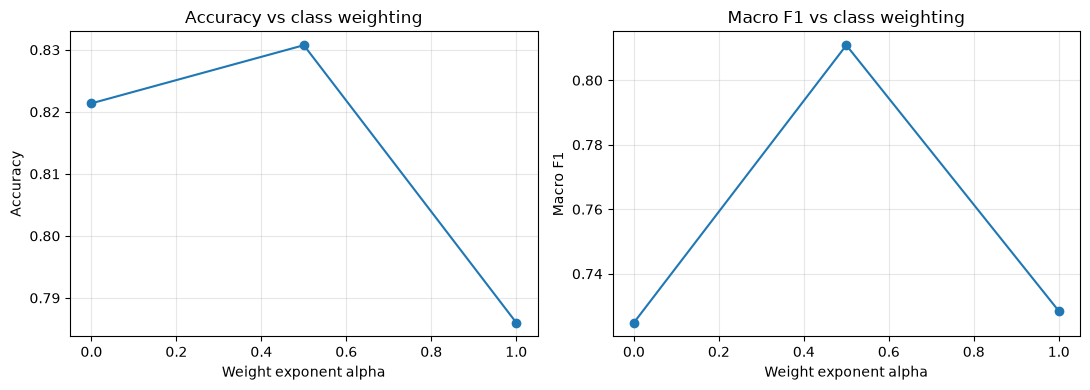

In [6]:

rf_baseline_results = []

for alpha in [0.0, 0.5, 1.0]:
    model = make_rf(
        n_estimators=20,
        max_depth=15,
        min_samples_leaf=5,
        max_features="sqrt",
        alpha=alpha
    )

    _, metrics = evaluate_model(
        f"RF baseline (alpha={alpha})",
        model
    )

    metrics["alpha"] = alpha
    rf_baseline_results.append(metrics)

rf_baseline_df = pd.DataFrame(rf_baseline_results)

display(
    rf_baseline_df[
        ["alpha", "accuracy", "macro_f1",
         "weighted_f1", "train_time_s"]
    ].round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    rf_baseline_df["alpha"],
    rf_baseline_df["accuracy"],
    "o-"
)
axes[0].set_title("Accuracy vs class weighting")
axes[0].set_xlabel("Weight exponent alpha")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)

axes[1].plot(
    rf_baseline_df["alpha"],
    rf_baseline_df["macro_f1"],
    "o-"
)
axes[1].set_title("Macro F1 vs class weighting")
axes[1].set_xlabel("Weight exponent alpha")
axes[1].set_ylabel("Macro F1")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

The initial Random Forest achieves a validation accuracy of 82.14% and a Macro F1-score of 0.7249 without class weighting.

Introducing moderate weighting ($\alpha=0.5$) improves both metrics, reaching 83.07% accuracy and 0.8109 Macro F1. The improvement in Macro F1 is particularly significant (+0.086), indicating that the model performs substantially better across the seven classes rather than simply improving predictions for the most frequent classes.

However, fully balanced weighting ($\alpha=1$) reduces accuracy to 78.60% and Macro F1 to 0.7285. This suggests that placing excessive emphasis on minority classes can degrade the overall balance between precision and recall.

These results demonstrate that class weighting should be treated as a tunable hyperparameter rather than automatically selecting fully balanced weights.

The experiment also illustrates why Macro F1 is more informative than accuracy alone for this imbalanced multiclass problem.



### 1.3. Hyperparameter Optimization

Preliminary experiments indicated that allowing deeper trees and reducing the minimum number of samples per leaf substantially improved performance.

We therefore focus the final hyperparameter search on fully grown trees, with `max_depth=None` and `min_samples_leaf=1`.

We investigate three parameters:

| Parameter | Tested values |
|---|---|
| `n_estimators` | 100, 200, 300 |
| `max_features` | `"sqrt"`, 0.5 |
| Class weighting exponent $\alpha$ | 0, 0.25, 0.5, 0.75 |

The resulting 24 configurations are evaluated using the complete training set and the same validation set.

The objective is to maximize validation Macro F1 while investigating the trade-off between predictive performance and computational cost.


In [9]:
rf_configs = list(product(
    [100, 200, 300],       # n_estimators
    ["sqrt", 0.5],         # max_features
    [0.0, 0.25, 0.5, 0.75] # alpha
))

rf_search_results = []

for i, (n, mf, alpha) in enumerate(rf_configs, start=1):

    model = make_rf(
        n_estimators=n,
        max_depth=None,
        min_samples_leaf=1,
        max_features=mf,
        alpha=alpha
    )

    _, metrics = evaluate_model(
        f"RF_{i}",
        model
    )

    rf_search_results.append({
        "n_estimators": n,
        "max_features": mf,
        "alpha": alpha,
        **metrics
    })

    print(
        f"[{i:02d}/{len(rf_configs)}] "
        f"n={n}, max_features={mf}, alpha={alpha} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Train={metrics['train_time_s']:.1f}s",
        flush=True
    )

rf_search_df = (
    pd.DataFrame(rf_search_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    rf_search_df[
        ["n_estimators", "max_features", "alpha",
         "accuracy", "macro_f1",
         "train_time_s", "predict_time_s"]
    ].round(5)
)

rf_best_params = rf_search_df.iloc[0]

print("\nBest configuration:")
display(rf_best_params)


[01/24] n=100, max_features=sqrt, alpha=0.0 | Macro F1=0.91917 | Train=6.7s
[02/24] n=100, max_features=sqrt, alpha=0.25 | Macro F1=0.92520 | Train=6.8s
[03/24] n=100, max_features=sqrt, alpha=0.5 | Macro F1=0.92816 | Train=6.1s
[04/24] n=100, max_features=sqrt, alpha=0.75 | Macro F1=0.92577 | Train=5.1s
[05/24] n=100, max_features=0.5, alpha=0.0 | Macro F1=0.93846 | Train=12.8s
[06/24] n=100, max_features=0.5, alpha=0.25 | Macro F1=0.94409 | Train=12.3s
[07/24] n=100, max_features=0.5, alpha=0.5 | Macro F1=0.94276 | Train=11.5s
[08/24] n=100, max_features=0.5, alpha=0.75 | Macro F1=0.93884 | Train=10.2s
[09/24] n=200, max_features=sqrt, alpha=0.0 | Macro F1=0.92033 | Train=12.0s
[10/24] n=200, max_features=sqrt, alpha=0.25 | Macro F1=0.92548 | Train=12.6s
[11/24] n=200, max_features=sqrt, alpha=0.5 | Macro F1=0.92656 | Train=11.7s
[12/24] n=200, max_features=sqrt, alpha=0.75 | Macro F1=0.92541 | Train=10.1s
[13/24] n=200, max_features=0.5, alpha=0.0 | Macro F1=0.93966 | Train=24.5s
[1

,n_estimators,max_features,alpha,accuracy,macro_f1,train_time_s,predict_time_s
0,300,0.5,0.25,0.96715,0.94517,35.40243,0.42394
1,200,0.5,0.25,0.96713,0.94414,24.20157,0.30409
2,100,0.5,0.25,0.96697,0.94409,12.31587,0.15348
3,300,0.5,0.50,0.96622,0.94345,32.50816,0.41573
4,200,0.5,0.50,0.96631,0.94312,22.04142,0.27526
5,100,0.5,0.50,0.96572,0.94276,11.46003,0.16534
6,300,0.5,0.00,0.96683,0.93998,35.53628,0.42389
7,200,0.5,0.00,0.96694,0.93966,24.53086,0.28550
8,300,0.5,0.75,0.96335,0.93950,27.18278,0.37819
9,100,0.5,0.75,0.96294,0.93884,10.23984,0.17416



Best configuration:


n_estimators            300
max_features            0.5
alpha                  0.25
model                 RF_22
accuracy           0.967149
macro_f1           0.945166
weighted_f1        0.967134
train_time_s      35.402431
predict_time_s     0.423936
Name: 0, dtype: object

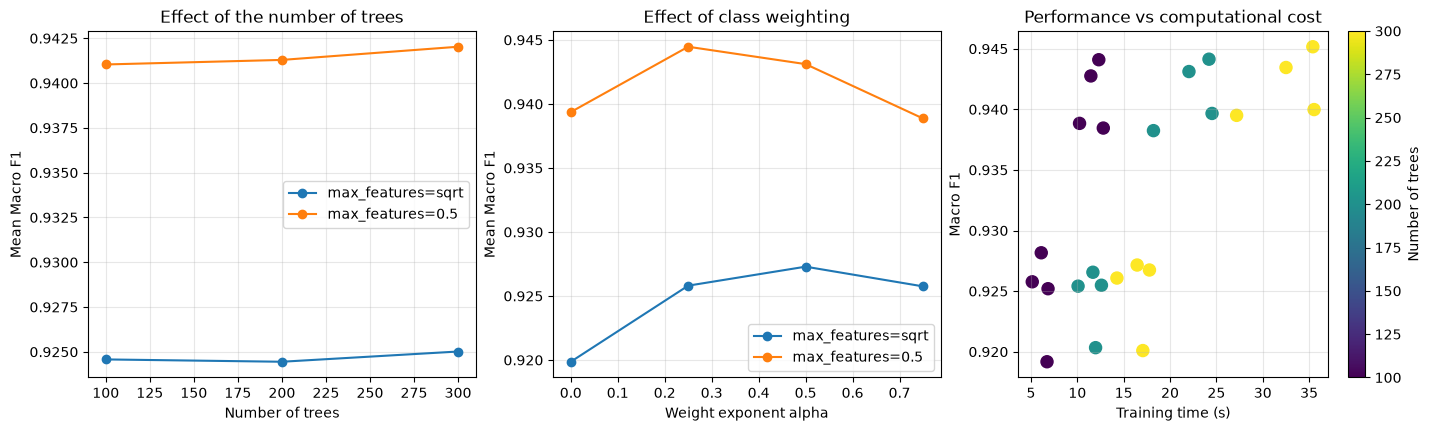

Top configurations:


,n_estimators,max_features,alpha,accuracy,macro_f1,train_time_s
0,300,0.5,0.25,0.96715,0.94517,35.40243
1,200,0.5,0.25,0.96713,0.94414,24.20157
2,100,0.5,0.25,0.96697,0.94409,12.31587
3,300,0.5,0.50,0.96622,0.94345,32.50816
4,200,0.5,0.50,0.96631,0.94312,22.04142
5,100,0.5,0.50,0.96572,0.94276,11.46003
6,300,0.5,0.00,0.96683,0.93998,35.53628
7,200,0.5,0.00,0.96694,0.93966,24.53086
8,300,0.5,0.75,0.96335,0.93950,27.18278
9,100,0.5,0.75,0.96294,0.93884,10.23984


In [10]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Effect of the number of trees
for mf in ["sqrt", 0.5]:
    subset = rf_search_df[
        rf_search_df["max_features"] == mf
    ]
    means = subset.groupby("n_estimators")["macro_f1"].mean()

    axes[0].plot(
        means.index, means.values,
        marker="o", label=f"max_features={mf}"
    )

axes[0].set_title("Effect of the number of trees")
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("Mean Macro F1")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Effect of class weighting
for mf in ["sqrt", 0.5]:
    subset = rf_search_df[
        rf_search_df["max_features"] == mf
    ]
    means = subset.groupby("alpha")["macro_f1"].mean()

    axes[1].plot(
        means.index, means.values,
        marker="o", label=f"max_features={mf}"
    )

axes[1].set_title("Effect of class weighting")
axes[1].set_xlabel("Weight exponent alpha")
axes[1].set_ylabel("Mean Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Computational cost
scatter = axes[2].scatter(
    rf_search_df["train_time_s"],
    rf_search_df["macro_f1"],
    c=rf_search_df["n_estimators"],
    s=75
)

axes[2].set_title("Performance vs computational cost")
axes[2].set_xlabel("Training time (s)")
axes[2].set_ylabel("Macro F1")
axes[2].grid(alpha=0.3)

fig.colorbar(
    scatter, ax=axes[2],
    label="Number of trees"
)

plt.show()

print("Top configurations:")
display(
    rf_search_df.head(10)[
        ["n_estimators", "max_features",
         "alpha", "accuracy", "macro_f1",
         "train_time_s"]
    ].round(5)
)



**Results and discussion.**

The best configuration identified by the targeted benchmark uses:

- 300 trees;
- Unlimited maximum depth;
- `min_samples_leaf=1`;
- `max_features=0.5`;
- Class weighting exponent $\alpha=0.25$.

It achieves **96.71% validation accuracy and 0.94517 Macro F1**, compared with 83.07% accuracy and 0.8109 Macro F1 for the initial weighted baseline.

This represents an improvement of approximately **13.64 percentage points in accuracy** and **0.1343 in Macro F1**.

Three main trends emerge from the hyperparameter search.

**Feature subsampling.** Increasing `max_features` from `"sqrt"` to `0.5` consistently improves performance in the configurations tested. This suggests that considering more candidate features at each split is beneficial for this dataset. However, this also increases computational cost, since more candidate splits need to be evaluated.

**Class weighting.** The best exponent depends on the model configuration. With `max_features=0.5`, $\alpha=0.25$ provides the best results among the tested values, whereas stronger weighting is more competitive when `max_features="sqrt"`. This suggests an interaction between class weighting and the tree construction parameters.

**Number of trees.** Increasing the number of trees provides relatively small improvements compared with the increase in training time:

| Trees | Macro F1 | Training time |
|---|---|---|
| 100 | 0.94409 | 12.32 s |
| 200 | 0.94414 | 24.20 s |
| 300 | 0.94517 | 35.40 s |

The improvement between 100 and 300 trees is only 0.00108 in Macro F1, while training time increases by approximately a factor of three.

Thus, **100 trees offer an attractive performance–cost compromise**, while 300 trees achieve the highest validation Macro F1 among the configurations tested.

The selected configuration is not necessarily globally optimal, since `max_depth` and `min_samples_leaf` were fixed based on preliminary experiments. Nevertheless, the benchmark provides strong evidence that increasing model flexibility and considering more features per split substantially improves performance on Covertype.


Selected Random Forest:
RandomForestClassifier(class_weight={np.int64(1): np.float64(0.7911697371921986),
                                     np.int64(2): np.float64(0.7357147577131893),
                                     np.int64(3): np.float64(1.2343537256122326),
                                     np.int64(4): np.float64(2.3445059957068612),
                                     np.int64(5): np.float64(1.7195801470996168),
                                     np.int64(6): np.float64(1.4785620825455321),
                                     np.int64(7): np.float64(1.4183643481791264)},
                       max_features=0.5, n_estimators=300, n_jobs=-1,
                       random_state=42)

Validation metrics:


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,Random Forest,0.96715,0.94517,0.96713,39.40362,0.49524


              precision    recall  f1-score   support

           1     0.9729    0.9607    0.9667     31776
           2     0.9688    0.9763    0.9725     42495
           3     0.9571    0.9683    0.9626      5363
           4     0.9138    0.9005    0.9071       412
           5     0.9052    0.8989    0.9020      1424
           6     0.9381    0.9374    0.9378      2605
           7     0.9636    0.9711    0.9673      3077

    accuracy                         0.9671     87152
   macro avg     0.9456    0.9447    0.9452     87152
weighted avg     0.9672    0.9671    0.9671     87152



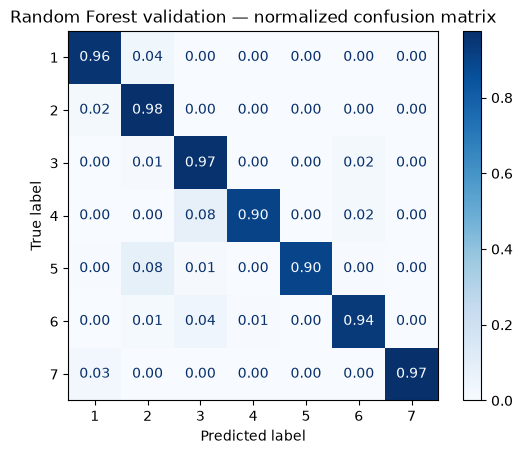

In [11]:

rf_best = make_rf(
    n_estimators=int(rf_best_params["n_estimators"]),
    max_depth=None,
    min_samples_leaf=1,
    max_features=rf_best_params["max_features"],
    alpha=float(rf_best_params["alpha"])
)

rf_best, rf_metrics = evaluate_model(
    "Random Forest",
    rf_best
)

experiment_results["Random Forest"] = rf_metrics.copy()

print("Selected Random Forest:")
print(rf_best)

print("\nValidation metrics:")
display(pd.DataFrame([rf_metrics]).round(5))

show_evaluation(
    rf_best,
    title="Random Forest validation"
)



### 1.4. Effect of PCA

We investigate whether dimensionality reduction improves Random Forest classification.

Three preprocessing strategies are compared:

- **No PCA:** original 54 features.
- **Numerical PCA:** standardization and PCA applied to the 10 numerical variables, while retaining the binary indicators.
- **Global PCA:** standardization and PCA applied to all 54 input features.

For both PCA configurations, the number of components is chosen to retain at least 95% of the explained variance.

The same optimized Random Forest hyperparameters are used in all configurations.

This allows us to evaluate the effect of preprocessing while keeping the classifier architecture fixed.


,preprocessing,accuracy,macro_f1,train_time_s
0,No PCA,0.96715,0.94517,39.40362
1,Numeric PCA (95%),0.93549,0.89751,59.31844
2,Global PCA (95%),0.94718,0.91332,186.34546


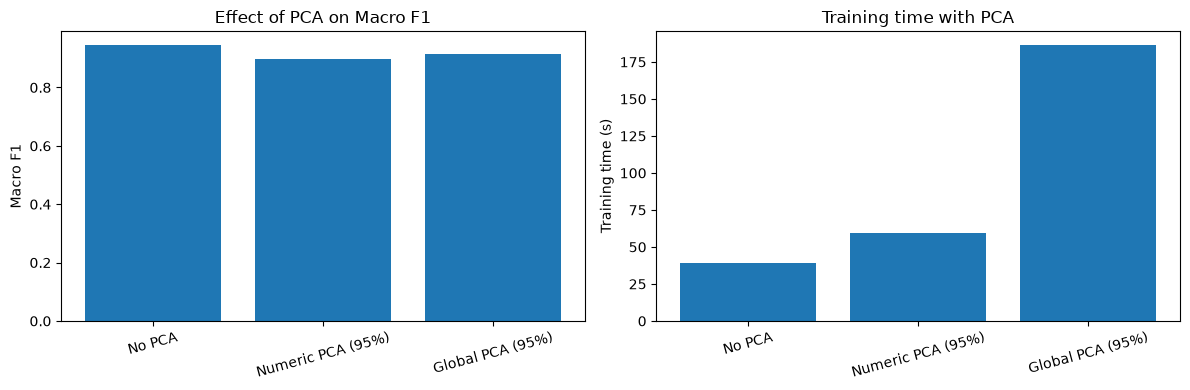

In [14]:

rf_preprocessing_configs = {
    "Numeric PCA (95%)": PreprocessingConfig(
        scaling=True,
        pca="numeric",
        pca_components=0.95
    ),
    "Global PCA (95%)": PreprocessingConfig(
        scaling=True,
        pca="all",
        pca_components=0.95
    )
}

rf_pca_results = [{
    "preprocessing": "No PCA",
    **rf_metrics
}]

for name, config in rf_preprocessing_configs.items():

    pipeline = Pipeline([
        ("preprocessing", build_preprocessor(config)),
        ("classifier", clone(rf_best))
    ])

    _, metrics = evaluate_model(name, pipeline)

    rf_pca_results.append({
        "preprocessing": name,
        **metrics
    })

rf_pca_df = pd.DataFrame(rf_pca_results)

display(
    rf_pca_df[
        ["preprocessing", "accuracy",
         "macro_f1", "train_time_s"]
    ].round(5)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    rf_pca_df["preprocessing"],
    rf_pca_df["macro_f1"]
)
axes[0].set_title("Effect of PCA on Macro F1")
axes[0].set_ylabel("Macro F1")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(
    rf_pca_df["preprocessing"],
    rf_pca_df["train_time_s"]
)
axes[1].set_title("Training time with PCA")
axes[1].set_ylabel("Training time (s)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()



**Results and discussion.**

Both PCA strategies reduce the performance of the optimized Random Forest.

Without PCA, the classifier achieves 96.71% accuracy and 0.94517 Macro F1. Applying PCA to the numerical variables reduces Macro F1 to 0.89751, while applying PCA globally results in 0.91332.

The corresponding accuracy decreases are approximately 3.16 and 2.00 percentage points, respectively.

This suggests that the original feature representation is particularly well suited to the Random Forest.

Unlike distance-based or linear models, decision trees construct axis-aligned partitions of the feature space. PCA replaces the original variables with linear combinations, which can make some decision boundaries more difficult to represent using successive splits.

Furthermore, PCA maximizes retained variance rather than preserving discriminative information. Directions explaining a relatively small proportion of total variance may still contain information useful for distinguishing forest cover classes.

The computational results also favor the original representation:

| Preprocessing | Training time |
|---|---|
| No PCA | 39.4 s |
| Numerical PCA | 59.3 s |
| Global PCA | 186.3 s |

Global PCA is approximately 4.7 times slower than the original representation in the measured end-to-end training pipeline.

A possible explanation is that PCA transforms the original binary and numerical variables into denser, continuous components, increasing the computational cost of evaluating tree splits. The preprocessing itself also introduces additional computation.

Interestingly, earlier experiments with a shallow Random Forest showed a small improvement from global PCA. This suggests that dimensionality reduction may partially compensate for limited model complexity, but becomes unnecessary or detrimental when the Random Forest is sufficiently expressive.

**Conclusion:** For the optimized Random Forest considered here, PCA provides neither a predictive nor a computational advantage. We therefore retain the original 54 features.

These conclusions apply to the tested model architecture; the PCA-based configurations were not optimized independently.



### 1.5. Overfitting and Learning Curves

The optimized Random Forest uses fully grown decision trees, with no maximum depth and potentially only one observation per leaf.

Such a flexible architecture can perfectly classify the training dataset without necessarily generalizing well to unseen observations.

To investigate this behavior, we train the selected architecture on three stratified subsets of the training data: 20%, 50%, and 100%.

For each subset, we compare training and validation Macro F1 and examine how the generalization gap evolves with the training sample size.


,n_samples,train_macro_f1,val_macro_f1,generalization_gap
0,81341,1.0,0.87760,0.12240
1,203354,1.0,0.91927,0.08073
2,406708,1.0,0.94517,0.05483


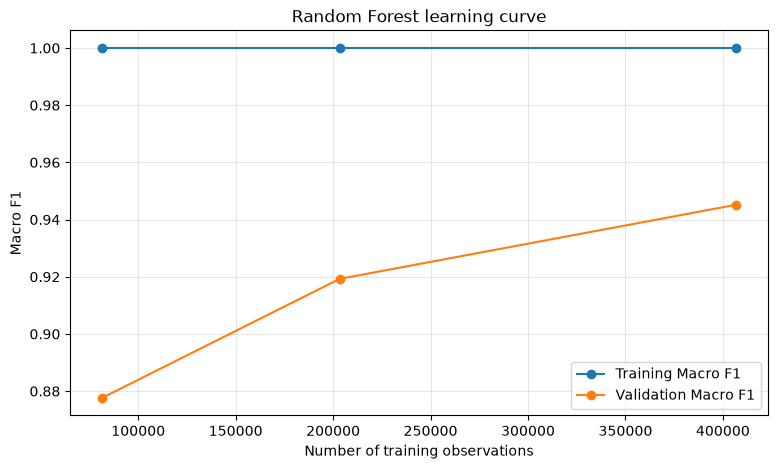

In [15]:


rf_learning_results = []

for fraction in [0.2, 0.5, 1.0]:

    if fraction == 1.0:
        X_sub, y_sub = X_train, y_train
        model = rf_best

    else:
        X_sub, _, y_sub, _ = train_test_split(
            X_train,
            y_train,
            train_size=fraction,
            stratify=y_train,
            random_state=RANDOM_STATE
        )

        model = make_rf(
            n_estimators=int(rf_best_params["n_estimators"]),
            max_depth=None,
            min_samples_leaf=1,
            max_features=rf_best_params["max_features"],
            alpha=float(rf_best_params["alpha"]),
            y_weights=y_sub
        )

        model.fit(X_sub, y_sub)

    train_pred = model.predict(X_sub)
    val_pred = model.predict(X_val)

    train_f1 = f1_score(
        y_sub, train_pred, average="macro"
    )
    val_f1 = f1_score(
        y_val, val_pred, average="macro"
    )

    rf_learning_results.append({
        "n_samples": len(y_sub),
        "train_macro_f1": train_f1,
        "val_macro_f1": val_f1,
        "generalization_gap": train_f1 - val_f1
    })

rf_learning_df = pd.DataFrame(rf_learning_results)

display(rf_learning_df.round(5))

plt.figure(figsize=(9, 5))

plt.plot(
    rf_learning_df["n_samples"],
    rf_learning_df["train_macro_f1"],
    "o-",
    label="Training Macro F1"
)

plt.plot(
    rf_learning_df["n_samples"],
    rf_learning_df["val_macro_f1"],
    "o-",
    label="Validation Macro F1"
)

plt.xlabel("Number of training observations")
plt.ylabel("Macro F1")
plt.title("Random Forest learning curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



**Results and discussion.**

The Random Forest achieves a training Macro F1-score of 1.0 for all three training set sizes.

This is consistent with its high capacity: trees are allowed to grow without a depth restriction and may contain a single observation per leaf.

However, the validation performance varies considerably with training sample size:

| Training observations | Validation Macro F1 | Generalization gap |
|---|---|---|
| 81,341 | 0.87760 | 0.12240 |
| 203,354 | 0.91927 | 0.08073 |
| 406,708 | 0.94517 | 0.05483 |

The validation Macro F1 increases by approximately 0.0676 between the smallest and largest training sets, while the generalization gap decreases by more than half.

This suggests that although the classifier fits the training data perfectly, its generalization improves substantially when more representative examples are available.

The difference between training and validation performance indicates that the model still exhibits a generalization gap. However, this gap should not be interpreted as proof that the selected model is unsuitable: the held-out validation performance remains high and improves consistently with training size.

The learning curve does not appear to have reached a clear plateau. This suggests that additional training data might further improve predictive performance, although this would require additional experiments to confirm.

Overall, the experiment illustrates the effectiveness of combining highly flexible decision trees through an ensemble, while highlighting the importance of training sample size for generalization.



### 1.6. Feature Importance

We investigate which input variables contribute most strongly to the predictions.

Two complementary approaches are considered:

**Impurity-based importance (MDI):** measures the total reduction in impurity attributed to each feature across the forest.

**Permutation importance:** measures the decrease in validation Macro F1 when the values of a feature are randomly shuffled.

MDI is computationally inexpensive but can favor certain variable types. Permutation importance is more directly related to predictive performance, although correlated features can make individual importance values difficult to interpret.

Permutation importance is computed on a stratified validation subsample with three repetitions per feature.


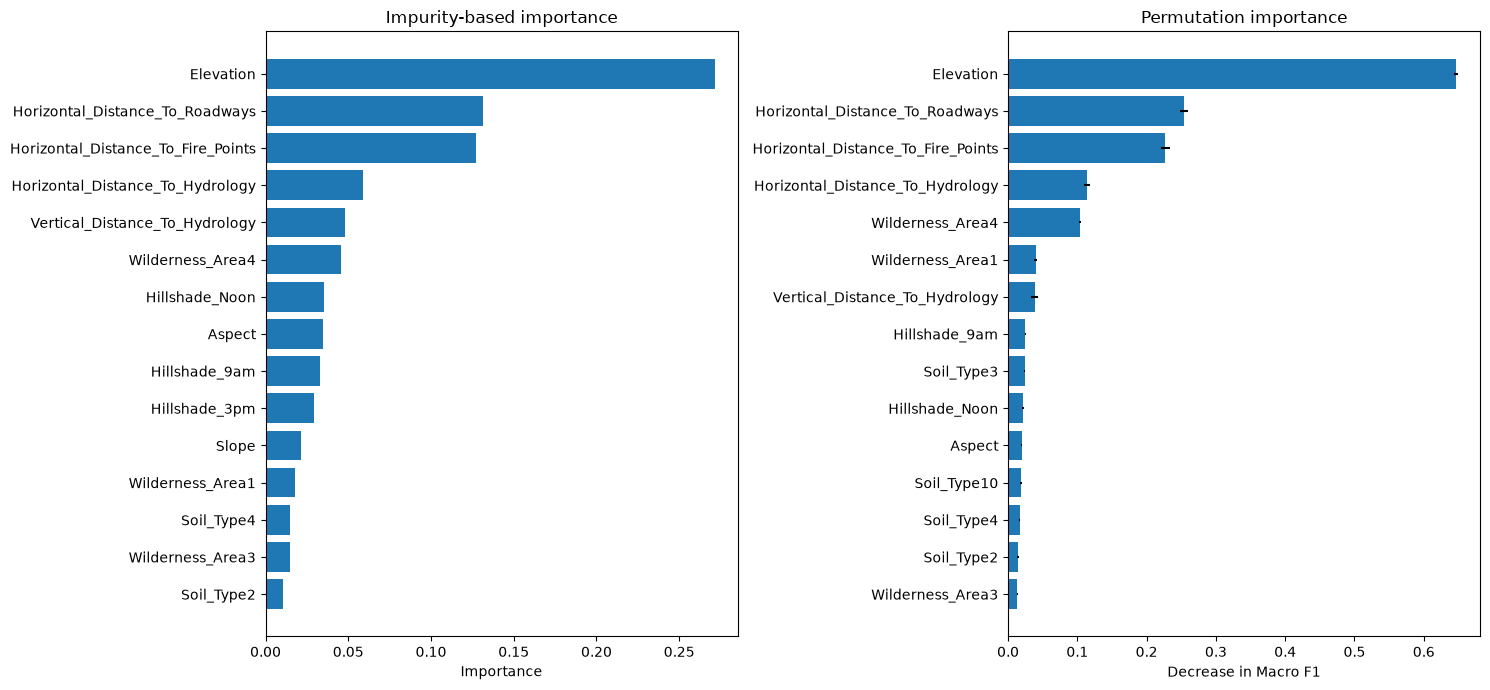

Top 15 features — native importance:


,feature,importance
0,Elevation,0.27164
1,Horizontal_Distance_To_Roadways,0.13114
2,Horizontal_Distance_To_Fire_Points,0.12728
3,Horizontal_Distance_To_Hydrology,0.05900
4,Vertical_Distance_To_Hydrology,0.04818
5,Wilderness_Area4,0.04566
6,Hillshade_Noon,0.03513
7,Aspect,0.03458
8,Hillshade_9am,0.03308
9,Hillshade_3pm,0.02920


Top 15 features — permutation importance:


,feature,importance_mean,importance_std
0,Elevation,0.64622,0.00250
1,Horizontal_Distance_To_Roadways,0.25373,0.00568
2,Horizontal_Distance_To_Fire_Points,0.22665,0.00652
3,Horizontal_Distance_To_Hydrology,0.11397,0.00393
4,Wilderness_Area4,0.10377,0.00093
5,Wilderness_Area1,0.04006,0.00228
6,Vertical_Distance_To_Hydrology,0.03837,0.00478
7,Hillshade_9am,0.02505,0.00098
8,Soil_Type3,0.02400,0.00057
9,Hillshade_Noon,0.02131,0.00125


In [16]:


feature_names = list(X_train.columns)

# Impurity-based importance
rf_native_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": rf_best.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

# Stratified validation subsample
X_perm, _, y_perm, _ = train_test_split(
    X_val,
    y_val,
    train_size=15000,
    stratify=y_val,
    random_state=RANDOM_STATE
)

perm = permutation_importance(
    rf_best,
    X_perm,
    y_perm,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

rf_permutation_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

top_native = rf_native_importance.head(15).iloc[::-1]
top_perm = rf_permutation_importance.head(15).iloc[::-1]

axes[0].barh(
    top_native["feature"],
    top_native["importance"]
)
axes[0].set_title("Impurity-based importance")
axes[0].set_xlabel("Importance")

axes[1].barh(
    top_perm["feature"],
    top_perm["importance_mean"],
    xerr=top_perm["importance_std"]
)
axes[1].set_title("Permutation importance")
axes[1].set_xlabel("Decrease in Macro F1")

plt.tight_layout()
plt.show()

print("Top 15 features — native importance:")
display(rf_native_importance.head(15).round(5))

print("Top 15 features — permutation importance:")
display(rf_permutation_importance.head(15).round(5))



**Results and discussion.**

Both feature importance methods identify a relatively small group of geographical and topographical variables as particularly influential.

**Elevation** is the most important feature by a substantial margin. Its impurity-based importance is approximately 0.272, while permuting its values decreases validation Macro F1 by approximately 0.646.

This indicates that the trained Random Forest relies heavily on elevation to distinguish between forest cover types.

Other important features include:

- Horizontal Distance to Roadways;
- Horizontal Distance to Fire Points;
- Horizontal Distance to Hydrology;
- Wilderness Area 4;
- Vertical Distance to Hydrology.

These results suggest that geographical position and terrain characteristics contain substantial information about forest cover types.

The two methods largely agree on the most influential variables, although some differences appear in their rankings.

For example, Wilderness Area 1 and certain Soil Type indicators receive greater relative importance under permutation importance than under impurity-based importance.

Such differences are expected because the methods measure different quantities:

- MDI measures the contribution of each feature to impurity reduction during tree construction.
- Permutation importance evaluates how strongly the trained model depends on a feature for its validation predictions.

A decrease in Macro F1 of 0.646 for Elevation is particularly large. It suggests that disrupting the relationship between elevation and the other variables severely compromises the classifier.

However, permutation importance is not a causal measure. Randomly permuting a feature can produce unrealistic combinations of geographical variables, particularly when features are correlated. The resulting performance degradation therefore measures model reliance under this artificial perturbation.

Likewise, low individual importance does not imply that a variable is useless. Correlated variables can provide partially redundant information, and one-hot encoded categorical variables may have low individual importance while remaining useful collectively.

Overall, the results support the conclusion that the most informative features are primarily geographical and topographical, while soil and wilderness indicators provide complementary information.

These findings are consistent with the exploratory data analysis conducted in `data_explore.ipynb`.



### 1.7. Feature Selection

The feature importance analysis suggests that some variables contribute much more than others.

We investigate whether a smaller subset of features can achieve similar classification performance while reducing computational cost.

Features are ranked according to their impurity-based importance, computed from the Random Forest trained on the complete training dataset.

We then retrain the same classifier using the top 5, 10, 20, 30, 40, and 54 features.

This is a preliminary feature selection experiment rather than a fully nested feature selection procedure. Its purpose is to investigate the relationship between the number of variables, predictive performance, and training time.


,n_features,accuracy,macro_f1,train_time_s
0,5,0.94545,0.89670,12.18327
1,10,0.95950,0.93365,20.02002
2,20,0.96484,0.93934,26.62741
3,30,0.96620,0.94185,30.39387
4,40,0.96700,0.94380,32.46699
5,54,0.96715,0.94517,39.40362


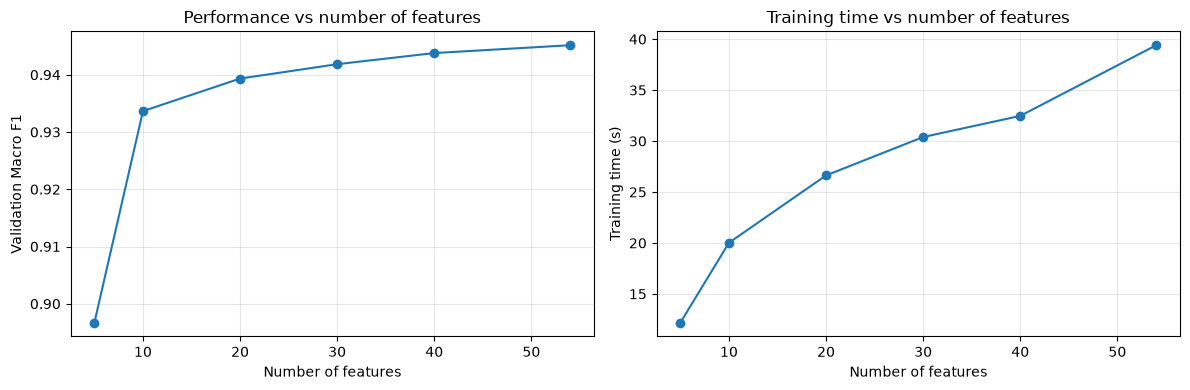

In [17]:

rf_feature_counts = [5, 10, 20, 30, 40, X_train.shape[1]]

ranked_features = rf_native_importance["feature"].tolist()
rf_selection_results = []

for n_features in rf_feature_counts:

    if n_features == X_train.shape[1]:
        rf_selection_results.append({
            "n_features": n_features,
            "accuracy": rf_metrics["accuracy"],
            "macro_f1": rf_metrics["macro_f1"],
            "train_time_s": rf_metrics["train_time_s"]
        })
        continue

    selected = ranked_features[:n_features]

    model = make_rf(
        n_estimators=int(rf_best_params["n_estimators"]),
        max_depth=None,
        min_samples_leaf=1,
        max_features=rf_best_params["max_features"],
        alpha=float(rf_best_params["alpha"])
    )

    start = perf_counter()
    model.fit(X_train[selected], y_train)
    train_time = perf_counter() - start

    predictions = model.predict(X_val[selected])

    rf_selection_results.append({
        "n_features": n_features,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time_s": train_time
    })

rf_selection_df = pd.DataFrame(rf_selection_results)

display(rf_selection_df.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    rf_selection_df["n_features"],
    rf_selection_df["macro_f1"],
    "o-"
)
axes[0].set_title("Performance vs number of features")
axes[0].set_xlabel("Number of features")
axes[0].set_ylabel("Validation Macro F1")
axes[0].grid(alpha=0.3)

axes[1].plot(
    rf_selection_df["n_features"],
    rf_selection_df["train_time_s"],
    "o-"
)
axes[1].set_title("Training time vs number of features")
axes[1].set_xlabel("Number of features")
axes[1].set_ylabel("Training time (s)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

The feature selection experiment shows that much of the predictive information is concentrated in a relatively small subset of variables.

Using only the five most important features yields a Macro F1-score of 0.8967, compared with 0.94517 for the complete 54-feature model.

With 10 features, Macro F1 already reaches 0.93365. Increasing the number of features continues to improve performance, but with diminishing returns.

In particular, the 40-feature model achieves 0.94380 Macro F1, only 0.00137 below the full model.

This suggests that many of the lower-ranked features contribute relatively little additional predictive information when the most influential variables are already available.

Reducing the number of features also decreases training time:

- 10 features: approximately 20.0 seconds;
- 40 features: approximately 32.5 seconds;
- 54 features: approximately 39.4 seconds.

Thus, feature selection offers a trade-off between predictive performance and computational cost.

However, reducing the number of features does not produce a substantial improvement in predictive performance. The highest Macro F1 remains associated with the complete feature set.

For this reason, the final Random Forest retains all 54 original variables.

The feature ranking is based on impurity importance computed using the training data, while the number of retained features is compared on the validation set. Therefore, the observed performance of the selected subsets is exploratory and should not be interpreted as an independently validated feature selection result.



### 1.8. Classification Error Analysis

Despite the high overall classification accuracy, some forest cover classes remain more difficult to distinguish than others.

We analyze the validation confusion matrix in both absolute and normalized terms.

Absolute error counts identify the most frequent misclassifications, while row-normalized confusion matrices allow comparisons between classes with very different frequencies.

We also examine precision, recall, and F1-score for each class, focusing particularly on minority classes.


Classification report:
              precision    recall  f1-score   support

           1     0.9729    0.9607    0.9667     31776
           2     0.9688    0.9763    0.9725     42495
           3     0.9571    0.9683    0.9626      5363
           4     0.9138    0.9005    0.9071       412
           5     0.9052    0.8989    0.9020      1424
           6     0.9381    0.9374    0.9378      2605
           7     0.9636    0.9711    0.9673      3077

    accuracy                         0.9671     87152
   macro avg     0.9456    0.9447    0.9452     87152
weighted avg     0.9672    0.9671    0.9671     87152



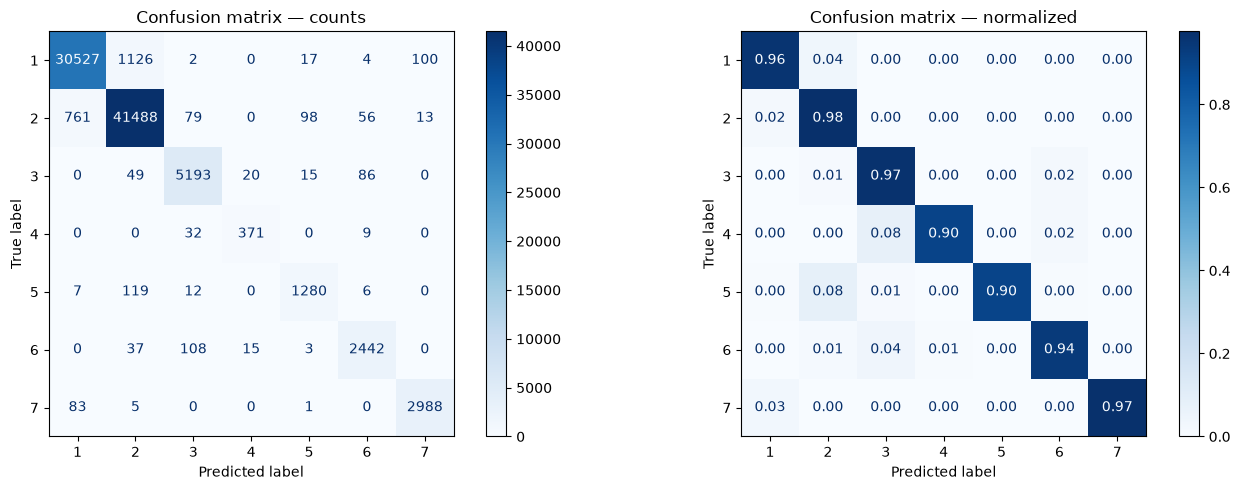

Most frequent classification errors:


,true_class,predicted_class,errors,error_rate
0,1,2,1126,0.03544
1,2,1,761,0.01791
2,5,2,119,0.08357
3,6,3,108,0.04146
4,1,7,100,0.00315
5,2,5,98,0.00231
6,3,6,86,0.01604
7,7,1,83,0.02697
8,2,3,79,0.00186
9,2,6,56,0.00132


Largest class-relative error rates:


,true_class,predicted_class,errors,error_rate
2,5,2,119,0.08357
12,4,3,32,0.07767
3,6,3,108,0.04146
0,1,2,1126,0.03544
7,7,1,83,0.02697
19,4,6,9,0.02184
1,2,1,761,0.01791
6,3,6,86,0.01604
11,6,2,37,0.01420
10,3,2,49,0.00914


In [20]:


rf_val_pred = rf_best.predict(X_val)

print("Classification report:")
print(classification_report(
    y_val, rf_val_pred,
    digits=4,
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_val_pred,
    labels=classes,
    ax=axes[0],
    cmap="Blues",
    values_format="d"
)
axes[0].set_title("Confusion matrix — counts")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_val_pred,
    labels=classes,
    ax=axes[1],
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)
axes[1].set_title("Confusion matrix — normalized")

plt.tight_layout()
plt.show()

cm = confusion_matrix(
    y_val, rf_val_pred, labels=classes
)

rf_confusions = []

for i, true_class in enumerate(classes):
    for j, predicted_class in enumerate(classes):

        if i == j:
            continue

        rf_confusions.append({
            "true_class": true_class,
            "predicted_class": predicted_class,
            "errors": cm[i, j],
            "error_rate": cm[i, j] / cm[i].sum()
        })

rf_confusion_df = (
    pd.DataFrame(rf_confusions)
    .sort_values("errors", ascending=False)
    .reset_index(drop=True)
)

print("Most frequent classification errors:")
display(rf_confusion_df.head(15).round(5))

print("Largest class-relative error rates:")
display(
    rf_confusion_df
    .sort_values("error_rate", ascending=False)
    .head(15)
    .round(5)
)



**Results and discussion.**

The optimized Random Forest achieves strong performance across all seven classes, with class-specific F1-scores ranging from approximately 0.902 to 0.973.

Nevertheless, the confusion matrices reveal several systematic classification difficulties.

**Confusion between the two majority classes.**

The most frequent errors occur between classes 1 and 2:

- 1,126 observations from class 1 are classified as class 2.
- 761 observations from class 2 are classified as class 1.

Together, these represent 1,887 errors. However, classes 1 and 2 also account for the majority of the dataset, so their large absolute error counts do not necessarily indicate poor relative performance.

Indeed, both classes achieve F1-scores above 0.96.

**Difficulties with minority classes.**

Classes 4 and 5 have the lowest F1-scores:

| Class | Precision | Recall | F1 |
|---|---|---|---|
| 4 | 0.9138 | 0.9005 | 0.9071 |
| 5 | 0.9052 | 0.8989 | 0.9020 |

More specifically:

- 8.36% of class 5 observations are incorrectly predicted as class 2.
- 7.77% of class 4 observations are incorrectly predicted as class 3.
- 4.15% of class 6 observations are incorrectly predicted as class 3.

These errors reveal particular pairs of classes that remain difficult to distinguish.

Despite these difficulties, the recall of every class is close to or above 90%. This is noteworthy given the highly imbalanced class distribution.

**Importance of Macro F1.**

The difference between accuracy (0.9671) and Macro F1 (0.9452) reflects the fact that performance is not perfectly uniform across classes.

Accuracy is strongly influenced by the majority classes, whereas Macro F1 assigns equal importance to every class. It therefore provides a more balanced assessment of classification performance.

Overall, the error analysis confirms that the selected Random Forest performs well across the dataset, although certain minority classes remain relatively more difficult to predict.



### 1.9. Discussion and Conclusions

The Random Forest experiments demonstrate the importance of model complexity, class weighting, and feature representation for the Covertype classification problem.

**Hyperparameter optimization.** The main performance improvements came from increasing tree complexity and allowing more features to be considered at each split. The targeted benchmark identified a forest with 300 trees, unlimited depth, `max_features=0.5`, and moderate class weighting ($\alpha=0.25$) as the best tested configuration.

**Class imbalance.** Moderate class weighting improved Macro F1, suggesting that assigning additional importance to minority classes is beneficial. However, stronger weighting did not necessarily produce better performance.

**Dimensionality reduction.** Earlier experiments showed that PCA could improve a relatively shallow Random Forest. However, applying PCA to a more expressive classifier reduced its performance. This suggests that the original feature representation is well suited to the axis-aligned splits of decision trees.

**Generalization.** Fully grown trees achieved nearly perfect training performance, but the validation Macro F1 remained lower. Increasing the training sample size substantially improved validation performance and reduced the generalization gap, indicating that the model benefits from additional data.

**Feature importance and selection.** Elevation and geographical distance variables were especially influential. Feature selection demonstrated that a relatively small subset of the original variables can already achieve strong performance, although the full feature set remained preferable for maximizing predictive performance.

**Classification errors.** Most classes were classified accurately, but minority classes and certain pairs of forest cover types remained more difficult to distinguish. Macro F1 was therefore essential for assessing performance beyond overall accuracy.

Overall, Random Forest provides a strong baseline for comparison with KNN and MLP. The final selected configuration uses all 54 features without PCA.

The comparison between classifiers will be based on the same validation protocol and evaluation metrics, including accuracy, Macro F1, and computational cost.


## 2. K-Nearest Neighbors

### 2.1. Model Overview

K-Nearest Neighbors (KNN) is a non-parametric, instance-based classification algorithm. Unlike Random Forest, it does not explicitly construct a predictive model during training. Instead, it predicts the class of a new observation based on the classes of its $k$ nearest training observations.

KNN is particularly interesting for the Covertype dataset because its performance depends strongly on the geometric representation of the observations.

The main objectives of this section are to:

1. Investigate the importance of feature scaling.
2. Optimize the number of neighbors, distance metric, and neighbor weighting.
3. Evaluate whether PCA improves predictive performance or computational efficiency.
4. Investigate the effect of training dataset size.
5. Analyze classification errors and the computational cost of prediction.

We use **Macro F1** as the primary selection metric, with accuracy and weighted F1 as complementary metrics.

Due to the dataset size and the computational cost of nearest-neighbor searches, initial experiments are performed on stratified subsets of the training and validation data. The selected configuration is subsequently evaluated on the full datasets.

All preprocessing transformations are fitted exclusively on the corresponding training data.


In [24]:
# Initial experimental subsets
KNN_TRAIN_SIZE = 30_000
KNN_VAL_SIZE = 5_000

X_knn_train, _, y_knn_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=KNN_TRAIN_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE
)

X_knn_val, _, y_knn_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=KNN_VAL_SIZE,
    stratify=y_val,
    random_state=RANDOM_STATE
)

print("KNN experimental training set:", X_knn_train.shape)
print("KNN experimental validation set:", X_knn_val.shape)

# Common KNN evaluation helper
def evaluate_knn(name, pipeline, X_tr, y_tr, X_va, y_va):
    start = perf_counter()
    pipeline.fit(X_tr, y_tr)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = pipeline.predict(X_va)
    predict_time = perf_counter() - start

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_va, predictions),
        "macro_f1": f1_score(y_va, predictions, average="macro"),
        "weighted_f1": f1_score(
            y_va, predictions, average="weighted"
        ),
        "train_time_s": train_time,
        "predict_time_s": predict_time
    }

    return pipeline, metrics


KNN experimental training set: (30000, 54)
KNN experimental validation set: (5000, 54)



### 2.2. Baseline and Feature Scaling

KNN is based on distances between observations. For Euclidean distance,

$$
d(x_i,x_j)=\sqrt{\sum_{m=1}^{d}(x_{im}-x_{jm})^2}.
$$

Consequently, features with large numerical ranges can dominate the distance calculation.

The Covertype dataset contains numerical geographical variables measured on different scales, as well as 44 binary indicators representing wilderness areas and soil types.

We compare three preprocessing strategies:

- No scaling.
- Standardization of the 10 numerical features only.
- Standardization of all 54 features.

All experiments use $k=5$, uniform neighbor weighting, and Euclidean distance.

The purpose is to determine how feature scaling changes the geometry of the data and affects classification performance.


,preprocessing,accuracy,macro_f1,train_time_s,predict_time_s
0,No scaling,0.8314,0.72280,0.00567,1.05864
1,Numeric scaling,0.8168,0.68596,0.01834,0.07934
2,Global scaling,0.8148,0.67389,0.02914,0.04302


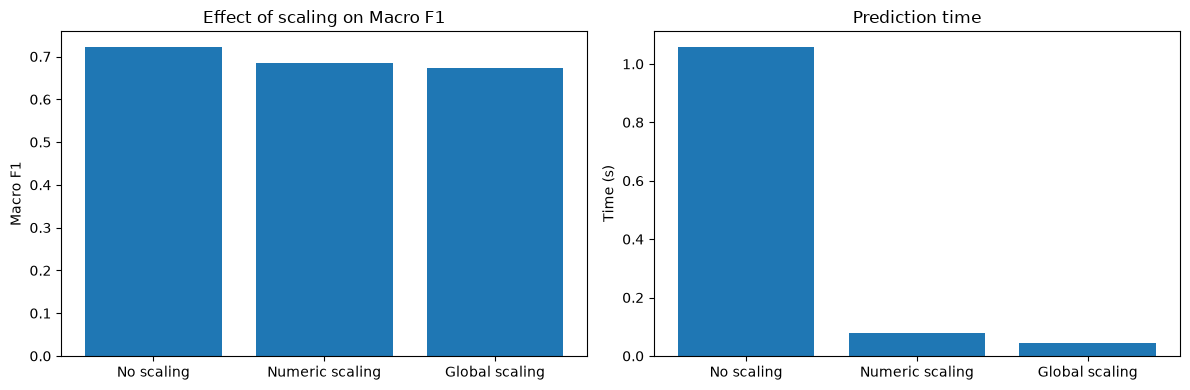

In [25]:

knn_scaling_configs = {
    "No scaling": "passthrough",

    "Numeric scaling": build_preprocessor(
        PreprocessingConfig(
            scaling=True,
            pca="none"
        )
    ),

    "Global scaling": StandardScaler()
}

knn_scaling_results = []

for name, preprocessing in knn_scaling_configs.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessing)
         if preprocessing != "passthrough"
         else "passthrough"),

        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="uniform",
            metric="euclidean",
            algorithm="brute",
            n_jobs=-1
        ))
    ])

    _, metrics = evaluate_knn(
        name,
        pipeline,
        X_knn_train, y_knn_train,
        X_knn_val, y_knn_val
    )

    knn_scaling_results.append({
        "preprocessing": name,
        **metrics
    })

knn_scaling_df = pd.DataFrame(knn_scaling_results)

display(
    knn_scaling_df[
        ["preprocessing", "accuracy", "macro_f1",
         "train_time_s", "predict_time_s"]
    ].round(5)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    knn_scaling_df["preprocessing"],
    knn_scaling_df["macro_f1"]
)
axes[0].set_title("Effect of scaling on Macro F1")
axes[0].set_ylabel("Macro F1")

axes[1].bar(
    knn_scaling_df["preprocessing"],
    knn_scaling_df["predict_time_s"]
)
axes[1].set_title("Prediction time")
axes[1].set_ylabel("Time (s)")

plt.tight_layout()
plt.show()



**Results and discussion.**

Contrary to what might initially be expected for a distance-based classifier, feature standardization does not improve KNN performance in this experiment.

With $k=5$ and Euclidean distance, the results are:

| Preprocessing | Accuracy | Macro F1 |
|---|---|---|
| No scaling | **0.8314** | **0.72280** |
| Numerical scaling | 0.8168 | 0.68596 |
| Global scaling | 0.8148 | 0.67389 |

Standardizing numerical variables reduces Macro F1 by approximately 0.037, while standardizing all 54 features reduces it by approximately 0.049.

Although KNN is sensitive to feature scales, standardization does not necessarily improve predictive performance. In the original Covertype representation, variables with large numerical ranges have greater influence on distances. This implicit weighting may be useful if these variables contain particularly discriminative information.

The feature importance analysis conducted for Random Forest identified Elevation and several geographical distance variables as highly influential. This provides a possible explanation for why retaining the original scales is beneficial.

However, this does not establish that the original scales are optimal. Alternative feature weighting strategies could potentially improve performance further.

Interestingly, scaling substantially reduces prediction time in the measured experiment. The unscaled configuration requires approximately 1.06 seconds, compared with 0.079 seconds for numerical scaling and 0.043 seconds for global scaling.

These differences may partly result from the numerical representation of the transformed data and the computational paths used by the nearest-neighbor implementation. They should not be interpreted as a universal computational advantage of standardization.

For the subsequent hyperparameter search, we retain **the original unscaled features**, since this configuration provides the highest validation Macro F1 among the tested preprocessing strategies.



### 2.3. Hyperparameter Optimization

We investigate three main KNN hyperparameters.

**Number of neighbors ($k$).** Small values of $k$ produce flexible decision boundaries that may be sensitive to noise, whereas larger values result in smoother predictions and may introduce additional bias.

**Neighbor weighting.** With uniform weighting, all selected neighbors contribute equally. Distance weighting assigns greater importance to nearby observations.

**Distance metric.** We compare Euclidean ($L_2$) and Manhattan ($L_1$) distances:

$$
d_2(x,y)=\sqrt{\sum_j(x_j-y_j)^2},
\qquad
d_1(x,y)=\sum_j|x_j-y_j|.
$$

We explore:

| Parameter | Values |
|---|---|
| `n_neighbors` | 1, 3, 5, 11, 21 |
| `weights` | uniform, distance |
| `metric` | Euclidean, Manhattan |

The preprocessing strategy is selected from the preceding scaling experiment.

The resulting 20 configurations are compared using validation Macro F1 and prediction time on the stratified experimental subsets.


In [26]:

best_scaling_name = (
    knn_scaling_df
    .sort_values("macro_f1", ascending=False)
    .iloc[0]["preprocessing"]
)

def make_knn_preprocessor(name):
    if name == "No scaling":
        return "passthrough"
    if name == "Numeric scaling":
        return build_preprocessor(
            PreprocessingConfig(scaling=True, pca="none")
        )
    if name == "Global scaling":
        return StandardScaler()
    raise ValueError(f"Unknown preprocessing: {name}")

knn_configs = list(product(
    [1, 3, 5, 11, 21],
    ["uniform", "distance"],
    ["euclidean", "manhattan"]
))

knn_search_results = []

print("Selected preprocessing:", best_scaling_name)

for i, (k, weights, metric) in enumerate(knn_configs, start=1):

    pipeline = Pipeline([
        ("preprocessing", make_knn_preprocessor(best_scaling_name)),
        ("classifier", KNeighborsClassifier(
            n_neighbors=k,
            weights=weights,
            metric=metric,
            algorithm="brute",
            n_jobs=-1
        ))
    ])

    _, metrics = evaluate_knn(
        f"KNN_{i}",
        pipeline,
        X_knn_train, y_knn_train,
        X_knn_val, y_knn_val
    )

    knn_search_results.append({
        "k": k,
        "weights": weights,
        "metric": metric,
        **metrics
    })

    print(
        f"[{i:02d}/{len(knn_configs)}] "
        f"k={k}, weights={weights}, metric={metric} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Predict={metrics['predict_time_s']:.2f}s",
        flush=True
    )

knn_search_df = (
    pd.DataFrame(knn_search_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

knn_best_params = knn_search_df.iloc[0]

display(knn_search_df.round(5))

print("\nBest KNN configuration:")
display(knn_best_params)


Selected preprocessing: No scaling
[01/20] k=1, weights=uniform, metric=euclidean | Macro F1=0.79008 | Predict=1.05s
[02/20] k=1, weights=uniform, metric=manhattan | Macro F1=0.80615 | Predict=0.93s
[03/20] k=1, weights=distance, metric=euclidean | Macro F1=0.79008 | Predict=1.06s
[04/20] k=1, weights=distance, metric=manhattan | Macro F1=0.80615 | Predict=0.96s
[05/20] k=3, weights=uniform, metric=euclidean | Macro F1=0.74331 | Predict=1.03s
[06/20] k=3, weights=uniform, metric=manhattan | Macro F1=0.76318 | Predict=0.86s
[07/20] k=3, weights=distance, metric=euclidean | Macro F1=0.75921 | Predict=1.01s
[08/20] k=3, weights=distance, metric=manhattan | Macro F1=0.78149 | Predict=0.85s
[09/20] k=5, weights=uniform, metric=euclidean | Macro F1=0.72280 | Predict=1.08s
[10/20] k=5, weights=uniform, metric=manhattan | Macro F1=0.76012 | Predict=0.95s
[11/20] k=5, weights=distance, metric=euclidean | Macro F1=0.76245 | Predict=1.06s
[12/20] k=5, weights=distance, metric=manhattan | Macro F1

,k,weights,metric,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,1,uniform,manhattan,KNN_2,0.8778,0.80615,0.87774,0.00536,0.92525
1,1,distance,manhattan,KNN_4,0.8778,0.80615,0.87774,0.00514,0.95840
2,1,uniform,euclidean,KNN_1,0.8700,0.79008,0.86990,0.00471,1.05360
3,1,distance,euclidean,KNN_3,0.8700,0.79008,0.86990,0.00533,1.06449
4,5,distance,manhattan,KNN_12,0.8710,0.78960,0.87017,0.00447,0.92240
5,3,distance,manhattan,KNN_8,0.8666,0.78149,0.86617,0.00471,0.84664
6,11,distance,manhattan,KNN_16,0.8572,0.76540,0.85546,0.00501,0.93658
7,3,uniform,manhattan,KNN_6,0.8564,0.76318,0.85535,0.00391,0.86445
8,5,distance,euclidean,KNN_11,0.8540,0.76245,0.85306,0.00454,1.05661
9,5,uniform,manhattan,KNN_10,0.8544,0.76012,0.85283,0.00509,0.94728



Best KNN configuration:


k                         1
weights             uniform
metric            manhattan
model                 KNN_2
accuracy             0.8778
macro_f1           0.806151
weighted_f1         0.87774
train_time_s       0.005364
predict_time_s     0.925252
Name: 0, dtype: object

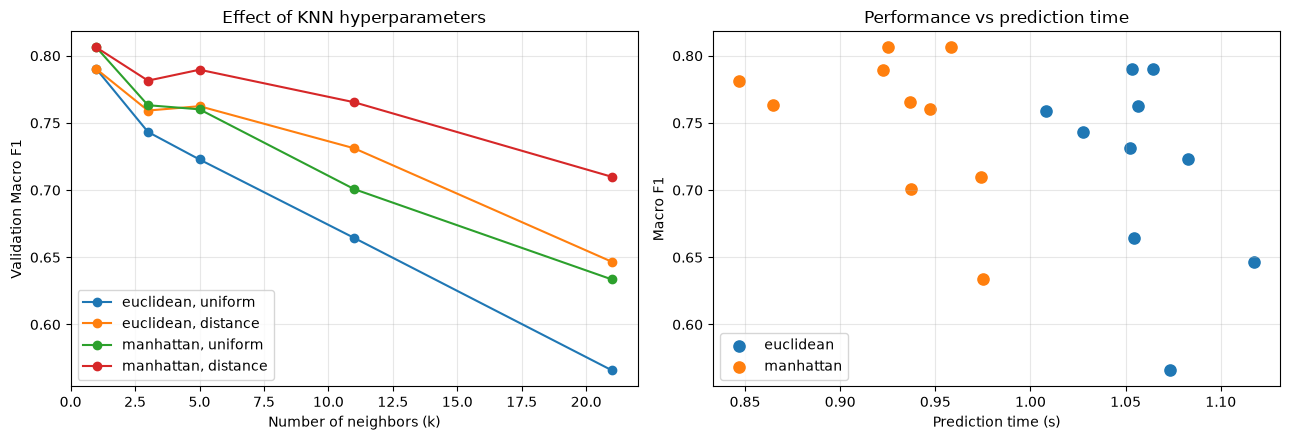

Top 10 configurations:


,k,weights,metric,accuracy,macro_f1,predict_time_s
0,1,uniform,manhattan,0.8778,0.80615,0.92525
1,1,distance,manhattan,0.8778,0.80615,0.95840
2,1,uniform,euclidean,0.8700,0.79008,1.05360
3,1,distance,euclidean,0.8700,0.79008,1.06449
4,5,distance,manhattan,0.8710,0.78960,0.92240
5,3,distance,manhattan,0.8666,0.78149,0.84664
6,11,distance,manhattan,0.8572,0.76540,0.93658
7,3,uniform,manhattan,0.8564,0.76318,0.86445
8,5,distance,euclidean,0.8540,0.76245,1.05661
9,5,uniform,manhattan,0.8544,0.76012,0.94728


In [27]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for metric in ["euclidean", "manhattan"]:
    for weights in ["uniform", "distance"]:

        subset = knn_search_df[
            (knn_search_df["metric"] == metric)
            & (knn_search_df["weights"] == weights)
        ].sort_values("k")

        axes[0].plot(
            subset["k"],
            subset["macro_f1"],
            marker="o",
            label=f"{metric}, {weights}"
        )

axes[0].set_title("Effect of KNN hyperparameters")
axes[0].set_xlabel("Number of neighbors (k)")
axes[0].set_ylabel("Validation Macro F1")
axes[0].legend()
axes[0].grid(alpha=0.3)

for metric in ["euclidean", "manhattan"]:
    subset = knn_search_df[
        knn_search_df["metric"] == metric
    ]

    axes[1].scatter(
        subset["predict_time_s"],
        subset["macro_f1"],
        label=metric,
        s=65
    )

axes[1].set_title("Performance vs prediction time")
axes[1].set_xlabel("Prediction time (s)")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Top 10 configurations:")
display(
    knn_search_df[
        ["k", "weights", "metric",
         "accuracy", "macro_f1",
         "predict_time_s"]
    ].head(10).round(5)
)



**Results and discussion.**

The hyperparameter benchmark identifies the following best configuration:

- Number of neighbors: $k=1$;
- Distance metric: Manhattan ($L_1$);
- Neighbor weighting: uniform;
- Preprocessing: no scaling.

This configuration achieves **87.78% accuracy and 0.80615 Macro F1** on the experimental validation subset.

Several trends emerge from the results.

**Influence of the distance metric.**

Manhattan distance consistently outperforms Euclidean distance for the same values of $k$ and neighbor weighting in the tested configurations.

For $k=1$, Macro F1 increases from 0.79008 with Euclidean distance to 0.80615 with Manhattan distance.

Manhattan distance therefore appears better suited to the original feature representation for this particular dataset and experimental setup.

**Influence of the number of neighbors.**

The highest Macro F1 is obtained with $k=1$. Increasing $k$ generally decreases performance, particularly with uniform neighbor weighting.

For example, using Manhattan distance and uniform weighting:

| Number of neighbors | Macro F1 |
|---|---|
| 1 | **0.80615** |
| 3 | 0.76318 |
| 5 | 0.76012 |
| 11 | 0.70075 |
| 21 | 0.63352 |

This suggests that very local information is particularly valuable for Covertype classification.

Increasing the number of neighbors produces smoother decision boundaries, but it may also introduce observations belonging to different forest cover classes, reducing classification performance.

**Influence of neighbor weighting.**

Distance weighting generally improves performance when $k>1$.

For example, with Manhattan distance and $k=5$, Macro F1 increases from 0.76012 with uniform weighting to 0.78960 with distance weighting.

Giving greater influence to closer observations therefore helps preserve local information when several neighbors are considered.

For $k=1$, uniform and distance weighting produce identical predictions because only one neighbor contributes to the classification.

Overall, the experiments favor a highly local decision rule based on the nearest observation under Manhattan distance.

The selected configuration is subsequently evaluated with different feature representations and larger training datasets.



### 2.4. Effect of PCA and Feature Representation

Unlike Random Forest, KNN relies directly on distances in the feature space. Consequently, dimensionality reduction may improve classification by removing redundant or noisy dimensions.

This experiment compares four preprocessing strategies:

- The best scaling strategy identified previously, without PCA.
- PCA on the 10 numerical features, preserving the binary indicators.
- Global PCA on all 54 features.
- Cyclic encoding of Aspect, combined with the selected scaling strategy.

For PCA, enough components are retained to explain at least 95% of the variance.

The KNN hyperparameters are kept fixed to isolate the effect of preprocessing.

We compare classification performance, preprocessing and fitting time, and prediction time.


,preprocessing,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,Best scaling (no PCA),Best scaling (no PCA),0.8778,0.80615,0.87774,0.00516,0.91733
1,Numeric PCA (95%),Numeric PCA (95%),0.8238,0.72544,0.82379,0.01628,0.13086
2,Global PCA (95%),Global PCA (95%),0.8132,0.71002,0.81320,0.03337,0.10419
3,Cyclic Aspect,Cyclic Aspect,0.8748,0.78072,0.87481,0.02108,0.17141


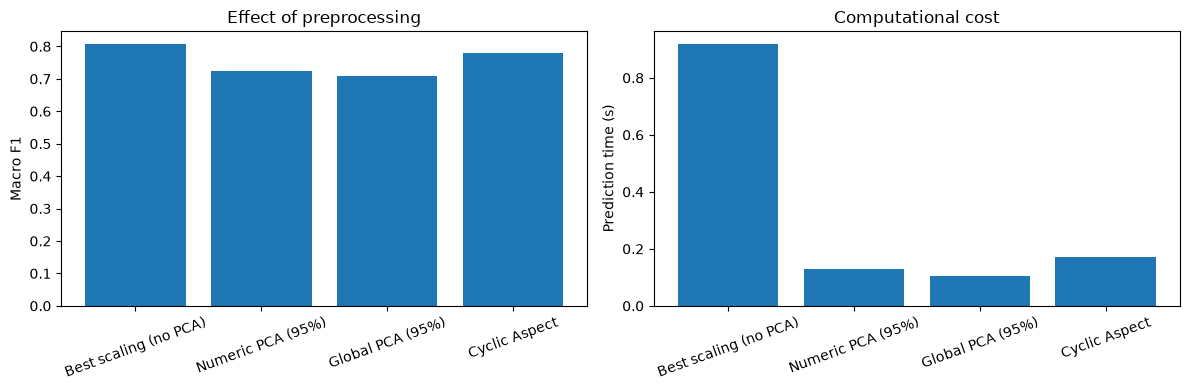

In [28]:

knn_pca_configs = {
    "Best scaling (no PCA)":
        make_knn_preprocessor(best_scaling_name),

    "Numeric PCA (95%)":
        build_preprocessor(
            PreprocessingConfig(
                scaling=True,
                pca="numeric",
                pca_components=0.95
            )
        ),

    "Global PCA (95%)":
        build_preprocessor(
            PreprocessingConfig(
                scaling=True,
                pca="all",
                pca_components=0.95
            )
        ),

    "Cyclic Aspect":
        build_preprocessor(
            PreprocessingConfig(
                scaling=(best_scaling_name != "No scaling"),
                pca="none",
                cyclic_aspect=True
            )
        )
}

knn_pca_results = []

for name, preprocessing in knn_pca_configs.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", KNeighborsClassifier(
            n_neighbors=int(knn_best_params["k"]),
            weights=knn_best_params["weights"],
            metric=knn_best_params["metric"],
            algorithm="brute",
            n_jobs=-1
        ))
    ])

    _, metrics = evaluate_knn(
        name,
        pipeline,
        X_knn_train, y_knn_train,
        X_knn_val, y_knn_val
    )

    knn_pca_results.append({
        "preprocessing": name,
        **metrics
    })

knn_pca_df = pd.DataFrame(knn_pca_results)

display(knn_pca_df.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    knn_pca_df["preprocessing"],
    knn_pca_df["macro_f1"]
)
axes[0].set_ylabel("Macro F1")
axes[0].set_title("Effect of preprocessing")

axes[1].bar(
    knn_pca_df["preprocessing"],
    knn_pca_df["predict_time_s"]
)
axes[1].set_ylabel("Prediction time (s)")
axes[1].set_title("Computational cost")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



**Results and discussion.**

The preprocessing experiments show that neither PCA nor cyclic encoding of Aspect improves the predictive performance of the selected KNN classifier.

The original feature representation achieves the highest Macro F1-score (0.80615).

Applying PCA to the numerical variables reduces Macro F1 to 0.72544, while global PCA further reduces it to 0.71002.

Unlike Random Forest, which constructs axis-aligned partitions, KNN directly relies on distances between observations. PCA changes these distances by projecting the data onto a lower-dimensional space.

Although PCA preserves directions explaining most of the variance, these directions are not necessarily the most discriminative for the target classes. Moreover, the preprocessing configurations also change the scaling of the variables, so the performance differences cannot be attributed exclusively to dimensionality reduction.

Cyclic encoding of Aspect also decreases Macro F1, from 0.80615 to 0.78072.

This transformation correctly represents the periodic nature of orientation angles, but its geometric relevance does not guarantee better classification performance.

**Computational trade-off.**

All three transformations substantially reduce prediction time:

| Preprocessing | Prediction time |
|---|---|
| Original features | 0.917 s |
| Numerical PCA | 0.131 s |
| Global PCA | 0.104 s |
| Cyclic Aspect | 0.171 s |

Global PCA reduces measured prediction time by approximately 89%.

However, this acceleration comes with a substantial loss in Macro F1. In addition, the comparison reflects changes in data representation and potentially in the underlying computational implementation, not only changes in dimensionality.

For the objective of maximizing predictive performance, we therefore retain the original features without PCA or cyclic transformation.

The experiments also illustrate that preprocessing methods should be evaluated empirically rather than assumed to be beneficial based solely on theoretical considerations.



### 2.5. Effect of Training Dataset Size

KNN is an instance-based classifier whose performance and prediction cost depend directly on the number of stored training observations.

We investigate this relationship using eight progressively larger training subsets, ranging from 5,000 observations to the complete training set of 406,708 observations.

The subsets are constructed to be **nested and approximately stratified**, meaning that each smaller training subset is contained in all larger ones, while approximately preserving class proportions. This reduces variability caused by replacing observations between experiments.

The same stratified validation subset of 5,000 observations is used throughout, allowing a direct comparison of predictive performance and inference time.

The selected KNN configuration and preprocessing strategy remain unchanged.

We investigate:

1. How classification performance evolves with the number of training observations.
2. Whether the improvement in Macro F1 begins to saturate.
3. How prediction time scales with the size of the training dataset.
4. The trade-off between predictive performance and computational efficiency.

The resulting curves represent validation performance and inference cost as functions of training dataset size.


   5000 samples | Accuracy=0.74680 | Macro F1=0.62829 | Predict=0.17s
  10000 samples | Accuracy=0.80000 | Macro F1=0.70249 | Predict=0.35s
  20000 samples | Accuracy=0.85440 | Macro F1=0.76137 | Predict=0.62s
  30000 samples | Accuracy=0.88160 | Macro F1=0.80725 | Predict=0.95s
  60000 samples | Accuracy=0.91780 | Macro F1=0.86542 | Predict=1.88s
 120000 samples | Accuracy=0.93780 | Macro F1=0.89764 | Predict=3.90s
 240000 samples | Accuracy=0.95660 | Macro F1=0.93011 | Predict=10.47s
 406708 samples | Accuracy=0.96440 | Macro F1=0.93314 | Predict=23.09s


,n_samples,accuracy,macro_f1,train_time_s,predict_time_s
0,5000,0.7468,0.62829,0.00224,0.17331
1,10000,0.8000,0.70249,0.00227,0.34729
2,20000,0.8544,0.76137,0.00362,0.62409
3,30000,0.8816,0.80725,0.00457,0.95091
4,60000,0.9178,0.86542,0.00855,1.87986
5,120000,0.9378,0.89764,0.01856,3.89904
6,240000,0.9566,0.93011,0.03542,10.47135
7,406708,0.9644,0.93314,0.05401,23.09277


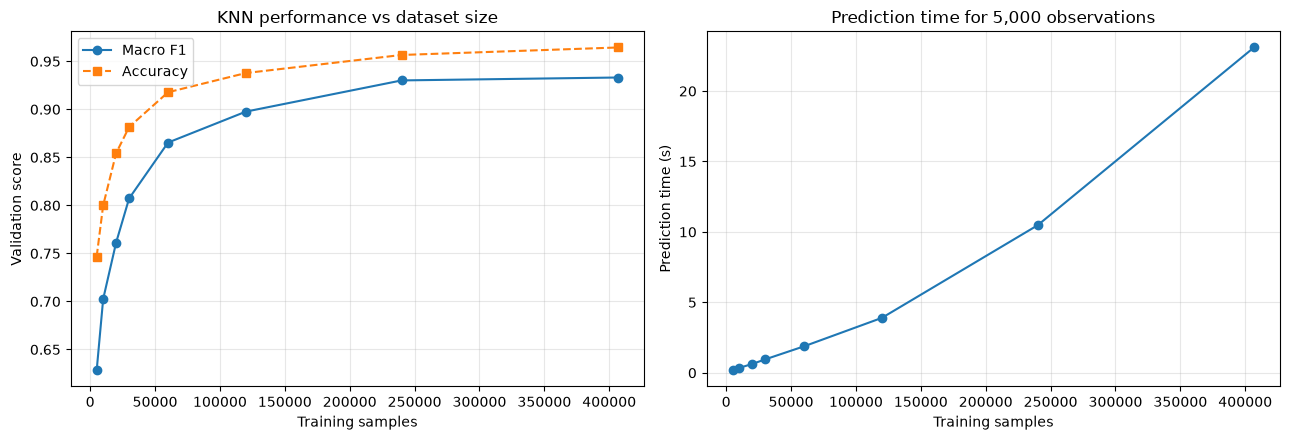

,n_samples,macro_f1,macro_f1_gain,predict_time_s,predict_time_gain
0,5000,0.62829,NaN,0.17331,NaN
1,10000,0.70249,0.07420,0.34729,0.17397
2,20000,0.76137,0.05888,0.62409,0.27681
3,30000,0.80725,0.04588,0.95091,0.32682
4,60000,0.86542,0.05817,1.87986,0.92894
5,120000,0.89764,0.03222,3.89904,2.01918
6,240000,0.93011,0.03248,10.47135,6.57231
7,406708,0.93314,0.00303,23.09277,12.62141


In [34]:

knn_best_preprocessing_name = (
    knn_pca_df
    .sort_values("macro_f1", ascending=False)
    .iloc[0]["preprocessing"]
)

def make_knn_selected():
    if knn_best_preprocessing_name == "Best scaling (no PCA)":
        preprocessing = make_knn_preprocessor(best_scaling_name)
    else:
        preprocessing = knn_pca_configs[knn_best_preprocessing_name]

    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", KNeighborsClassifier(
            n_neighbors=int(knn_best_params["k"]),
            weights=knn_best_params["weights"],
            metric=knn_best_params["metric"],
            algorithm="brute",
            n_jobs=-1
        ))
    ])

knn_train_sizes = [
    5_000, 10_000, 20_000, 30_000,
    60_000, 120_000, 240_000, len(y_train)
]

remaining_indices = np.arange(len(y_train))
selected_indices = np.array([], dtype=int)
knn_subsets = {}
previous_size = 0

for size in knn_train_sizes:
    n_to_add = size - previous_size

    if n_to_add == len(remaining_indices):
        new_indices = remaining_indices
        remaining_indices = np.array([], dtype=int)
    else:
        new_indices, remaining_indices = train_test_split(
            remaining_indices,
            train_size=n_to_add,
            stratify=np.asarray(y_train)[remaining_indices],
            random_state=RANDOM_STATE
        )

    selected_indices = np.concatenate([selected_indices, new_indices])
    knn_subsets[size] = selected_indices.copy()
    previous_size = size

knn_learning_results = []

for n_samples in knn_train_sizes:
    indices = knn_subsets[n_samples]

    X_sub = X_train.iloc[indices]
    y_sub = np.asarray(y_train)[indices]

    model = make_knn_selected()

    _, metrics = evaluate_knn(
        f"KNN_{n_samples}",
        model,
        X_sub, y_sub,
        X_knn_val, y_knn_val
    )

    knn_learning_results.append({
        "n_samples": n_samples,
        **metrics
    })

    print(
        f"{n_samples:>7} samples | "
        f"Accuracy={metrics['accuracy']:.5f} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Predict={metrics['predict_time_s']:.2f}s",
        flush=True
    )

knn_learning_df = pd.DataFrame(knn_learning_results)

display(knn_learning_df[
    ["n_samples", "accuracy", "macro_f1",
     "train_time_s", "predict_time_s"]
].round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    knn_learning_df["n_samples"],
    knn_learning_df["macro_f1"],
    "o-", label="Macro F1"
)
axes[0].plot(
    knn_learning_df["n_samples"],
    knn_learning_df["accuracy"],
    "s--", label="Accuracy"
)
axes[0].set_xlabel("Training samples")
axes[0].set_ylabel("Validation score")
axes[0].set_title("KNN performance vs dataset size")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    knn_learning_df["n_samples"],
    knn_learning_df["predict_time_s"],
    "o-"
)
axes[1].set_xlabel("Training samples")
axes[1].set_ylabel("Prediction time (s)")
axes[1].set_title("Prediction time for 5,000 observations")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

knn_learning_df["macro_f1_gain"] = knn_learning_df["macro_f1"].diff()
knn_learning_df["predict_time_gain"] = knn_learning_df["predict_time_s"].diff()

display(knn_learning_df[
    ["n_samples", "macro_f1", "macro_f1_gain",
     "predict_time_s", "predict_time_gain"]
].round(5))



**Results and discussion.**

The experiments demonstrate that training dataset size has a major influence on KNN classification performance, although the marginal benefits decrease as the dataset grows.

| Training samples | Accuracy | Macro F1 | Prediction time |
|---|---|---|---|
| 5,000 | 0.7468 | 0.62829 | 0.17 s |
| 10,000 | 0.8000 | 0.70249 | 0.35 s |
| 20,000 | 0.8544 | 0.76137 | 0.62 s |
| 30,000 | 0.8816 | 0.80725 | 0.95 s |
| 60,000 | 0.9178 | 0.86542 | 1.88 s |
| 120,000 | 0.9378 | 0.89764 | 3.90 s |
| 240,000 | 0.9566 | 0.93011 | 10.47 s |
| 406,708 | **0.9644** | **0.93314** | **23.09 s** |

All prediction times correspond to the same 5,000 validation observations.

**1. Strong improvement with increasing dataset size**

Increasing the training dataset from 5,000 to 406,708 observations raises Macro F1 from 0.6283 to 0.9331, an improvement of approximately 0.305.

This confirms that KNN benefits considerably from the availability of additional reference observations.

With a single nearest neighbor ($k=1$), classification depends entirely on the label of the closest training observation. Increasing the training dataset size makes it more likely that a validation observation has a nearby reference sample belonging to the correct class.

This is particularly relevant for minority classes, for which larger training datasets provide more examples.

**2. Diminishing returns and emerging performance saturation**

The improvements become progressively smaller at large dataset sizes.

In particular:

- From 60,000 to 120,000 samples, Macro F1 increases by 0.03222.
- From 120,000 to 240,000 samples, Macro F1 increases by 0.03248.
- From 240,000 to 406,708 samples, Macro F1 increases by only 0.00303.

The last increase is particularly small considering that the number of stored observations grows by approximately 69%.

This suggests that the classifier is approaching a performance plateau for the current feature representation and distance metric.

However, the results do not establish a strict saturation point. Additional observations or alternative distance functions could still improve performance.

**3. Computational cost of increasing dataset size**

Prediction time increases substantially as more training observations are stored.

For 5,000 validation predictions, inference time rises from 0.17 seconds with 5,000 training samples to 23.09 seconds with the complete training dataset.

This is consistent with the computational characteristics of brute-force nearest-neighbor search, which requires distances to be evaluated against the stored training observations.

The measured growth is not perfectly linear, particularly for the largest datasets, where memory access, parallelization overhead, and hardware effects may become more significant.

The computational cost is therefore an important limitation of the selected KNN implementation.

**4. Performance–cost trade-off**

The most interesting compromise appears between 120,000 and 240,000 observations.

With 240,000 training samples, the classifier achieves a Macro F1-score of 0.93011 in approximately 10.47 seconds.

Increasing the dataset to 406,708 observations improves Macro F1 to only 0.93314, while prediction time more than doubles to 23.09 seconds.

Thus, the 240,000-sample configuration retains almost all the predictive performance of the full-dataset model while requiring substantially less computation.

Nevertheless, the complete training dataset is retained for the final validation, since the primary objective of the project is to compare the predictive performance of different classifiers using all available training data.

**Conclusion.**

The extended experiment reveals a clear relationship between training dataset size, classification performance, and inference cost.

KNN benefits greatly from additional training data, but the predictive gains eventually become relatively small compared with the increase in computational cost.

The results therefore highlight an important limitation of instance-based classification: increasing the number of stored observations can improve predictions, but also makes inference progressively more expensive.



### 2.6. Full-Dataset Validation

After selecting the KNN hyperparameters and preprocessing strategy using the experimental subsets, we evaluate the selected configuration on the full training and validation sets.

This step is essential to obtain performance estimates comparable to those of the Random Forest.

Because KNN performs nearest-neighbor searches at prediction time, evaluating all 87,152 validation observations against 406,708 training observations is substantially more computationally expensive than the preliminary experiments.

The final configuration is selected before this evaluation. No test observations are used.

The resulting validation metrics are stored for the final comparison with Random Forest and MLP.


In [30]:

knn_best = make_knn_selected()

start = perf_counter()
knn_best.fit(X_train, y_train)
knn_train_time = perf_counter() - start

# Batched prediction to limit memory usage
batch_size = 2000
knn_predictions = []

start = perf_counter()

for i in range(0, len(X_val), batch_size):
    X_batch = X_val.iloc[i:i + batch_size]
    pred = knn_best.predict(X_batch)
    knn_predictions.append(pred)

    print(
        f"Predicted {min(i + batch_size, len(X_val))}"
        f"/{len(X_val)}",
        end="\r",
        flush=True
    )

knn_predict_time = perf_counter() - start
knn_val_pred = np.concatenate(knn_predictions)

knn_metrics = {
    "model": "KNN",
    "accuracy": accuracy_score(y_val, knn_val_pred),
    "macro_f1": f1_score(
        y_val, knn_val_pred, average="macro"
    ),
    "weighted_f1": f1_score(
        y_val, knn_val_pred, average="weighted"
    ),
    "train_time_s": knn_train_time,
    "predict_time_s": knn_predict_time
}

experiment_results["KNN"] = knn_metrics.copy()

print("\nFull KNN validation results:")
display(pd.DataFrame([knn_metrics]).round(5))


Predicted 87152/87152
Full KNN validation results:


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,KNN,0.96528,0.93611,0.96528,0.05348,400.44384



**Results and discussion.**

The selected KNN configuration was evaluated on the complete training and validation datasets:

- Training observations: 406,708;
- Validation observations: 87,152;
- Number of neighbors: $k=1$;
- Distance metric: Manhattan;
- Preprocessing: none.

The model achieves:

| Metric | Value |
|---|---|
| Accuracy | **0.96528** |
| Macro F1 | **0.93611** |
| Weighted F1 | 0.96528 |
| Fitting time | 0.053 s |
| Prediction time | 400.44 s |

These results demonstrate that KNN is highly competitive on Covertype when a sufficiently large training dataset is available.

Compared with the experiment using 120,000 training observations, Macro F1 improves from 0.89689 to 0.93611.

The extended dataset-size experiment also showed that the improvement between 240,000 and 406,708 training samples is relatively small (Macro F1 increasing from 0.93011 to 0.93314 on the 5,000-observation validation subset).

This suggests diminishing returns from increasing the number of stored observations. Nevertheless, the full training dataset remains preferable for the final model comparison, since it achieves the highest measured predictive performance.

The full validation evaluation, performed on 87,152 observations, produces a Macro F1-score of 0.93611. The difference from the 0.93314 observed on the smaller validation subset is consistent with variation between evaluation samples; the two results should not be interpreted as a performance improvement caused by changing the training dataset.


However, the comparison should be interpreted with care because the full-dataset experiment also uses a much larger validation set. The results are therefore not a strictly controlled learning-curve comparison.

**Computational characteristics.**

The model requires almost no fitting time, since training primarily consists of storing the observations.

Prediction, however, requires approximately 400 seconds for the complete validation set.

This corresponds to approximately 4.6 milliseconds per validation observation on the tested hardware and implementation.

The computational cost is therefore concentrated almost entirely at inference time.

**Comparison with Random Forest.**

The optimized Random Forest achieves:

- Accuracy: 0.9671;
- Macro F1: 0.9452.

KNN achieves:

- Accuracy: 0.9653;
- Macro F1: 0.9361.

The difference in accuracy is only approximately 0.18 percentage points, while the difference in Macro F1 is approximately 0.0091.

Thus, KNN achieves predictive performance close to that of the optimized Random Forest, despite using a fundamentally different classification strategy.

However, the high inference cost makes brute-force KNN less attractive when large numbers of predictions must be generated repeatedly.

Overall, the experiment shows that a simple nearest-neighbor classifier can exploit the structure of the Covertype dataset very effectively, provided enough training observations are available.



### 2.7. Classification Error Analysis

We analyze the predictions obtained on the full validation set using the selected KNN configuration.

As for Random Forest, we examine:

- Class-specific precision, recall, and F1-scores.
- Absolute and row-normalized confusion matrices.
- The most frequent misclassifications.
- The largest relative confusion rates.

This allows us to determine whether KNN exhibits similar difficulties to Random Forest, particularly for minority classes, or whether the two classifiers make different types of errors.


KNN classification report:
              precision    recall  f1-score   support

           1     0.9650    0.9658    0.9654     31776
           2     0.9713    0.9703    0.9708     42495
           3     0.9625    0.9657    0.9641      5363
           4     0.8722    0.8617    0.8669       412
           5     0.8802    0.8876    0.8839      1424
           6     0.9423    0.9340    0.9381      2605
           7     0.9612    0.9659    0.9635      3077

    accuracy                         0.9653     87152
   macro avg     0.9364    0.9359    0.9361     87152
weighted avg     0.9653    0.9653    0.9653     87152



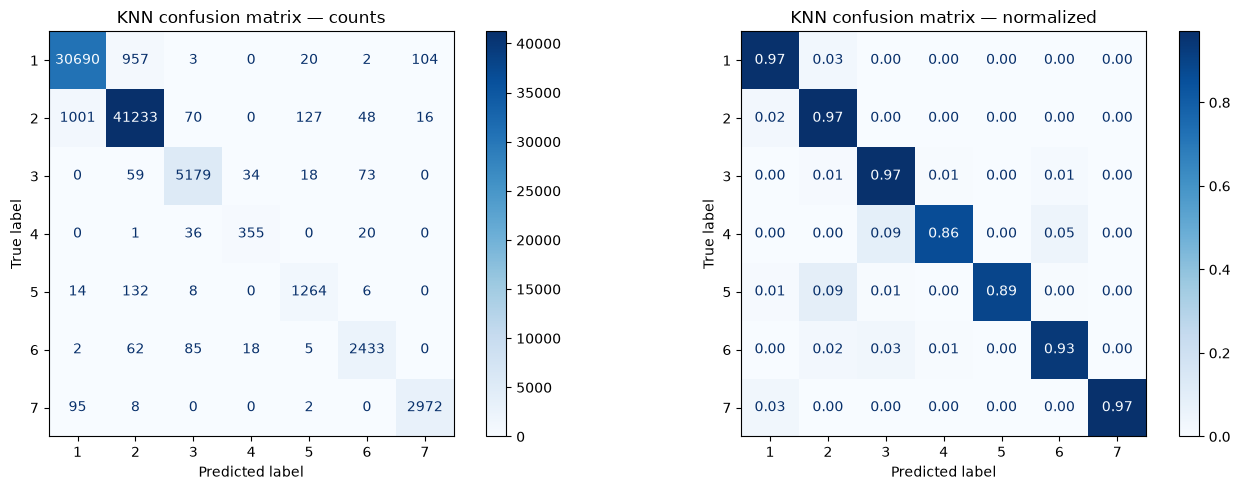

Most frequent errors:


,true_class,predicted_class,errors,error_rate
6,2,1,1001,0.02356
0,1,2,957,0.03012
25,5,2,132,0.09270
9,2,5,127,0.00299
5,1,7,104,0.00327
36,7,1,95,0.03087
32,6,3,85,0.03263
16,3,6,73,0.01361
7,2,3,70,0.00165
31,6,2,62,0.02380


Highest relative error rates:


,true_class,predicted_class,errors,error_rate
25,5,2,132,0.09270
20,4,3,36,0.08738
22,4,6,20,0.04854
32,6,3,85,0.03263
36,7,1,95,0.03087
0,1,2,957,0.03012
31,6,2,62,0.02380
6,2,1,1001,0.02356
16,3,6,73,0.01361
13,3,2,59,0.01100


In [31]:

print("KNN classification report:")
print(classification_report(
    y_val,
    knn_val_pred,
    digits=4,
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_val_pred,
    labels=classes,
    ax=axes[0],
    cmap="Blues",
    values_format="d"
)
axes[0].set_title("KNN confusion matrix — counts")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_val_pred,
    labels=classes,
    normalize="true",
    ax=axes[1],
    cmap="Blues",
    values_format=".2f"
)
axes[1].set_title("KNN confusion matrix — normalized")

plt.tight_layout()
plt.show()

knn_cm = confusion_matrix(
    y_val, knn_val_pred, labels=classes
)

knn_confusions = []

for i, true_class in enumerate(classes):
    for j, predicted_class in enumerate(classes):

        if i == j:
            continue

        knn_confusions.append({
            "true_class": true_class,
            "predicted_class": predicted_class,
            "errors": knn_cm[i, j],
            "error_rate": knn_cm[i, j] / knn_cm[i].sum()
        })

knn_confusion_df = pd.DataFrame(knn_confusions)

print("Most frequent errors:")
display(
    knn_confusion_df
    .sort_values("errors", ascending=False)
    .head(15)
    .round(5)
)

print("Highest relative error rates:")
display(
    knn_confusion_df
    .sort_values("error_rate", ascending=False)
    .head(15)
    .round(5)
)



**Results and discussion.**

The full-dataset KNN achieves strong performance across all seven classes, but some classes remain more difficult to predict.

The class-specific F1-scores are:

| Class | Precision | Recall | F1-score |
|---|---|---|---|
| 1 | 0.9650 | 0.9658 | 0.9654 |
| 2 | 0.9713 | 0.9703 | 0.9708 |
| 3 | 0.9625 | 0.9657 | 0.9641 |
| 4 | 0.8722 | 0.8617 | 0.8669 |
| 5 | 0.8802 | 0.8876 | 0.8839 |
| 6 | 0.9423 | 0.9340 | 0.9381 |
| 7 | 0.9612 | 0.9659 | 0.9635 |

The most frequent errors occur between classes 1 and 2:

- Class 2 predicted as class 1: 1,001 observations;
- Class 1 predicted as class 2: 957 observations.

These two classes dominate the dataset, so relatively small misclassification rates can produce large absolute error counts.

**Minority-class difficulties.**

Classes 4 and 5 exhibit the lowest F1-scores, approximately 0.867 and 0.884 respectively.

In particular:

- 9.27% of class 5 observations are predicted as class 2;
- 8.74% of class 4 observations are predicted as class 3;
- 4.85% of class 4 observations are predicted as class 6.

These errors suggest that certain minority classes have feature-space neighborhoods that overlap with those of other classes.

However, the confusion matrices alone cannot establish the geometric or physical cause of these errors.

**Comparison with Random Forest.**

The overall pattern of errors is similar to that observed for Random Forest: classes 4 and 5 remain the most difficult to distinguish, and classes 1 and 2 generate many errors in absolute terms.

Random Forest performs better on classes 4 and 5, with F1-scores of approximately 0.907 and 0.902, compared with 0.867 and 0.884 for KNN.

Interestingly, KNN performs marginally better on class 3 (0.9641 versus 0.9626) and class 6 (0.9381 versus 0.9378).

Therefore, Random Forest has the better overall Macro F1, but its advantage is not uniform across every class.

This highlights the importance of class-specific evaluation when comparing classifiers on an imbalanced multiclass dataset.



### 2.8. Discussion and Conclusions

The experiments demonstrate that KNN can achieve excellent classification performance on the Covertype dataset, despite its simple and non-parametric formulation.

The selected configuration uses a single nearest neighbor ($k=1$), Manhattan distance, and the original unscaled features.

When evaluated on the complete validation set, it achieves **96.53% accuracy and 0.9361 Macro F1**.

Several conclusions emerge from the experiments.

**Feature representation is crucial.** Contrary to the common expectation that distance-based methods benefit from standardization, both numerical and global scaling reduced performance in our experiments. PCA and cyclic encoding of Aspect also degraded classification performance. The original feature representation therefore appears particularly suitable for the selected KNN configuration.

**Local information is highly predictive.** The best results were obtained with $k=1$, while increasing the number of neighbors generally reduced Macro F1. Manhattan distance consistently outperformed Euclidean distance in the tested configurations. This suggests that very local similarities between observations contain substantial information about forest cover type.

**Dataset size strongly influences performance, but with diminishing returns.** Increasing the number of training observations from 5,000 to 406,708 improves Macro F1 from 0.6283 to 0.9331 on the same 5,000-observation validation subset. However, the gain between 240,000 and 406,708 observations is only 0.0030, while prediction time increases from 10.47 to 23.09 seconds. This suggests an emerging performance plateau and highlights the trade-off between predictive accuracy and inference cost.

**Prediction cost is the main limitation.** Although fitting requires only approximately 0.05 seconds, predicting the complete validation set takes approximately 400 seconds using brute-force Manhattan distance. This makes the approach relatively expensive when repeated inference is required.

**Minority classes remain more difficult.** Classes 4 and 5 exhibit the lowest F1-scores, and their main confusions are similar to those observed for Random Forest. Nevertheless, all classes achieve F1-scores above 0.86.

Compared with the optimized Random Forest, KNN achieves slightly lower accuracy (96.53% versus 96.71%) and Macro F1 (0.9361 versus 0.9452).

The difference in predictive performance is relatively small, demonstrating that nearest-neighbor classification is a strong alternative for this dataset.

However, the computational trade-off is substantially different: Random Forest performs more computation during training, whereas KNN requires extensive nearest-neighbor searches during prediction.

Overall, **KNN provides strong predictive performance but has a significant inference-time disadvantage under the brute-force implementation used here**.

The experiments also have some limitations. Hyperparameters were selected using a subset of 30,000 training observations, and the optimal configuration might differ when using the complete dataset. Furthermore, alternative feature weighting strategies and nearest-neighbor search algorithms were not systematically investigated.

The final comparison with Random Forest and MLP will consider both classification quality and computational cost.



## 3. Multi-Layer Perceptron

### 3.1. Model Overview

A Multi-Layer Perceptron (MLP) is a feedforward neural network composed of successive layers of neurons connected by trainable weights.

Unlike Random Forest and KNN, the MLP learns nonlinear representations through gradient-based optimization.

For a hidden layer with ReLU activation:

$$
h^{(l)} = \operatorname{ReLU}(W^{(l)}h^{(l-1)}+b^{(l)}).
$$

The output layer uses a softmax transformation to produce class probabilities, and the network is trained by minimizing a multiclass cross-entropy loss with optional regularization.

The main objectives of this section are to:

1. Evaluate the influence of feature scaling.
2. Optimize network architecture, regularization, and learning rate.
3. Analyze training convergence and potential overfitting.
4. Investigate the effect of training dataset size.
5. Evaluate the influence of PCA.
6. Analyze classification errors and compare the MLP with Random Forest and KNN.

The primary evaluation metric remains Macro F1, while the neural network is trained using cross-entropy loss.

Initial experiments use stratified training and validation subsets to limit computational cost. The selected model is subsequently trained and evaluated on the full datasets.


In [36]:

MLP_TRAIN_SIZE = 30_000
MLP_VAL_SIZE = 5_000

X_mlp_train, _, y_mlp_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=MLP_TRAIN_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE
)

X_mlp_val, _, y_mlp_val, _ = train_test_split(
    X_val,
    y_val,
    train_size=MLP_VAL_SIZE,
    stratify=y_val,
    random_state=RANDOM_STATE
)

def make_mlp(
    preprocessing="global",
    hidden_layer_sizes=(100,),
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=150
):
    if preprocessing == "none":
        transformer = "passthrough"
    elif preprocessing == "numeric":
        transformer = build_preprocessor(
            PreprocessingConfig(scaling=True, pca="none")
        )
    elif preprocessing == "global":
        transformer = StandardScaler()
    else:
        raise ValueError(f"Unknown preprocessing: {preprocessing}")

    return Pipeline([
        ("preprocessing", transformer),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="relu",
            solver="adam",
            alpha=alpha,
            learning_rate_init=learning_rate_init,
            batch_size=256,
            max_iter=max_iter,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=15,
            random_state=RANDOM_STATE
        ))
    ])


def evaluate_mlp(name, model, X_tr, y_tr, X_va, y_va):
    start = perf_counter()
    model.fit(X_tr, y_tr)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = model.predict(X_va)
    predict_time = perf_counter() - start

    classifier = model.named_steps["classifier"]

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_va, predictions),
        "macro_f1": f1_score(y_va, predictions, average="macro"),
        "weighted_f1": f1_score(
            y_va, predictions, average="weighted"
        ),
        "train_time_s": train_time,
        "predict_time_s": predict_time,
        "epochs": classifier.n_iter_
    }

    return model, metrics



### 3.2. Baseline and Feature Scaling

Neural networks trained using gradient-based optimization are sensitive to the numerical scales of their input features.

Large differences in feature magnitudes can affect gradient magnitudes and make optimization more difficult.

We compare three preprocessing strategies:

- No scaling.
- Standardization of the 10 numerical variables, retaining the binary indicators.
- Standardization of all 54 variables.

All configurations use the same initial MLP architecture:

- One hidden layer with 100 neurons.
- ReLU activation.
- Adam optimizer.
- Initial learning rate of 0.001.
- L2 regularization with $\alpha=10^{-4}$.
- Early stopping based on an internal validation split.

The objective is to identify the most effective preprocessing strategy before optimizing the network architecture.


    none | Macro F1=0.48255 | Epochs=42 | Train=3.1s
 numeric | Macro F1=0.71218 | Epochs=112 | Train=8.6s
  global | Macro F1=0.66350 | Epochs=77 | Train=5.2s


,preprocessing,accuracy,macro_f1,epochs,train_time_s
0,none,0.6720,0.48255,42,3.09298
1,numeric,0.7902,0.71218,112,8.62193
2,global,0.7860,0.66350,77,5.23023


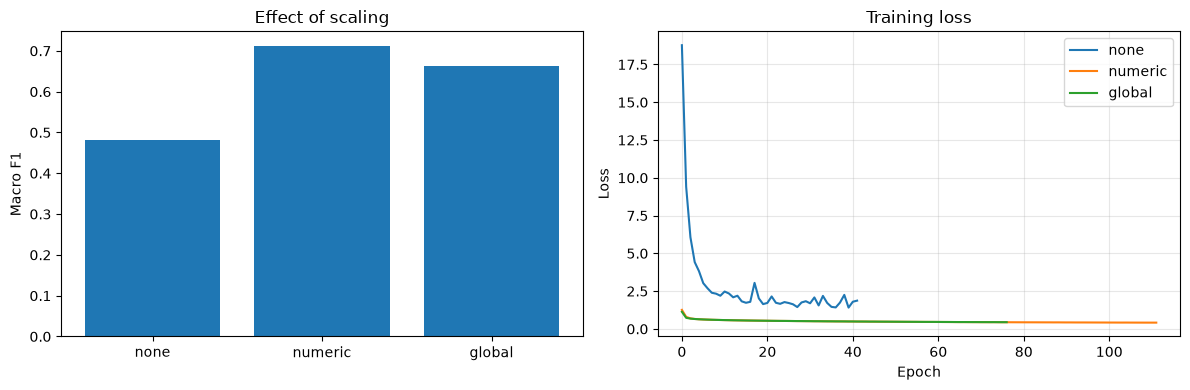

In [39]:

mlp_scaling_results = []
mlp_scaling_models = {}

for preprocessing in ["none", "numeric", "global"]:
    model = make_mlp(preprocessing=preprocessing)

    model, metrics = evaluate_mlp(
        f"MLP_{preprocessing}",
        model,
        X_mlp_train, y_mlp_train,
        X_mlp_val, y_mlp_val
    )

    mlp_scaling_models[preprocessing] = model
    mlp_scaling_results.append({
        "preprocessing": preprocessing,
        **metrics
    })

    print(
        f"{preprocessing:>8} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Epochs={metrics['epochs']} | "
        f"Train={metrics['train_time_s']:.1f}s",
        flush=True
    )

mlp_scaling_df = pd.DataFrame(mlp_scaling_results)

display(mlp_scaling_df[
    ["preprocessing", "accuracy", "macro_f1",
     "epochs", "train_time_s"]
].round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    mlp_scaling_df["preprocessing"],
    mlp_scaling_df["macro_f1"]
)
axes[0].set_title("Effect of scaling")
axes[0].set_ylabel("Macro F1")

for name, model in mlp_scaling_models.items():
    loss = model.named_steps["classifier"].loss_curve_
    axes[1].plot(loss, label=name)

axes[1].set_title("Training loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

Feature scaling has a substantial influence on MLP classification performance.

Without scaling, the baseline network achieves only 67.20% accuracy and 0.48255 Macro F1. Standardizing the numerical variables increases these scores to 79.02% and 0.71218, respectively.

This represents an improvement of approximately 0.230 in Macro F1, demonstrating the importance of appropriate input scaling for gradient-based optimization.

The training loss curves also reveal differences in convergence. Without scaling, the model stops after 42 epochs, whereas numerical scaling allows training to continue for 112 epochs.

One possible explanation is that the original input variables have very different numerical magnitudes, making optimization with a fixed learning rate more difficult. Standardization provides more comparable input scales and can improve the conditioning of the optimization problem.

Interestingly, standardizing all 54 variables produces a lower Macro F1-score (0.66350) than standardizing only the numerical features (0.71218).

The dataset contains 44 binary indicators representing wilderness areas and soil types. Standardizing these indicators changes their relative influence, potentially assigning large standardized values to rare categories.

This may explain why global scaling is less effective, although the experiment does not isolate this mechanism directly.

**Conclusion:** Standardizing the 10 numerical variables while preserving the original binary indicators is the best preprocessing strategy among those tested for the baseline MLP.



### 3.3. Hyperparameter Optimization

We investigate three main hyperparameters influencing MLP performance.

**Network architecture.** The number and size of hidden layers determine the capacity of the network to represent complex nonlinear relationships.

**L2 regularization.** The parameter `alpha` penalizes large weights and can help limit overfitting.

**Learning rate.** The initial learning rate controls the magnitude of parameter updates during optimization and affects convergence speed and stability.

We consider:

| Parameter | Candidate values |
|---|---|
| Hidden layers | (64,), (128,), (256,), (128, 64), (256, 128) |
| L2 regularization | 0.0001, 0.001, 0.01 |
| Initial learning rate | 0.0005, 0.001, 0.003 |

We evaluate 12 sampled combinations using the best preprocessing strategy from the scaling experiment.

The models use ReLU activations, the Adam optimizer, and early stopping. The primary selection criterion is validation Macro F1.

We also record training time and the number of epochs to investigate the relationship between model complexity, convergence, and predictive performance.


#### Additional Experiment — Network Architecture

The initial hyperparameter search jointly varies network architecture, regularization, and learning rate. Consequently, it does not isolate the effect of network depth and width.

We complement this search with a controlled architecture benchmark, keeping the other hyperparameters fixed at the values selected previously.

We investigate 11 architectures with one, two, or three hidden layers:

| Hidden layers | Architectures |
|---|---|
| 1 | (64,), (128,), (256,), (512,) |
| 2 | (64, 64), (128, 128), (256, 128), (256, 256) |
| 3 | (64, 64, 64), (128, 128, 128), (256, 128, 64) |

The models are trained on 120,000 stratified training observations and evaluated on the same external validation subset of 5,000 observations.

We compare accuracy, Macro F1, training time, number of epochs, and number of trainable parameters.

By keeping the learning rate, regularization, and preprocessing fixed, this experiment aims to better isolate the influence of network architecture.



In [40]:

mlp_best_scaling = (
    mlp_scaling_df
    .sort_values("macro_f1", ascending=False)
    .iloc[0]["preprocessing"]
)

mlp_param_space = {
    "hidden_layer_sizes": [
        (64,), (128,), (256,),
        (128, 64), (256, 128)
    ],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.0005, 0.001, 0.003]
}

mlp_configs = list(ParameterSampler(
    mlp_param_space,
    n_iter=12,
    random_state=RANDOM_STATE
))

mlp_search_results = []
mlp_search_models = {}

for i, params in enumerate(mlp_configs, start=1):
    model = make_mlp(
        preprocessing=mlp_best_scaling,
        max_iter=200,
        **params
    )

    model, metrics = evaluate_mlp(
        f"MLP_{i}",
        model,
        X_mlp_train, y_mlp_train,
        X_mlp_val, y_mlp_val
    )

    mlp_search_models[i] = model
    mlp_search_results.append({
        "experiment": i,
        **params,
        **metrics
    })

    print(
        f"[{i:02d}/{len(mlp_configs)}] "
        f"Layers={params['hidden_layer_sizes']} | "
        f"alpha={params['alpha']} | "
        f"lr={params['learning_rate_init']} | "
        f"F1={metrics['macro_f1']:.5f} | "
        f"Epochs={metrics['epochs']}",
        flush=True
    )

mlp_search_df = (
    pd.DataFrame(mlp_search_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

mlp_best_params = mlp_search_df.iloc[0]
mlp_best_experiment = int(mlp_best_params["experiment"])

display(mlp_search_df[
    ["experiment", "hidden_layer_sizes", "alpha",
     "learning_rate_init", "accuracy", "macro_f1",
     "epochs", "train_time_s"]
].round(5))

print("Selected configuration:")
display(mlp_best_params)


[01/12] Layers=(128, 64) | alpha=0.01 | lr=0.0005 | F1=0.72769 | Epochs=136
[02/12] Layers=(128, 64) | alpha=0.001 | lr=0.001 | F1=0.73144 | Epochs=97
[03/12] Layers=(128, 64) | alpha=0.001 | lr=0.003 | F1=0.75802 | Epochs=119
[04/12] Layers=(256, 128) | alpha=0.01 | lr=0.001 | F1=0.77806 | Epochs=112
[05/12] Layers=(128,) | alpha=0.01 | lr=0.003 | F1=0.72985 | Epochs=81
[06/12] Layers=(128, 64) | alpha=0.01 | lr=0.003 | F1=0.76715 | Epochs=100
[07/12] Layers=(128,) | alpha=0.0001 | lr=0.001 | F1=0.67800 | Epochs=74
[08/12] Layers=(256, 128) | alpha=0.0001 | lr=0.0005 | F1=0.74162 | Epochs=120
[09/12] Layers=(256,) | alpha=0.0001 | lr=0.003 | F1=0.73616 | Epochs=78
[10/12] Layers=(128,) | alpha=0.0001 | lr=0.0005 | F1=0.68597 | Epochs=125
[11/12] Layers=(256,) | alpha=0.0001 | lr=0.0005 | F1=0.72395 | Epochs=185
[12/12] Layers=(128, 64) | alpha=0.001 | lr=0.0005 | F1=0.73796 | Epochs=107


,experiment,hidden_layer_sizes,alpha,learning_rate_init,accuracy,macro_f1,epochs,train_time_s
0,4,"(256, 128)",0.0100,0.0010,0.8376,0.77806,112,32.76995
1,6,"(128, 64)",0.0100,0.0030,0.8362,0.76715,100,12.22538
2,3,"(128, 64)",0.0010,0.0030,0.8346,0.75802,119,15.22034
3,8,"(256, 128)",0.0001,0.0005,0.8318,0.74162,120,36.38747
4,12,"(128, 64)",0.0010,0.0005,0.8172,0.73796,107,12.02775
5,9,"(256,)",0.0001,0.0030,0.8242,0.73616,78,12.75153
6,2,"(128, 64)",0.0010,0.0010,0.8220,0.73144,97,11.42509
7,5,"(128,)",0.0100,0.0030,0.8044,0.72985,81,6.70655
8,1,"(128, 64)",0.0100,0.0005,0.8196,0.72769,136,16.89574
9,11,"(256,)",0.0001,0.0005,0.8082,0.72395,185,28.15196


Selected configuration:


experiment                     4
learning_rate_init         0.001
hidden_layer_sizes    (256, 128)
alpha                       0.01
model                      MLP_4
accuracy                  0.8376
macro_f1                0.778055
weighted_f1             0.837679
train_time_s           32.769951
predict_time_s          0.009966
epochs                       112
Name: 0, dtype: object

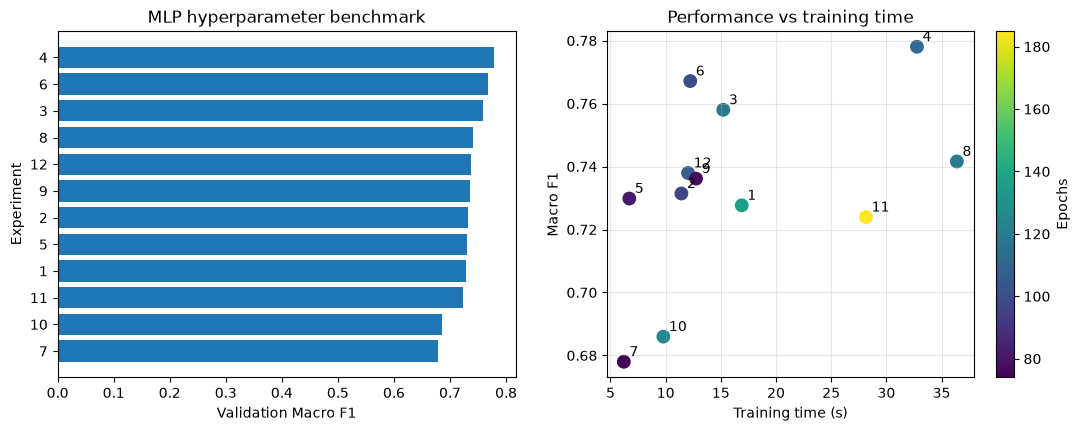

In [43]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ranked = mlp_search_df.sort_values("macro_f1")

axes[0].barh(
    ranked["experiment"].astype(str),
    ranked["macro_f1"]
)
axes[0].set_title("MLP hyperparameter benchmark")
axes[0].set_xlabel("Validation Macro F1")
axes[0].set_ylabel("Experiment")

scatter = axes[1].scatter(
    mlp_search_df["train_time_s"],
    mlp_search_df["macro_f1"],
    c=mlp_search_df["epochs"],
    s=80
)

for _, row in mlp_search_df.iterrows():
    axes[1].annotate(
        str(int(row["experiment"])),
        (row["train_time_s"], row["macro_f1"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

axes[1].set_title("Performance vs training time")
axes[1].set_xlabel("Training time (s)")
axes[1].set_ylabel("Macro F1")
axes[1].grid(alpha=0.3)

fig.colorbar(scatter, ax=axes[1], label="Epochs")

plt.show()


In [50]:

mlp_architectures = [
    (64,), (128,), (256,), (512,),
    (64, 64), (128, 128), (256, 128), (256, 256),
    (64, 64, 64), (128, 128, 128), (256, 128, 64)
]

X_mlp_arch, _, y_mlp_arch, _ = train_test_split(
    X_train,
    y_train,
    train_size=120_000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

mlp_arch_results = []
mlp_arch_models = {}

for i, architecture in enumerate(mlp_architectures, start=1):
    model = make_mlp(
        preprocessing=mlp_best_scaling,
        hidden_layer_sizes=architecture,
        alpha=float(mlp_best_params["alpha"]),
        learning_rate_init=float(mlp_best_params["learning_rate_init"]),
        max_iter=250
    )

    model, metrics = evaluate_mlp(
        f"MLP_arch_{i}",
        model,
        X_mlp_arch, y_mlp_arch,
        X_mlp_val, y_mlp_val
    )

    classifier = model.named_steps["classifier"]
    n_parameters = sum(
        w.size + b.size
        for w, b in zip(classifier.coefs_, classifier.intercepts_)
    )

    mlp_arch_models[i] = model
    mlp_arch_results.append({
        "experiment": i,
        "architecture": architecture,
        "n_layers": len(architecture),
        "n_parameters": n_parameters,
        **metrics
    })

    print(
        f"[{i:02d}/{len(mlp_architectures)}] "
        f"Architecture={architecture} | "
        f"Parameters={n_parameters:,} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Epochs={metrics['epochs']} | "
        f"Train={metrics['train_time_s']:.1f}s",
        flush=True
    )

mlp_arch_df = (
    pd.DataFrame(mlp_arch_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(mlp_arch_df[
    ["experiment", "architecture", "n_layers",
     "n_parameters", "accuracy", "macro_f1",
     "epochs", "train_time_s"]
].round(5))


[01/11] Architecture=(64,) | Parameters=3,975 | Macro F1=0.74407 | Epochs=151 | Train=33.2s
[02/11] Architecture=(128,) | Parameters=7,943 | Macro F1=0.77754 | Epochs=115 | Train=38.4s
[03/11] Architecture=(256,) | Parameters=15,879 | Macro F1=0.79620 | Epochs=121 | Train=75.8s
[04/11] Architecture=(512,) | Parameters=31,751 | Macro F1=0.81939 | Epochs=92 | Train=160.7s
[05/11] Architecture=(64, 64) | Parameters=8,135 | Macro F1=0.82216 | Epochs=159 | Train=57.4s
[06/11] Architecture=(128, 128) | Parameters=24,455 | Macro F1=0.83210 | Epochs=85 | Train=54.3s
[07/11] Architecture=(256, 128) | Parameters=47,879 | Macro F1=0.83662 | Epochs=105 | Train=145.0s
[08/11] Architecture=(256, 256) | Parameters=81,671 | Macro F1=0.86645 | Epochs=129 | Train=279.4s
[09/11] Architecture=(64, 64, 64) | Parameters=12,295 | Macro F1=0.82178 | Epochs=112 | Train=75.2s
[10/11] Architecture=(128, 128, 128) | Parameters=40,967 | Macro F1=0.88371 | Epochs=167 | Train=225.4s
[11/11] Architecture=(256, 128, 6

,experiment,architecture,n_layers,n_parameters,accuracy,macro_f1,epochs,train_time_s
0,10,"(128, 128, 128)",3,40967,0.9116,0.88371,167,225.43862
1,11,"(256, 128, 64)",3,55687,0.9136,0.87964,127,239.09579
2,8,"(256, 256)",2,81671,0.9066,0.86645,129,279.37792
3,7,"(256, 128)",2,47879,0.8958,0.83662,105,145.04789
4,6,"(128, 128)",2,24455,0.8872,0.83210,85,54.30857
5,5,"(64, 64)",2,8135,0.8658,0.82216,159,57.39212
6,9,"(64, 64, 64)",3,12295,0.8798,0.82178,112,75.21487
7,4,"(512,)",1,31751,0.8684,0.81939,92,160.73948
8,3,"(256,)",1,15879,0.8580,0.79620,121,75.83876
9,2,"(128,)",1,7943,0.8418,0.77754,115,38.35940


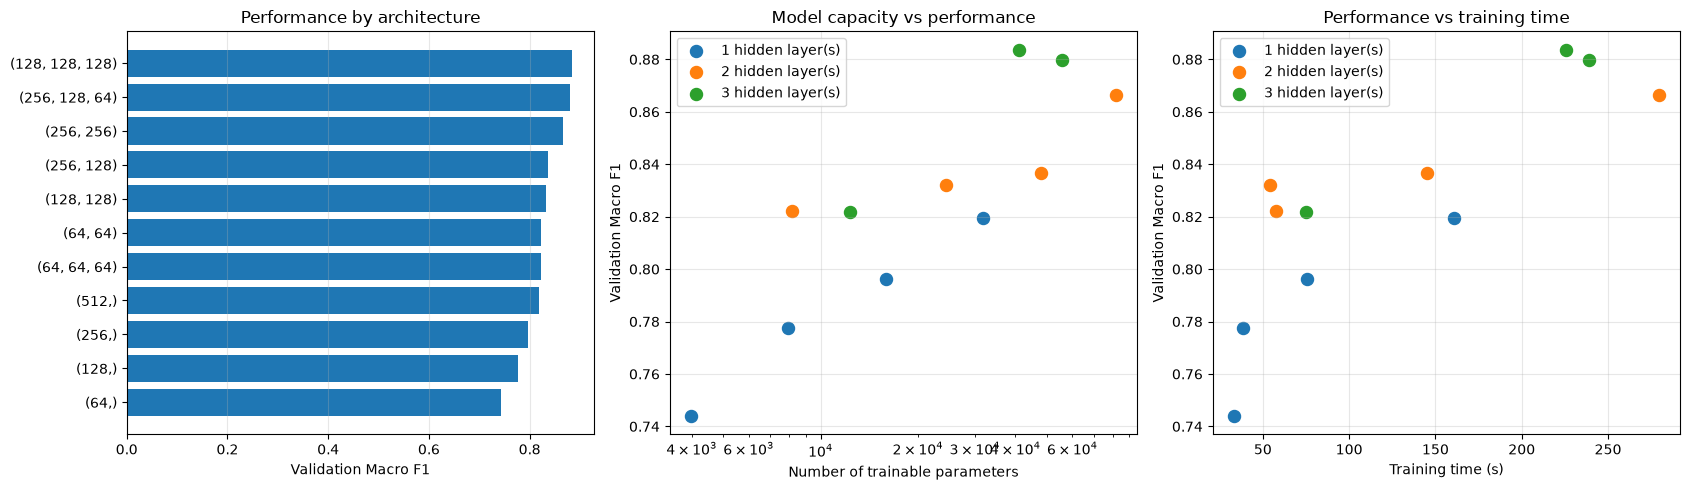

Best architecture for each depth:


,n_layers,architecture,n_parameters,macro_f1,train_time_s
0,1,"(512,)",31751,0.81939,160.73948
1,2,"(256, 256)",81671,0.86645,279.37792
2,3,"(128, 128, 128)",40967,0.88371,225.43862


In [51]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ranked = mlp_arch_df.sort_values("macro_f1")

axes[0].barh(
    ranked["architecture"].astype(str),
    ranked["macro_f1"]
)
axes[0].set_title("Performance by architecture")
axes[0].set_xlabel("Validation Macro F1")
axes[0].grid(axis="x", alpha=0.3)

for n_layers, subset in mlp_arch_df.groupby("n_layers"):
    axes[1].scatter(
        subset["n_parameters"],
        subset["macro_f1"],
        s=75,
        label=f"{n_layers} hidden layer(s)"
    )

axes[1].set_xscale("log")
axes[1].set_title("Model capacity vs performance")
axes[1].set_xlabel("Number of trainable parameters")
axes[1].set_ylabel("Validation Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

for n_layers, subset in mlp_arch_df.groupby("n_layers"):
    axes[2].scatter(
        subset["train_time_s"],
        subset["macro_f1"],
        s=75,
        label=f"{n_layers} hidden layer(s)"
    )

axes[2].set_title("Performance vs training time")
axes[2].set_xlabel("Training time (s)")
axes[2].set_ylabel("Validation Macro F1")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Best architecture for each depth:")
display(
    mlp_arch_df
    .sort_values("macro_f1", ascending=False)
    .groupby("n_layers", as_index=False)
    .first()[
        ["n_layers", "architecture", "n_parameters",
         "macro_f1", "train_time_s"]
    ]
    .round(5)
)


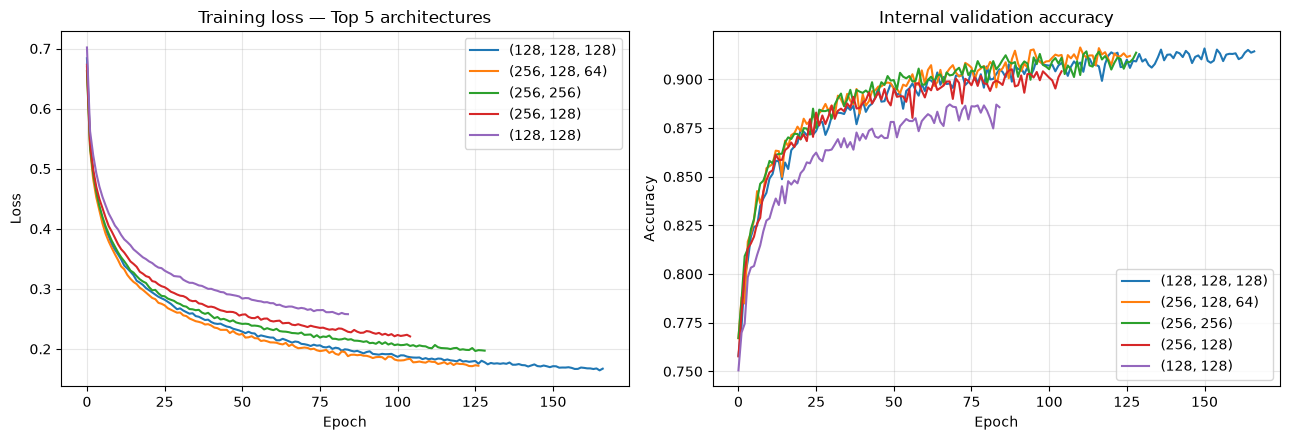

In [52]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for _, row in mlp_arch_df.head(5).iterrows():
    model = mlp_arch_models[int(row["experiment"])]
    classifier = model.named_steps["classifier"]
    label = str(row["architecture"])

    axes[0].plot(
        classifier.loss_curve_,
        label=label
    )

    axes[1].plot(
        classifier.validation_scores_,
        label=label
    )

axes[0].set_title("Training loss — Top 5 architectures")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Internal validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion — Network Architecture Study.**

The systematic architecture benchmark reveals a substantial influence of network depth and width on MLP classification performance.

The best configuration is **(128, 128, 128)**, achieving 91.16% accuracy and **0.88371 Macro F1** on the experimental validation subset.

The architecture (256, 128, 64) achieves slightly higher accuracy (91.36%), but a lower Macro F1 (0.87964). Since Macro F1 is our primary evaluation metric, we select (128, 128, 128).

**Influence of network depth.**

The best Macro F1-scores for architectures with one, two, and three hidden layers are:

| Hidden layers | Best architecture | Macro F1 |
|---|---|---|
| 1 | (512,) | 0.81939 |
| 2 | (256, 256) | 0.86645 |
| 3 | (128, 128, 128) | **0.88371** |

The results suggest that deeper architectures can capture more complex relationships between geographical variables and forest cover types.

Interestingly, the best three-layer network contains only 40,967 trainable parameters, compared with 81,671 for the best two-layer network.

Despite having approximately half as many parameters, the deeper model achieves better classification performance.

This suggests that model capacity cannot be characterized solely by the total number of parameters. The organization of these parameters across layers also influences the functions that the network can represent and learn.

However, this experiment does not isolate depth independently of all other architectural properties, since the compared networks also differ in width and parameter count.

**Influence of network width.**

For single-hidden-layer networks, increasing the number of neurons consistently improves Macro F1, from 0.74407 with 64 neurons to 0.81939 with 512 neurons.

A similar tendency is observed for the tested two-layer architectures, with (256, 256) providing the highest performance.

However, increasing the number of parameters does not systematically improve classification. In particular, (128, 128, 128) outperforms (256, 128, 64), despite containing fewer parameters.

This indicates that both depth and the distribution of neurons across layers influence predictive performance.

**Computational cost and convergence.**

Larger architectures generally require more training time, although the relationship is not strictly proportional to the number of parameters.

For example, the (128, 128, 128) network requires approximately 225 seconds and 167 epochs, while (256, 256) requires approximately 279 seconds and 129 epochs.

Training time therefore depends on network size, number of epochs, and optimization behavior.

The convergence curves provide additional information about these differences, but do not establish that every architecture has reached its best achievable performance.

**Conclusion.**

The architecture study demonstrates that the initial MLP configuration was not necessarily the most appropriate architecture for this dataset.

Among the tested configurations, the three-layer (128, 128, 128) network provides the best Macro F1-score and a favorable compromise between predictive performance and parameter count.

We therefore select this architecture as the main candidate for subsequent preprocessing experiments.

The result remains conditional on the fixed learning rate and regularization used in this experiment. Further tuning of these parameters could potentially improve performance.



### 3.4. Convergence and Overfitting

Gradient-based optimization introduces additional considerations compared with Random Forest and KNN.

We investigate the convergence behavior of the MLP by examining:

- Training loss across epochs.
- Internal validation accuracy used for early stopping.
- Training and external validation Macro F1.
- The number of epochs required before stopping.

With `early_stopping=True`, scikit-learn reserves 10% of the training subset for internal validation and monitors accuracy on this subset.

The internal validation set is distinct from our common external validation set, which remains dedicated to model comparison.

We compare convergence for the three best configurations identified during hyperparameter optimization.


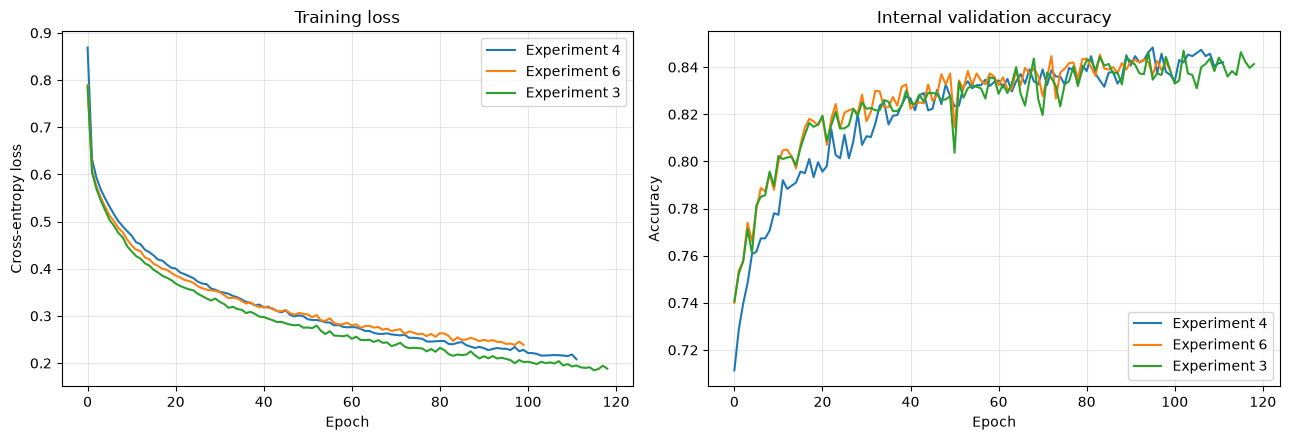

,experiment,epochs,train_macro_f1,val_macro_f1,generalization_gap
0,4,112,0.89236,0.77806,0.11431
1,6,100,0.88273,0.76715,0.11558
2,3,119,0.89927,0.75802,0.14125


In [44]:

mlp_top_ids = mlp_search_df.head(3)["experiment"].astype(int).tolist()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mlp_convergence_results = []

for experiment_id in mlp_top_ids:
    model = mlp_search_models[experiment_id]
    classifier = model.named_steps["classifier"]

    axes[0].plot(
        classifier.loss_curve_,
        label=f"Experiment {experiment_id}"
    )

    axes[1].plot(
        classifier.validation_scores_,
        label=f"Experiment {experiment_id}"
    )

    train_pred = model.predict(X_mlp_train)
    val_pred = model.predict(X_mlp_val)

    train_f1 = f1_score(
        y_mlp_train, train_pred, average="macro"
    )
    val_f1 = f1_score(
        y_mlp_val, val_pred, average="macro"
    )

    mlp_convergence_results.append({
        "experiment": experiment_id,
        "epochs": classifier.n_iter_,
        "train_macro_f1": train_f1,
        "val_macro_f1": val_f1,
        "generalization_gap": train_f1 - val_f1
    })

axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Internal validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

mlp_convergence_df = pd.DataFrame(mlp_convergence_results)
display(mlp_convergence_df.round(5))



**Results and discussion.**

The convergence analysis reveals a substantial difference between training and external validation performance.

For the three best configurations:

| Experiment | Training Macro F1 | Validation Macro F1 | Generalization gap |
|---|---|---|---|
| 4 | 0.89236 | 0.77806 | 0.11431 |
| 6 | 0.88273 | 0.76715 | 0.11558 |
| 3 | 0.89927 | 0.75802 | 0.14125 |

All three configurations exhibit a generalization gap greater than 0.11.

This indicates that the networks perform considerably better on observations used during model development than on the external validation dataset.

Interestingly, experiment 3 achieves the highest training Macro F1 (0.89927) but the lowest validation Macro F1 (0.75802) among the three configurations.

This illustrates that improving training performance does not necessarily translate into better generalization.

The loss curves provide information about optimization progress, while the internal validation accuracy curves illustrate the behavior of the early stopping criterion.

Importantly, early stopping monitors internal validation accuracy rather than Macro F1. Consequently, the stopping point is not necessarily optimal for the metric used to select and compare classifiers.

The relatively large generalization gaps suggest that the networks have sufficient capacity to fit the training data more closely than they generalize to unseen observations.

However, these gaps do not establish that overfitting is the only limiting factor. Optimization dynamics, training data availability, and the choice of architecture may also contribute.

The next experiment investigates whether increasing the training dataset size improves generalization.



### 3.5. Effect of Training Dataset Size

The performance of neural networks depends on the amount of training data available relative to their model capacity.

We evaluate the selected MLP architecture on progressively larger training subsets:

- 10,000 observations;
- 30,000 observations;
- 60,000 observations;
- 120,000 observations;
- The complete training dataset.

The subsets are constructed using a common stratified random ordering so that smaller subsets are contained within larger ones.

For each training size, we evaluate Macro F1 and accuracy on the same external validation subset of 5,000 observations.

We also record training time and the number of epochs, since increasing the dataset size may improve generalization while increasing computational cost.

The objective is to investigate whether the MLP benefits from additional training data and whether the validation performance begins to plateau.


  10000 samples | Macro F1=0.64224 | Epochs=67 | Train=6.7s
  30000 samples | Macro F1=0.75566 | Epochs=81 | Train=28.7s
  60000 samples | Macro F1=0.79811 | Epochs=71 | Train=47.5s
 120000 samples | Macro F1=0.86287 | Epochs=120 | Train=178.0s
 406708 samples | Macro F1=0.90234 | Epochs=100 | Train=582.1s


,n_samples,accuracy,macro_f1,epochs,train_time_s
0,10000,0.7690,0.64224,67,6.65709
1,30000,0.8400,0.75566,81,28.67971
2,60000,0.8628,0.79811,71,47.46970
3,120000,0.9042,0.86287,120,177.97765
4,406708,0.9294,0.90234,100,582.08495


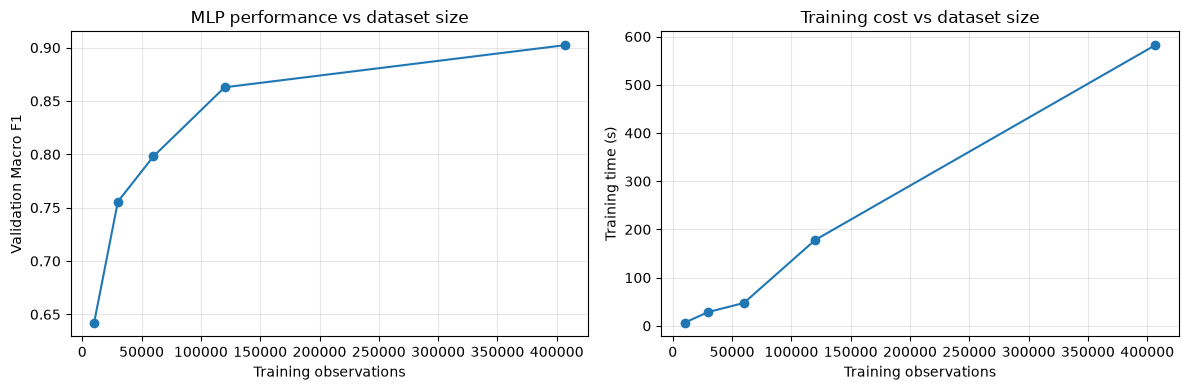

In [45]:

mlp_train_sizes = [10_000, 30_000, 60_000, 120_000, len(y_train)]

mlp_order, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=len(y_train) - len(classes),
    stratify=y_train,
    random_state=RANDOM_STATE
)

mlp_learning_results = []

for n_samples in mlp_train_sizes:
    if n_samples == len(y_train):
        X_sub, y_sub = X_train, y_train
    else:
        indices = mlp_order[:n_samples]
        X_sub = X_train.iloc[indices]
        y_sub = np.asarray(y_train)[indices]

    model = make_mlp(
        preprocessing=mlp_best_scaling,
        hidden_layer_sizes=mlp_best_params["hidden_layer_sizes"],
        alpha=float(mlp_best_params["alpha"]),
        learning_rate_init=float(mlp_best_params["learning_rate_init"]),
        max_iter=250
    )

    _, metrics = evaluate_mlp(
        f"MLP_{n_samples}",
        model,
        X_sub, y_sub,
        X_mlp_val, y_mlp_val
    )

    mlp_learning_results.append({
        "n_samples": n_samples,
        **metrics
    })

    print(
        f"{n_samples:>7} samples | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Epochs={metrics['epochs']} | "
        f"Train={metrics['train_time_s']:.1f}s",
        flush=True
    )

mlp_learning_df = pd.DataFrame(mlp_learning_results)

display(mlp_learning_df[
    ["n_samples", "accuracy", "macro_f1",
     "epochs", "train_time_s"]
].round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    mlp_learning_df["n_samples"],
    mlp_learning_df["macro_f1"],
    "o-"
)
axes[0].set_xlabel("Training observations")
axes[0].set_ylabel("Validation Macro F1")
axes[0].set_title("MLP performance vs dataset size")
axes[0].grid(alpha=0.3)

axes[1].plot(
    mlp_learning_df["n_samples"],
    mlp_learning_df["train_time_s"],
    "o-"
)
axes[1].set_xlabel("Training observations")
axes[1].set_ylabel("Training time (s)")
axes[1].set_title("Training cost vs dataset size")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

Increasing the training dataset size substantially improves MLP classification performance.

| Training samples | Accuracy | Macro F1 | Training time |
|---|---|---|---|
| 10,000 | 0.7690 | 0.64224 | 6.7 s |
| 30,000 | 0.8400 | 0.75566 | 28.7 s |
| 60,000 | 0.8628 | 0.79811 | 47.5 s |
| 120,000 | 0.9042 | 0.86287 | 178.0 s |
| 406,708 | **0.9294** | **0.90234** | **582.1 s** |

Macro F1 increases by approximately 0.260 between the smallest and largest training datasets.

This demonstrates that the selected neural network benefits considerably from additional training observations.

Increasing the sample size provides more examples of the relationships between geographical characteristics and forest cover types, potentially improving the estimation of the network parameters and reducing generalization errors.

The gain remains substantial at large dataset sizes: Macro F1 increases from 0.86287 to 0.90234 between 120,000 and 406,708 training observations.

Consequently, the experiment does not establish a clear performance plateau.

**Computational cost.**

Unlike KNN, the main computational cost of MLP is associated with training rather than prediction.

Training time increases from approximately 6.7 seconds for 10,000 observations to 582 seconds for the complete training dataset.

This increase depends not only on the number of training observations but also on the number of epochs performed before early stopping.

For example, the 120,000-sample model runs for 120 epochs, whereas the full-dataset model stops after 100 epochs.

Thus, training time does not necessarily scale linearly with dataset size.

**Comparison with KNN.**

Both KNN and MLP benefit strongly from additional data, but their computational characteristics differ.

KNN requires minimal fitting time and becomes increasingly expensive during prediction, whereas MLP requires substantial optimization during training but produces predictions efficiently once trained.

Overall, the experiment demonstrates the importance of training dataset size for neural network performance, while highlighting the computational cost of learning a parametric nonlinear model.



### 3.6. Feature Engineering and Dimensionality Reduction

The previous experiments showed that feature scaling is essential for MLP performance and that network architecture significantly influences classification accuracy.

We now investigate whether additional feature transformations improve the performance of the selected architecture.

The following preprocessing strategies are considered:

- **Numerical scaling:** standardize the numerical features while preserving binary indicators. This serves as our reference configuration.
- **Cyclic Aspect:** replace the angular variable `Aspect` with its sine and cosine components to account for its periodicity.
- **Numerical PCA:** apply PCA to the standardized numerical variables, retaining 95% of their variance.
- **Global PCA:** apply PCA to all standardized features, retaining 95% of their variance.
- **Cyclic Aspect with numerical PCA:** investigate whether a periodic representation of Aspect improves the PCA-based representation.
- **Rare Soil filtering:** remove Soil Type indicators whose frequency is below 0.1% in the training subset.

All configurations use the selected architecture `(128, 128, 128)`, with L2 regularization $\alpha=0.01$ and an initial learning rate of 0.001.

The models are trained on the same stratified subset of 120,000 observations and evaluated on the same external validation subset of 5,000 observations.

We compare accuracy, Macro F1, training time, number of epochs, and number of input features after preprocessing.

The purpose is to determine whether feature engineering or dimensionality reduction improves the classification performance of the selected MLP.

All preprocessing transformations are fitted exclusively on the corresponding training subset to prevent data leakage.


In [53]:

mlp_preprocessing_configs = {
    "Numeric scaling": PreprocessingConfig(
        scaling=True, pca="none"
    ),
    "Cyclic Aspect": PreprocessingConfig(
        scaling=True, pca="none", cyclic_aspect=True
    ),
    "Numeric PCA (95%)": PreprocessingConfig(
        scaling=True, pca="numeric", pca_components=0.95
    ),
    "Global PCA (95%)": PreprocessingConfig(
        scaling=True, pca="all", pca_components=0.95
    ),
    "Cyclic Aspect + PCA": PreprocessingConfig(
        scaling=True, pca="numeric",
        pca_components=0.95, cyclic_aspect=True
    ),
    "Rare Soil filtering": PreprocessingConfig(
        scaling=True, pca="none",
        rare_soil_threshold=0.001
    )
}

mlp_preprocessing_results = []
mlp_preprocessing_models = {}

best_architecture = tuple(mlp_arch_df.iloc[0]["architecture"])

for name, config in mlp_preprocessing_configs.items():
    model = Pipeline([
        ("preprocessing", build_preprocessor(config)),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=best_architecture,
            activation="relu",
            solver="adam",
            alpha=float(mlp_best_params["alpha"]),
            learning_rate_init=float(mlp_best_params["learning_rate_init"]),
            batch_size=256,
            max_iter=250,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=15,
            random_state=RANDOM_STATE
        ))
    ])

    model, metrics = evaluate_mlp(
        name, model,
        X_mlp_arch, y_mlp_arch,
        X_mlp_val, y_mlp_val
    )

    classifier = model.named_steps["classifier"]
    n_features = classifier.n_features_in_
    n_parameters = sum(
        w.size + b.size
        for w, b in zip(classifier.coefs_, classifier.intercepts_)
    )

    mlp_preprocessing_models[name] = model
    mlp_preprocessing_results.append({
        "preprocessing": name,
        "n_features": n_features,
        "n_parameters": n_parameters,
        **metrics
    })

    print(
        f"{name:>24} | "
        f"Features={n_features} | "
        f"Macro F1={metrics['macro_f1']:.5f} | "
        f"Epochs={metrics['epochs']} | "
        f"Train={metrics['train_time_s']:.1f}s",
        flush=True
    )

mlp_preprocessing_df = (
    pd.DataFrame(mlp_preprocessing_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(mlp_preprocessing_df[
    ["preprocessing", "n_features", "n_parameters",
     "accuracy", "macro_f1", "epochs", "train_time_s"]
].round(5))

mlp_best_preprocessing = mlp_preprocessing_df.iloc[0]["preprocessing"]

print("Best architecture:", best_architecture)
print("Best preprocessing:", mlp_best_preprocessing)


         Numeric scaling | Features=54 | Macro F1=0.88371 | Epochs=167 | Train=231.2s
           Cyclic Aspect | Features=55 | Macro F1=0.85866 | Epochs=139 | Train=203.4s
       Numeric PCA (95%) | Features=52 | Macro F1=0.86948 | Epochs=179 | Train=257.5s
        Global PCA (95%) | Features=43 | Macro F1=0.84232 | Epochs=169 | Train=215.2s
     Cyclic Aspect + PCA | Features=52 | Macro F1=0.87388 | Epochs=114 | Train=158.7s
     Rare Soil filtering | Features=47 | Macro F1=0.85391 | Epochs=104 | Train=138.3s


,preprocessing,n_features,n_parameters,accuracy,macro_f1,epochs,train_time_s
0,Numeric scaling,54,40967,0.9116,0.88371,167,231.15917
1,Cyclic Aspect + PCA,52,40711,0.9116,0.87388,114,158.72147
2,Numeric PCA (95%),52,40711,0.9092,0.86948,179,257.52528
3,Cyclic Aspect,55,41095,0.9082,0.85866,139,203.44785
4,Rare Soil filtering,47,40071,0.9086,0.85391,104,138.29405
5,Global PCA (95%),43,39559,0.8952,0.84232,169,215.24359


Best architecture: (128, 128, 128)
Best preprocessing: Numeric scaling


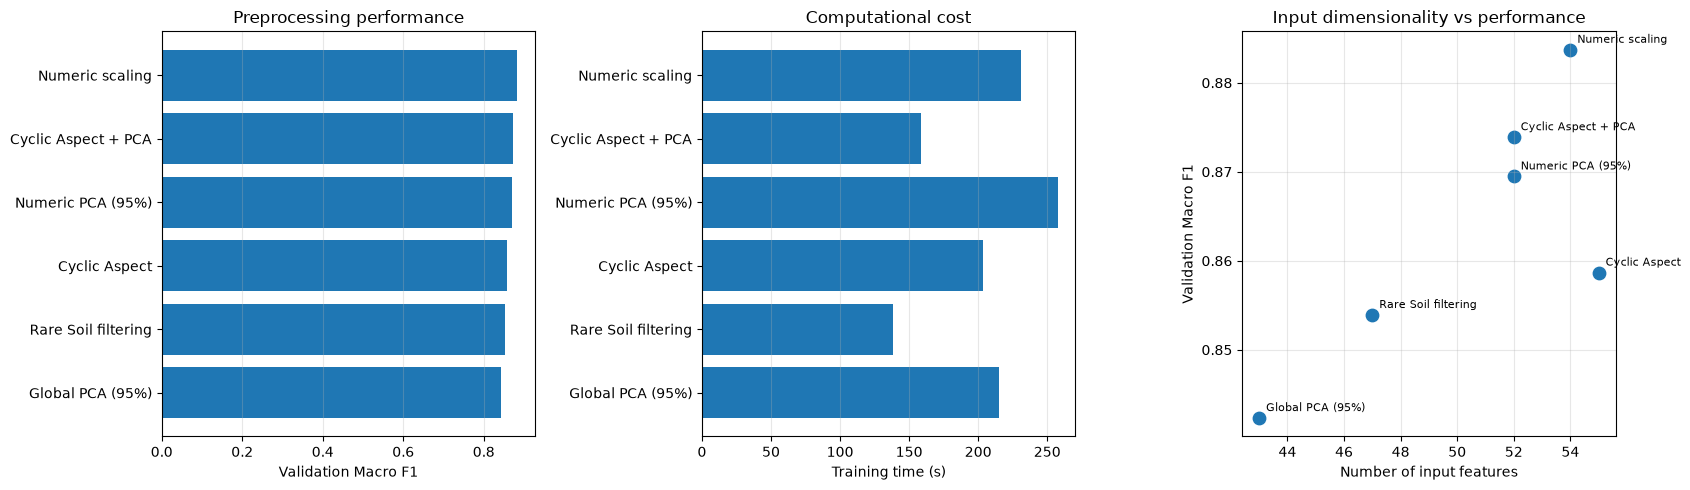

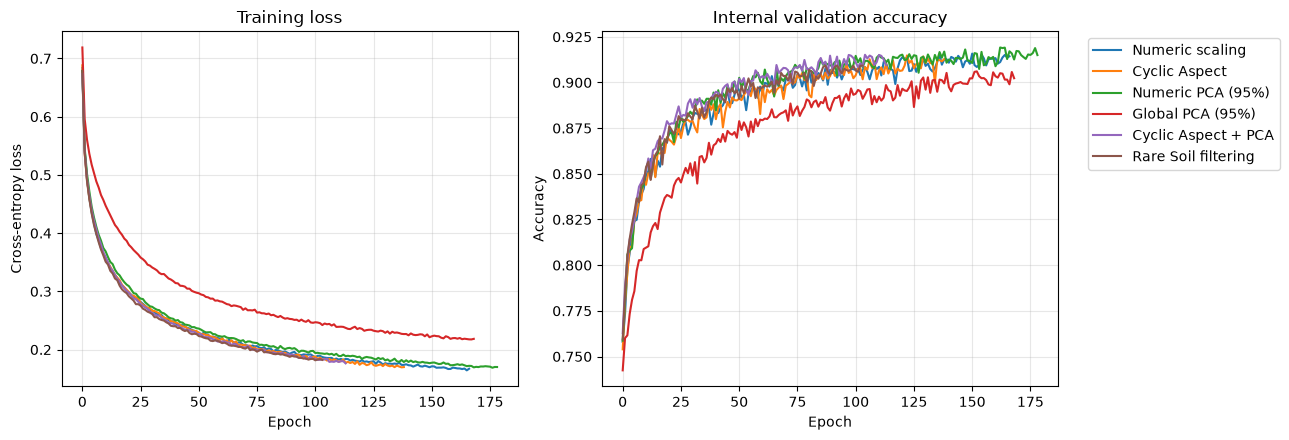

In [54]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

results = mlp_preprocessing_df.iloc[::-1]

axes[0].barh(
    results["preprocessing"],
    results["macro_f1"]
)
axes[0].set_xlabel("Validation Macro F1")
axes[0].set_title("Preprocessing performance")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(
    results["preprocessing"],
    results["train_time_s"]
)
axes[1].set_xlabel("Training time (s)")
axes[1].set_title("Computational cost")
axes[1].grid(axis="x", alpha=0.3)

axes[2].scatter(
    mlp_preprocessing_df["n_features"],
    mlp_preprocessing_df["macro_f1"],
    s=80
)

for _, row in mlp_preprocessing_df.iterrows():
    axes[2].annotate(
        row["preprocessing"],
        (row["n_features"], row["macro_f1"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[2].set_xlabel("Number of input features")
axes[2].set_ylabel("Validation Macro F1")
axes[2].set_title("Input dimensionality vs performance")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, model in mlp_preprocessing_models.items():
    classifier = model.named_steps["classifier"]

    axes[0].plot(
        classifier.loss_curve_,
        label=name
    )
    axes[1].plot(
        classifier.validation_scores_,
        label=name
    )

axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Internal validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)

axes[1].legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()



**Results and discussion.**

The preprocessing benchmark investigates whether feature engineering and dimensionality reduction improve the performance of the selected three-layer MLP architecture.

The experiments use the same 120,000 training observations, 5,000 validation observations, and fixed network hyperparameters.

| Preprocessing | Input features | Accuracy | Macro F1 | Training time |
|---|---:|---:|---:|---:|
| Numerical scaling | 54 | **0.9116** | **0.88371** | 231.2 s |
| Cyclic Aspect | 55 | 0.9082 | 0.85866 | 203.4 s |
| Numerical PCA (95%) | 52 | 0.9092 | 0.86948 | 257.5 s |
| Global PCA (95%) | 43 | 0.8952 | 0.84232 | 215.2 s |
| Cyclic Aspect + PCA | 52 | **0.9116** | 0.87388 | 158.7 s |
| Rare Soil filtering | 47 | 0.9086 | 0.85391 | 138.3 s |

**Cyclic representation of Aspect.**

Aspect is an angular variable, making it a natural candidate for a periodic representation using sine and cosine components.

However, cyclic encoding decreases Macro F1 from 0.88371 to 0.85866.

Combining cyclic encoding with numerical PCA improves performance relative to cyclic encoding alone, reaching 0.87388, but still does not outperform the reference.

Interestingly, cyclic Aspect combined with PCA achieves the same accuracy as the reference (0.9116), but a lower Macro F1. This suggests differences in how classification performance is distributed across the seven classes.

These findings do not establish that cyclic representations are intrinsically less suitable. Their effectiveness may depend on feature scaling, network architecture, and optimization hyperparameters.

**Principal Component Analysis.**

Neither PCA configuration improves predictive performance.

Numerical PCA reduces the input dimensionality from 54 to 52 features, but decreases Macro F1 to 0.86948.

Global PCA reduces the representation to 43 features and produces the lowest Macro F1-score (0.84232).

PCA retains directions of high variance without explicitly considering class labels. Consequently, variance preservation does not necessarily imply preservation of discriminative information.

The results suggest that the original feature representation contains useful information that is not fully preserved by the tested PCA transformations.

**Rare Soil Type filtering.**

Removing rare Soil Type indicators reduces the number of input features from 54 to 47.

However, Macro F1 decreases to 0.85391, suggesting that some discarded indicators may contain useful classification information.

This is particularly relevant for an imbalanced multiclass problem, where rare features may help distinguish minority classes.

Nevertheless, the experiment does not directly establish which discarded variables are responsible for the performance decrease.

**Computational efficiency.**

The preprocessing transformations also affect training time.

Rare Soil filtering produces the shortest training time (138.3 seconds), followed by cyclic Aspect combined with PCA (158.7 seconds).

However, training times cannot be attributed solely to input dimensionality.

The models stop after different numbers of epochs due to early stopping. For instance, the reference model performs 167 epochs, compared with 104 for Rare Soil filtering.

Furthermore, preprocessing itself introduces computational overhead.

Therefore, training time differences reflect both the transformations and the optimization behavior of the neural network.

**Conclusion.**

The simplest tested representation, numerical scaling without additional transformations, achieves the highest validation Macro F1-score (0.88371).

Although some transformations reduce training time or preserve similar accuracy, none improves the primary evaluation metric.

We therefore retain numerical scaling with the three-layer architecture (128, 128, 128) for the final full-dataset evaluation.

These conclusions apply to the selected architecture and fixed optimization hyperparameters. Additional tuning or repeated training runs could potentially lead to different results.



### 3.7. Full-Dataset Validation

After selecting the preprocessing strategy and hyperparameters on the experimental subsets, we train the selected MLP on the complete training dataset.

The model is evaluated on the same validation set used for Random Forest and KNN, ensuring a consistent comparison of predictive performance.

We report:

- Accuracy, Macro F1, and weighted F1.
- Training and prediction times.
- Number of training epochs.
- Training loss and internal validation accuracy during optimization.

As in the previous experiments, early stopping uses an internal validation fraction of the training data. The external validation set is used exclusively for model evaluation and comparison.

The resulting metrics are stored in the shared `experiment_results` dictionary.


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s,epochs
0,MLP,0.94539,0.91117,0.94527,1160.26363,0.11648,195


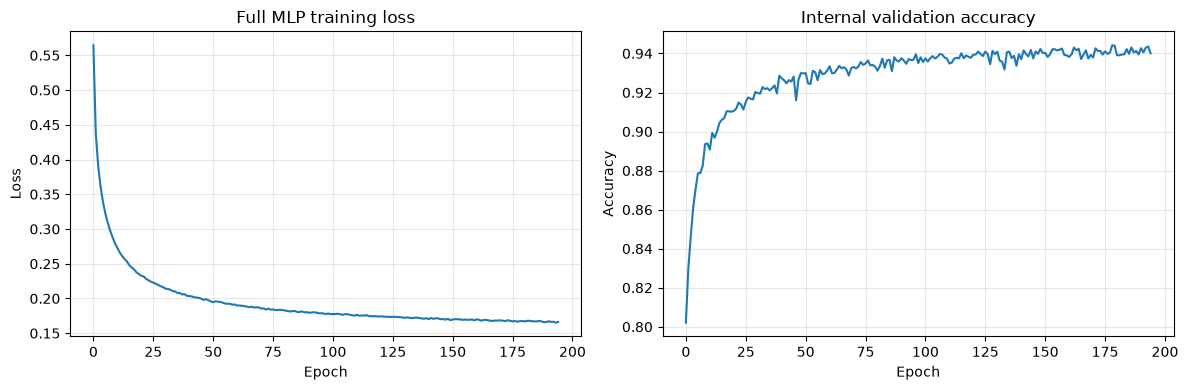

In [55]:

mlp_best = make_mlp(
    preprocessing="numeric",
    hidden_layer_sizes=best_architecture,
    alpha=float(mlp_best_params["alpha"]),
    learning_rate_init=float(mlp_best_params["learning_rate_init"]),
    max_iter=250
)

mlp_best, mlp_metrics = evaluate_mlp(
    "MLP",
    mlp_best,
    X_train, y_train,
    X_val, y_val
)

mlp_val_pred = mlp_best.predict(X_val)
experiment_results["MLP"] = mlp_metrics.copy()

display(pd.DataFrame([mlp_metrics]).round(5))

classifier = mlp_best.named_steps["classifier"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(classifier.loss_curve_)
axes[0].set_title("Full MLP training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(classifier.validation_scores_)
axes[1].set_title("Internal validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

The selected three-layer MLP was trained on the complete training dataset of 406,708 observations and evaluated on the common validation set of 87,152 observations.

The final configuration uses three hidden layers of 128 neurons each, numerical feature standardization, ReLU activation, Adam optimization, L2 regularization with $\alpha=0.01$, and an initial learning rate of 0.001.

| Metric | Value |
|---|---|
| Accuracy | **0.94539** |
| Macro F1 | **0.91117** |
| Weighted F1 | 0.94527 |
| Training time | 1,160.3 s |
| Prediction time | 0.1165 s |
| Training epochs | 195 |

**Comparison with the initial architecture.**

The previous two-layer MLP (256, 128) achieved 0.92967 accuracy and 0.89706 Macro F1 on the same validation set.

The new architecture improves accuracy by approximately 1.57 percentage points and Macro F1 by 1.41 percentage points.

This improvement confirms the value of the additional architecture search. However, it does not establish that the selected network is globally optimal.

**Computational characteristics.**

The improved architecture requires approximately 19.3 minutes of training, compared with 9.6 minutes for the previous model.

The new network also trains for 195 epochs instead of 100, meaning that the difference in total training time cannot be attributed solely to network architecture.

Inference remains efficient, requiring approximately 0.12 seconds for the complete validation set under the measured conditions.

**Comparison with the other classifiers.**

The optimized MLP reduces its performance gap with Random Forest and KNN but remains below both models in Macro F1.

Random Forest achieves 0.94517 Macro F1, KNN achieves approximately 0.93611, and the optimized MLP reaches 0.91117.

The model is therefore competitive in overall accuracy while remaining less effective at balancing predictive performance across the seven classes.



### 3.8. Classification Error Analysis

We analyze the predictions of the selected MLP on the complete validation dataset.

The analysis focuses on class-specific precision, recall, and F1-scores, as well as absolute and normalized confusion matrices.

We identify the most frequent misclassifications and the largest class-relative error rates.

This will allow us to determine whether the MLP exhibits similar classification difficulties to Random Forest and KNN, especially for minority classes.


              precision    recall  f1-score   support

           1     0.9500    0.9350    0.9424     31776
           2     0.9489    0.9593    0.9541     42495
           3     0.9415    0.9510    0.9462      5363
           4     0.9456    0.7597    0.8425       412
           5     0.8683    0.8146    0.8406      1424
           6     0.8971    0.9102    0.9036      2605
           7     0.9314    0.9669    0.9488      3077

    accuracy                         0.9454     87152
   macro avg     0.9261    0.8995    0.9112     87152
weighted avg     0.9454    0.9454    0.9453     87152



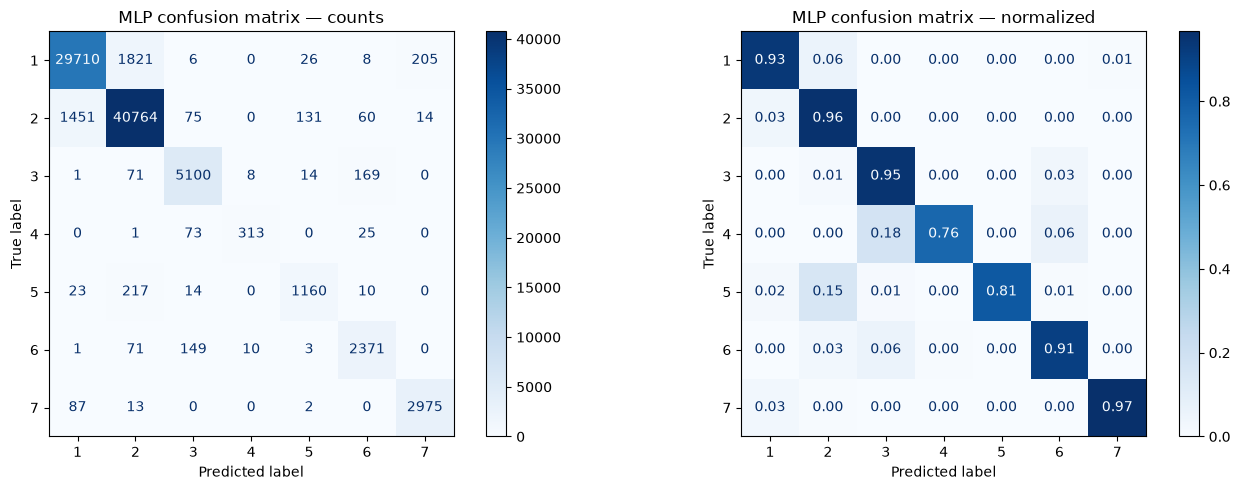

Most frequent errors:


,true_class,predicted_class,errors,error_rate
0,1,2,1821,0.05731
6,2,1,1451,0.03415
25,5,2,217,0.15239
5,1,7,205,0.00645
16,3,6,169,0.03151
32,6,3,149,0.05720
9,2,5,131,0.00308
36,7,1,87,0.02827
7,2,3,75,0.00176
20,4,3,73,0.17718


Largest relative error rates:


,true_class,predicted_class,errors,error_rate
20,4,3,73,0.17718
25,5,2,217,0.15239
22,4,6,25,0.06068
0,1,2,1821,0.05731
32,6,3,149,0.05720
6,2,1,1451,0.03415
16,3,6,169,0.03151
36,7,1,87,0.02827
31,6,2,71,0.02726
24,5,1,23,0.01615


In [56]:

print(classification_report(
    y_val,
    mlp_val_pred,
    digits=4,
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val, mlp_val_pred,
    labels=classes,
    ax=axes[0],
    cmap="Blues",
    values_format="d"
)
axes[0].set_title("MLP confusion matrix — counts")

ConfusionMatrixDisplay.from_predictions(
    y_val, mlp_val_pred,
    labels=classes,
    normalize="true",
    ax=axes[1],
    cmap="Blues",
    values_format=".2f"
)
axes[1].set_title("MLP confusion matrix — normalized")

plt.tight_layout()
plt.show()

mlp_cm = confusion_matrix(
    y_val, mlp_val_pred, labels=classes
)

mlp_confusions = []

for i, true_class in enumerate(classes):
    for j, predicted_class in enumerate(classes):
        if i == j:
            continue

        mlp_confusions.append({
            "true_class": true_class,
            "predicted_class": predicted_class,
            "errors": mlp_cm[i, j],
            "error_rate": mlp_cm[i, j] / mlp_cm[i].sum()
        })

mlp_confusion_df = pd.DataFrame(mlp_confusions)

print("Most frequent errors:")
display(
    mlp_confusion_df
    .sort_values("errors", ascending=False)
    .head(15)
    .round(5)
)

print("Largest relative error rates:")
display(
    mlp_confusion_df
    .sort_values("error_rate", ascending=False)
    .head(15)
    .round(5)
)



**Results and discussion.**

The optimized three-layer MLP achieves 94.54% accuracy and 0.91117 Macro F1 on the complete validation dataset.

| Class | Precision | Recall | F1-score |
|---|---|---|---|
| 1 | 0.9500 | 0.9350 | 0.9424 |
| 2 | 0.9489 | 0.9593 | 0.9541 |
| 3 | 0.9415 | 0.9510 | 0.9462 |
| 4 | 0.9456 | 0.7597 | 0.8425 |
| 5 | 0.8683 | 0.8146 | 0.8406 |
| 6 | 0.8971 | 0.9102 | 0.9036 |
| 7 | 0.9314 | 0.9669 | 0.9488 |

**Majority-class errors.**

Classes 1 and 2 achieve strong F1-scores, but account for the largest absolute numbers of errors due to their high prevalence.

The two most frequent misclassifications are:

- Class 1 predicted as class 2: 1,821 observations.
- Class 2 predicted as class 1: 1,451 observations.

**Minority-class performance.**

Classes 4 and 5 remain the most challenging, with F1-scores of 0.8425 and 0.8406.

Class 4 exhibits high precision (0.9456) but relatively low recall (0.7597). The model is therefore more conservative when predicting this class, missing a substantial proportion of its actual observations.

The most important class-relative errors include:

- Class 4 predicted as class 3: 17.72%.
- Class 5 predicted as class 2: 15.24%.
- Class 4 predicted as class 6: 6.07%.
- Class 6 predicted as class 3: 5.72%.

These results highlight the persistent difficulty of distinguishing certain minority classes, despite the improvement obtained through architecture optimization.

**Comparison with other classifiers.**

The MLP exhibits several confusion patterns also observed with Random Forest and KNN, particularly between classes 1 and 2 and among certain minority classes.

However, its Macro F1 remains lower than those of the other two classifiers.

The final comparative analysis will examine class-specific performance and determine whether the three models make errors on the same validation observations.



### 3.9. Discussion and Conclusions

The MLP experiments demonstrate that network architecture, preprocessing, and training dataset size substantially influence classification performance on the Covertype dataset.

The final selected MLP uses three hidden layers containing 128 neurons each, ReLU activation, Adam optimization, numerical feature standardization, L2 regularization with $\alpha=0.01$, and an initial learning rate of 0.001.

Trained on the complete training dataset, it achieves **94.54% validation accuracy and 0.91117 Macro F1**.

**Feature scaling and preprocessing.**

Numerical standardization substantially improves the baseline MLP, whereas global standardization performs less effectively.

Additional feature engineering experiments investigated cyclic encoding of Aspect, numerical and global PCA, their combination, and filtering of rare Soil Type indicators.

None of these transformations improves Macro F1 over numerical standardization alone with the selected architecture.

**Hyperparameter optimization and architecture.**

The initial random hyperparameter search selected a two-layer network (256, 128).

A subsequent systematic comparison of 11 architectures revealed that a three-layer configuration (128, 128, 128) achieved the highest validation Macro F1 on the 120,000-observation training subset.

Retraining this architecture on the complete dataset improves Macro F1 from 0.89706 to 0.91117 and accuracy from 0.92967 to 0.94539.

This confirms that a limited initial hyperparameter search did not fully characterize the potential of the MLP.

**Generalization and training dataset size.**

The initial experiments revealed substantial training–validation gaps on small datasets, while increasing the number of training observations considerably improved predictive performance.

The original dataset-size experiment was conducted with the two-layer architecture and therefore does not directly characterize the final three-layer MLP.

Nevertheless, it demonstrates that the amount of available training data strongly influences neural network performance.

**Class-specific performance.**

The selected MLP performs well on majority classes, but classes 4 and 5 remain more difficult, with F1-scores of 0.8425 and 0.8406.

These results reinforce the importance of Macro F1 and class-specific metrics for imbalanced multiclass classification.

**Computational trade-off.**

Full-dataset training requires approximately 1,160 seconds, while prediction on the complete validation dataset requires approximately 0.12 seconds.

The improved architecture therefore increases training cost substantially while preserving efficient inference.

**Overall assessment.**

The optimized MLP achieves 0.91117 Macro F1, compared with 0.94517 for Random Forest and approximately 0.93611 for KNN.

Although the additional architecture search substantially improves its performance, the MLP remains below both alternatives under the current experimental protocol.

Its main practical advantage is efficient inference after training, while its principal limitations are higher training cost and less balanced class-specific performance.

The final comparison will examine predictive performance, error complementarity, computational cost, and model selection across all three classifiers.




## 4. Final Test Evaluation

The previous sections used the training and validation datasets to investigate preprocessing strategies, optimize hyperparameters, and select the final configurations of Random Forest, KNN, and MLP.

We now evaluate these selected configurations on the held-out test dataset.

For each classifier, we:

1. Reconstruct the selected model with its fixed hyperparameters and preprocessing.
2. Retrain the model on the combined training and validation datasets (85% of the original dataset).
3. Evaluate predictions on the test dataset (15%).
4. Report accuracy, Macro F1, weighted F1, and computational costs.

All preprocessing transformations are fitted exclusively on the combined training and validation data. The test observations are not used for fitting, model selection, or hyperparameter optimization.

The selected configurations are:

| Classifier | Final configuration |
|---|---|
| Random Forest | 300 trees, unrestricted depth, `max_features=0.5`, class-weight exponent $\alpha=0.25$ |
| KNN | One neighbor, Manhattan distance, uniform weighting, no scaling or PCA |
| MLP | Three hidden layers of 128 neurons, numerical scaling, ReLU, Adam, $\alpha=0.01$, initial learning rate 0.001 |

Macro F1 remains the primary evaluation metric due to class imbalance.

**Methodological limitation:** An earlier Random Forest experiment had already examined the test dataset. Therefore, the test set has not remained completely unseen throughout the project. Nevertheless, the subsequent model selection was based on validation results, and no configurations will be adjusted using the new test scores.


In [75]:

X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = np.concatenate([y_train, y_val])

assert len(X_trainval) == len(y_trainval)
assert list(X_trainval.columns) == list(X_test.columns)
assert X_trainval.index.intersection(X_test.index).empty

print("Train + validation:", X_trainval.shape)
print("Test:", X_test.shape)

test_results = {}
test_predictions = {}


Train + validation: (493860, 54)
Test: (87152, 54)



### 4.1. Random Forest Test Evaluation

The selected Random Forest is retrained on the combined training and validation datasets.

The hyperparameters are fixed according to the previous validation experiments: 300 estimators, unrestricted tree depth, `max_features=0.5`, `min_samples_leaf=1`, and class-weight exponent $\alpha=0.25$.

Class weights are recomputed from the combined training and validation labels, without using the test labels.

The resulting model is evaluated on the test dataset using accuracy, Macro F1, and weighted F1.


In [77]:

rf_final = make_rf(
    n_estimators=int(rf_best_params["n_estimators"]),
    max_depth=None,
    min_samples_leaf=1,
    max_features=rf_best_params["max_features"],
    alpha=float(rf_best_params["alpha"]),
    y_weights=y_trainval
)

start = perf_counter()
rf_final.fit(X_trainval, y_trainval)
rf_final_train_time = perf_counter() - start

start = perf_counter()
rf_test_pred = rf_final.predict(X_test)
rf_final_predict_time = perf_counter() - start

test_predictions["Random Forest"] = rf_test_pred
test_results["Random Forest"] = {
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, rf_test_pred),
    "macro_f1": f1_score(y_test, rf_test_pred, average="macro"),
    "weighted_f1": f1_score(y_test, rf_test_pred, average="weighted"),
    "train_time_s": rf_final_train_time,
    "predict_time_s": rf_final_predict_time
}

display(pd.DataFrame([test_results["Random Forest"]]).round(5))


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,Random Forest,0.96964,0.94851,0.96962,52.68379,0.50914



### 4.2. KNN Test Evaluation

The selected KNN configuration uses one nearest neighbor, Manhattan distance, uniform neighbor weighting, and the original feature representation without scaling or PCA.

The classifier is fitted on the combined training and validation datasets.

Because brute-force nearest-neighbor prediction is computationally expensive and memory-intensive, test predictions are performed in batches of 2,000 observations, using the same procedure as the full validation experiment.

The predictions are then combined to calculate the final test metrics.


In [78]:

knn_final = make_knn_selected()

start = perf_counter()
knn_final.fit(X_trainval, y_trainval)
knn_final_train_time = perf_counter() - start

knn_test_batches = []
batch_size = 2000

start = perf_counter()

for i in range(0, len(X_test), batch_size):
    X_batch = X_test.iloc[i:i + batch_size]
    knn_test_batches.append(knn_final.predict(X_batch))

    print(
        f"Predicted {min(i + batch_size, len(X_test))}"
        f"/{len(X_test)}",
        end="\r",
        flush=True
    )

knn_final_predict_time = perf_counter() - start
knn_test_pred = np.concatenate(knn_test_batches)

test_predictions["KNN"] = knn_test_pred
test_results["KNN"] = {
    "model": "KNN",
    "accuracy": accuracy_score(y_test, knn_test_pred),
    "macro_f1": f1_score(y_test, knn_test_pred, average="macro"),
    "weighted_f1": f1_score(y_test, knn_test_pred, average="weighted"),
    "train_time_s": knn_final_train_time,
    "predict_time_s": knn_final_predict_time
}

print()
display(pd.DataFrame([test_results["KNN"]]).round(5))


Predicted 87152/87152


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,KNN,0.96607,0.93844,0.96605,0.07202,480.97937



### 4.3. MLP Test Evaluation

The selected MLP uses three hidden layers containing 128 neurons each, numerical feature standardization, ReLU activation, Adam optimization, L2 regularization with $\alpha=0.01$, and an initial learning rate of 0.001.

The model is retrained on the combined training and validation datasets, using the same optimization procedure and early stopping configuration selected previously.

Early stopping reserves an internal fraction of the combined training data to monitor convergence. The test dataset is never used for this purpose.

We report test classification metrics, training and prediction times, and the number of training epochs.


In [79]:

mlp_final = clone(mlp_best)

start = perf_counter()
mlp_final.fit(X_trainval, y_trainval)
mlp_final_train_time = perf_counter() - start

start = perf_counter()
mlp_test_pred = mlp_final.predict(X_test)
mlp_final_predict_time = perf_counter() - start

test_predictions["MLP"] = mlp_test_pred
test_results["MLP"] = {
    "model": "MLP",
    "accuracy": accuracy_score(y_test, mlp_test_pred),
    "macro_f1": f1_score(y_test, mlp_test_pred, average="macro"),
    "weighted_f1": f1_score(y_test, mlp_test_pred, average="weighted"),
    "train_time_s": mlp_final_train_time,
    "predict_time_s": mlp_final_predict_time,
    "epochs": mlp_final.named_steps["classifier"].n_iter_
}

display(pd.DataFrame([test_results["MLP"]]).round(5))


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s,epochs
0,MLP,0.9397,0.90645,0.93959,706.76348,0.21603,107



### 4.4. Final Test Results

We summarize the test performance of the three selected classifiers.

All models have been retrained on the combined training and validation datasets, and their hyperparameters have remained unchanged.

The comparison reports accuracy, Macro F1, weighted F1, training time, and prediction time.

These test results provide a final assessment of the selected configurations. They are not used for further hyperparameter optimization or model selection.

We also compare validation and test performance, while recognizing that the final models were trained on a larger dataset than the models used during validation.


,model,accuracy,macro_f1,weighted_f1,train_time_s,predict_time_s
0,Random Forest,0.96964,0.94851,0.96962,52.68379,0.50914
1,KNN,0.96607,0.93844,0.96605,0.07202,480.97937
2,MLP,0.93970,0.90645,0.93959,706.76348,0.21603


,model,val_accuracy,accuracy,val_macro_f1,macro_f1,macro_f1_difference
0,Random Forest,0.96715,0.96964,0.94517,0.94851,0.00335
1,KNN,0.96528,0.96607,0.93611,0.93844,0.00233
2,MLP,0.94539,0.93970,0.91117,0.90645,-0.00472


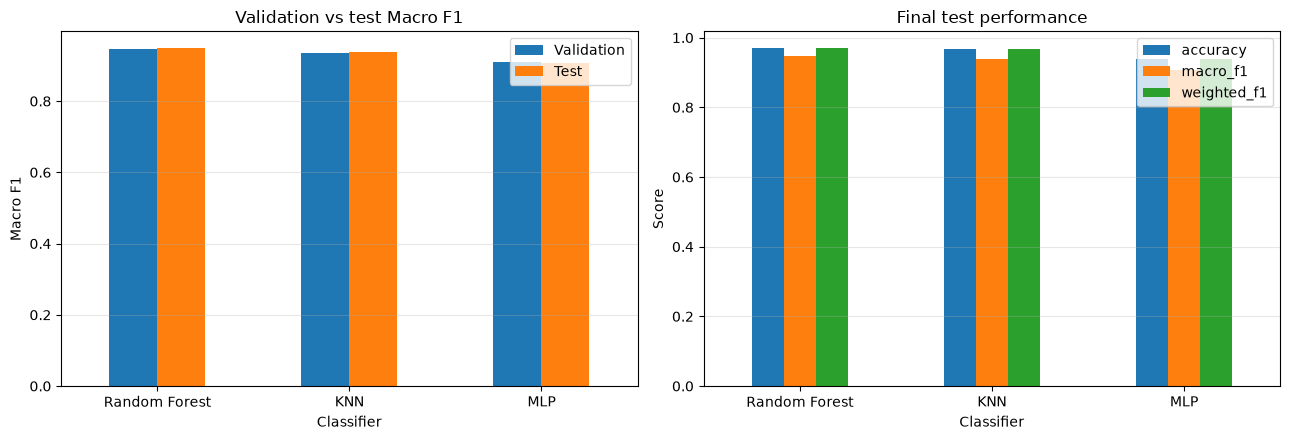

In [80]:

assert set(test_results) == {"Random Forest", "KNN", "MLP"}

test_df = (
    pd.DataFrame(test_results.values())
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(test_df[
    ["model", "accuracy", "macro_f1", "weighted_f1",
     "train_time_s", "predict_time_s"]
].round(5))

validation_df = pd.DataFrame([
    {
        "model": name,
        "val_accuracy": metrics["accuracy"],
        "val_macro_f1": metrics["macro_f1"]
    }
    for name, metrics in {
        "Random Forest": rf_metrics,
        "KNN": knn_metrics,
        "MLP": mlp_metrics
    }.items()
])

final_comparison_df = test_df.merge(
    validation_df,
    on="model",
    validate="one_to_one"
)

final_comparison_df["macro_f1_difference"] = (
    final_comparison_df["macro_f1"]
    - final_comparison_df["val_macro_f1"]
)

display(final_comparison_df[
    ["model", "val_accuracy", "accuracy",
     "val_macro_f1", "macro_f1",
     "macro_f1_difference"]
].round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

final_comparison_df.set_index("model")[
    ["val_macro_f1", "macro_f1"]
].rename(columns={
    "val_macro_f1": "Validation",
    "macro_f1": "Test"
}).plot(kind="bar", ax=axes[0])

axes[0].set_title("Validation vs test Macro F1")
axes[0].set_ylabel("Macro F1")
axes[0].set_xlabel("Classifier")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

test_df.set_index("model")[
    ["accuracy", "macro_f1", "weighted_f1"]
].plot(kind="bar", ax=axes[1])

axes[1].set_title("Final test performance")
axes[1].set_ylabel("Score")
axes[1].set_xlabel("Classifier")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 4.5. Discussion

The three selected classifiers were retrained on the combined training and validation datasets (493,860 observations) and evaluated on the common test dataset of 87,152 observations.

All model configurations were fixed before this evaluation. No further hyperparameter optimization was performed using the new test results.

**Final test performance.**

| Classifier | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Random Forest | **0.96964** | **0.94851** | **0.96962** |
| KNN | 0.96607 | 0.93844 | 0.96605 |
| MLP | 0.93970 | 0.90645 | 0.93959 |

Random Forest achieves the highest accuracy and Macro F1, followed by KNN and MLP.

The ranking is consistent with the validation results, indicating that the relative performance of the selected configurations is maintained on the test dataset.

**Comparison with validation performance.**

Random Forest improves from 0.94517 validation Macro F1 to 0.94851 test Macro F1, while KNN improves from 0.93611 to 0.93844.

The MLP decreases from 0.91117 to 0.90645.

These differences should be interpreted carefully. The final models are trained on a larger dataset, and validation and test scores are measured on different observations.

Consequently, the changes cannot be attributed solely to the additional training data or to differences in generalization.

**MLP convergence.**

The final MLP stops after 107 epochs, compared with 195 epochs for the previous full-training model.

Its training time decreases from approximately 1,160 to 707 seconds, despite using a larger training dataset.

This illustrates the substantial influence of early stopping and optimization dynamics on the computational cost of neural network training.

However, the observed decrease in test Macro F1 cannot be attributed exclusively to the number of training epochs.

**Computational cost.**

The final Random Forest requires approximately 52.7 seconds of training and 0.51 seconds of inference.

KNN requires almost no fitting time but approximately 481 seconds to classify the test dataset.

MLP requires approximately 707 seconds of training but only 0.22 seconds of inference.

These results confirm the different computational trade-offs identified during validation.

**Methodological limitation.**

An earlier Random Forest experiment had already examined the test dataset. Therefore, the test set cannot be considered completely unseen throughout the entire project.

However, the configurations evaluated here were selected using the training and validation data, without further adjustment based on these new test results.

**Conclusion.**

The final test evaluation confirms that Random Forest provides the strongest predictive performance among the three selected configurations.

With **96.96% accuracy and 0.94851 Macro F1**, it achieves the best overall classification results while maintaining relatively low training and inference costs.

The following section compares the classifiers in greater detail, focusing on class-specific performance, error complementarity, and computational efficiency using the final test predictions.



## 5. Model Comparison and Conclusions

### 5.1. Overall Test Performance

The previous sections investigated three supervised learning approaches for the Covertype classification problem: Random Forest, K-Nearest Neighbors (KNN), and Multi-Layer Perceptron (MLP).

After selecting their hyperparameters and preprocessing strategies using training and validation data, the three classifiers were retrained on the combined training and validation datasets and evaluated on the held-out test dataset.

This section compares the final test results according to:

1. Overall predictive performance.
2. Class-specific precision, recall, and F1-score.
3. Similarities and differences between classification errors.
4. Training and inference costs.
5. Practical model selection and methodological limitations.

Macro F1 remains the primary evaluation metric because the seven forest cover classes are imbalanced. Accuracy and weighted F1 are reported as complementary metrics.

All comparisons use the same test dataset of 87,152 observations.

The test predictions are used exclusively for final evaluation and descriptive analysis. No further hyperparameter optimization is performed using these results.


,model,accuracy,macro_f1,weighted_f1
0,Random Forest,0.96964,0.94851,0.96962
1,KNN,0.96607,0.93844,0.96605
2,MLP,0.93970,0.90645,0.93959


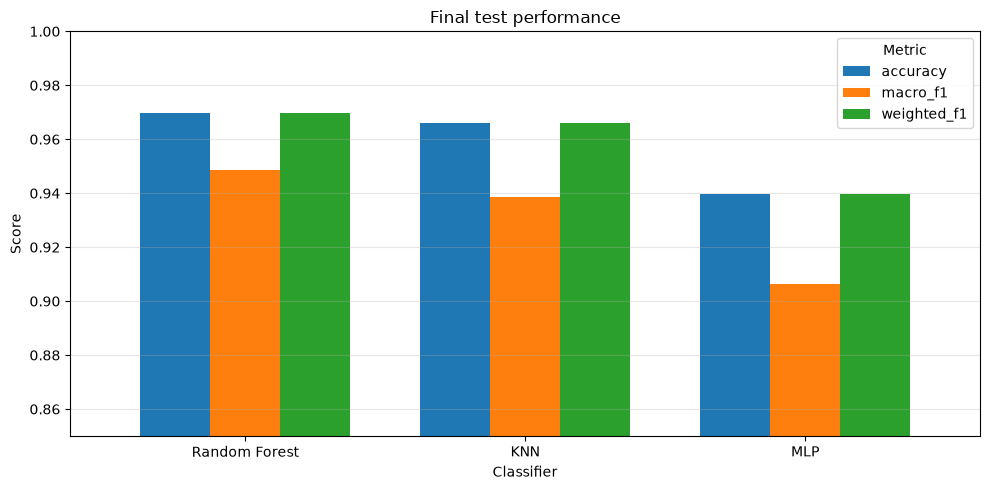

In [81]:

expected_models = {"Random Forest", "KNN", "MLP"}

assert set(test_results) == expected_models
assert set(test_predictions) == expected_models

y_eval = np.asarray(y_test)

evaluation_predictions = {
    name: np.asarray(test_predictions[name])
    for name in ["Random Forest", "KNN", "MLP"]
}

for name, predictions in evaluation_predictions.items():
    assert len(predictions) == len(y_eval), name
    assert np.isclose(
        test_results[name]["macro_f1"],
        f1_score(y_eval, predictions, average="macro")
    ), name

comparison_df = (
    pd.DataFrame(test_results.values())
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df[
    ["model", "accuracy", "macro_f1", "weighted_f1"]
].round(5))

fig, ax = plt.subplots(figsize=(10, 5))

comparison_df.set_index("model")[
    ["accuracy", "macro_f1", "weighted_f1"]
].plot(kind="bar", ax=ax, width=0.75)

ax.set_title("Final test performance")
ax.set_xlabel("Classifier")
ax.set_ylabel("Score")
ax.set_ylim(0.85, 1.0)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

The final test evaluation confirms that Random Forest achieves the highest predictive performance among the three selected classifiers.

All models were retrained on the combined training and validation datasets (493,860 observations) and evaluated on the same test dataset of 87,152 observations.

| Classifier | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Random Forest | **0.96964** | **0.94851** | **0.96962** |
| KNN | 0.96607 | 0.93844 | 0.96605 |
| MLP | 0.93970 | 0.90645 | 0.93959 |

**Random Forest achieves the best overall performance.**

Random Forest obtains 96.96% accuracy and 0.94851 Macro F1, outperforming KNN and MLP on both metrics.

KNN remains competitive, achieving 96.61% accuracy and 0.93844 Macro F1.

The difference between Random Forest and KNN is approximately 0.36 percentage points in accuracy and 0.0101 in Macro F1.

The optimized MLP achieves 93.97% accuracy and 0.90645 Macro F1. Its Macro F1 is approximately 0.0421 below Random Forest.

**Importance of class-balanced evaluation.**

For all three models, Macro F1 is lower than accuracy and weighted F1.

This reflects differences in predictive performance across the seven forest cover types.

Because the dataset is imbalanced, accuracy and weighted F1 are strongly influenced by majority classes. Macro F1 gives equal importance to each class and is therefore more informative for comparing class-balanced performance.

**Consistency with validation results.**

The final ranking is consistent with the validation experiments: Random Forest remains first, followed by KNN and MLP.

Random Forest Macro F1 increases from 0.94517 on validation to 0.94851 on test, while KNN increases from 0.93611 to 0.93844.

MLP decreases from 0.91117 to 0.90645.

These differences cannot be attributed solely to generalization or additional training data, since the final models were trained on a larger dataset and evaluated on different observations.

**Conclusion.**

Random Forest achieves the strongest overall test performance among the selected classifiers.

However, aggregate metrics do not reveal whether this advantage is consistent across individual classes. The following analysis investigates class-specific precision, recall, and F1-score.



### 5.2. Class-Specific Performance

Overall classification metrics do not fully describe model performance across the seven forest cover types.

Because the dataset is imbalanced, minority classes contribute relatively little to overall accuracy, even when they are difficult to classify.

We therefore compare class-specific precision, recall, and F1-scores for the three classifiers using their final test predictions.

For each class, we investigate:

- Which classifier achieves the highest F1-score.
- Whether the overall model ranking is consistent across classes.
- Which classes exhibit the lowest recall.
- Whether certain classifiers offer complementary strengths.

This analysis provides a more detailed assessment of balanced classification performance and helps explain differences in Macro F1.


F1-score by class:


model,KNN,MLP,Random Forest
class,,,
1,0.9662,0.9363,0.9692
2,0.9719,0.9490,0.9746
3,0.9613,0.9389,0.9646
4,0.8780,0.8445,0.8960
5,0.8924,0.8409,0.9254
6,0.9369,0.8913,0.9425
7,0.9624,0.9443,0.9674


Recall by class:


model,KNN,MLP,Random Forest
class,,,
1,0.9675,0.9223,0.9657
2,0.9717,0.9600,0.9771
3,0.9625,0.9293,0.9730
4,0.8738,0.7646,0.8883
5,0.8820,0.8258,0.9143
6,0.9317,0.9125,0.9347
7,0.9607,0.9565,0.9678


Precision by class:


model,KNN,MLP,Random Forest
class,,,
1,0.9650,0.9507,0.9726
2,0.9721,0.9383,0.9722
3,0.9600,0.9486,0.9564
4,0.8824,0.9431,0.9037
5,0.9029,0.8565,0.9367
6,0.9422,0.8710,0.9504
7,0.9641,0.9325,0.9669


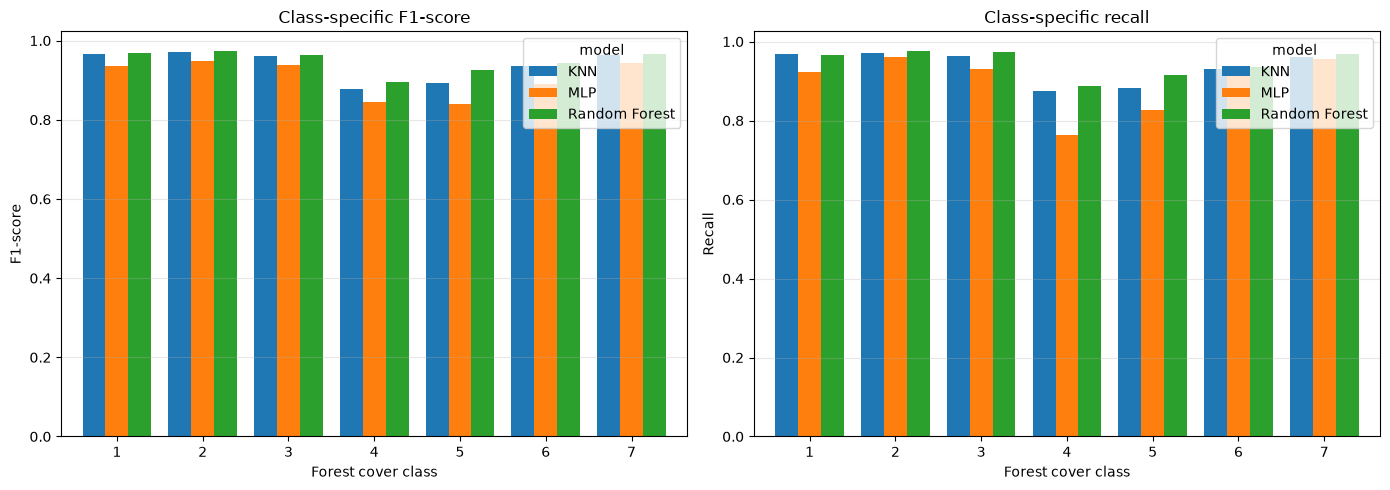

Best classifier for each class:


,best_f1_model,best_f1,best_recall_model,best_recall
class,,,,
1,Random Forest,0.9692,KNN,0.9675
2,Random Forest,0.9746,Random Forest,0.9771
3,Random Forest,0.9646,Random Forest,0.9730
4,Random Forest,0.8960,Random Forest,0.8883
5,Random Forest,0.9254,Random Forest,0.9143
6,Random Forest,0.9425,Random Forest,0.9347
7,Random Forest,0.9674,Random Forest,0.9678


In [ ]:
class_results = []

for name, predictions in evaluation_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_eval,
        predictions,
        labels=classes,
        zero_division=0
    )

    for i, label in enumerate(classes):
        class_results.append({
            "model": name,
            "class": label,
            "precision": precision[i],
            "recall": recall[i],
            "f1": f1[i],
            "support": support[i]
        })

class_df = pd.DataFrame(class_results)

f1_comparison = class_df.pivot(
    index="class", columns="model", values="f1"
)

recall_comparison = class_df.pivot(
    index="class", columns="model", values="recall"
)

precision_comparison = class_df.pivot(
    index="class", columns="model", values="precision"
)

print("F1-score by class:")
display(f1_comparison.round(4))

print("Recall by class:")
display(recall_comparison.round(4))

print("Precision by class:")
display(precision_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

f1_comparison.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Class-specific F1-score")
axes[0].set_xlabel("Forest cover class")
axes[0].set_ylabel("F1-score")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

recall_comparison.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("Class-specific recall")
axes[1].set_xlabel("Forest cover class")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

class_winners = pd.DataFrame({
    "best_f1_model": f1_comparison.idxmax(axis=1),
    "best_f1": f1_comparison.max(axis=1),
    "best_recall_model": recall_comparison.idxmax(axis=1),
    "best_recall": recall_comparison.max(axis=1)
})

print("Best classifier for each class:")
display(class_winners.round(4))



**Results and discussion.**

The class-specific comparison confirms that Random Forest achieves the strongest F1-score on all seven forest cover types in the final test evaluation.

| Class | Random Forest | KNN | MLP |
|---|---:|---:|---:|
| 1 | **0.9692** | 0.9662 | 0.9363 |
| 2 | **0.9746** | 0.9719 | 0.9490 |
| 3 | **0.9646** | 0.9613 | 0.9389 |
| 4 | **0.8960** | 0.8780 | 0.8445 |
| 5 | **0.9254** | 0.8924 | 0.8409 |
| 6 | **0.9425** | 0.9369 | 0.8913 |
| 7 | **0.9674** | 0.9624 | 0.9443 |

**Random Forest performs best across all classes.**

Unlike the validation comparison, where KNN achieved slightly higher F1-scores for classes 3 and 6, Random Forest obtains the highest test F1-score for every class.

Its advantage is particularly noticeable for classes 4 and 5.

For class 4, Random Forest achieves 0.8960 F1, compared with 0.8780 for KNN and 0.8445 for MLP.

For class 5, Random Forest achieves 0.9254 F1, compared with 0.8924 for KNN and 0.8409 for MLP.

This provides additional support for Random Forest's higher Macro F1, demonstrating that its advantage is not restricted to majority classes.

**Minority-class recall remains challenging.**

Class 4 remains the most difficult class for all three classifiers.

Its recall values are:

- Random Forest: 0.8883.
- KNN: 0.8738.
- MLP: 0.7646.

Thus, MLP fails to identify approximately 23.5% of the actual class 4 observations.

Interestingly, MLP achieves the highest precision for class 4 (0.9431), compared with 0.9037 for Random Forest and 0.8824 for KNN.

This indicates that MLP makes relatively few false-positive predictions for class 4, but identifies fewer of its actual observations.

Random Forest achieves a more favorable balance between precision and recall, resulting in the highest F1-score.

**Differences in precision and recall.**

Although Random Forest achieves the highest F1-score across all classes, it does not dominate every individual precision and recall value.

For example, KNN achieves slightly higher recall for class 1 (0.9675) than Random Forest (0.9657).

Similarly, KNN achieves higher precision for class 3 (0.9600) than Random Forest (0.9564).

These differences show that classifiers can exhibit distinct prediction behavior even when one model consistently achieves better F1-scores.

**Conclusion.**

Random Forest provides the most balanced class-specific performance on the test dataset.

Its advantage is particularly relevant for minority classes, which are less influential in overall accuracy but equally important in Macro F1.

Nevertheless, all three classifiers continue to experience difficulties with class 4, and differences in precision and recall suggest that their classification errors may not completely overlap.



### 5.3. Error Overlap and Complementarity

Two classifiers can achieve similar performance metrics while making errors on different observations.

To investigate this behavior, we compare the error sets of the three classifiers on the test dataset.

For each pair of models, we calculate the number of shared errors and the Jaccard similarity:

$$
J(A,B)=\frac{|E_A\cap E_B|}{|E_A\cup E_B|},
$$

where $E_A$ and $E_B$ are the sets of observations incorrectly classified by models $A$ and $B$.

A high Jaccard similarity indicates that two classifiers tend to misclassify the same observations, whereas a low similarity indicates more distinct error sets.

We also investigate:

- The number of observations misclassified by zero, one, two, or all three classifiers.
- The proportion of test observations correctly classified by at least one model.
- The distribution of errors shared by all three models across the seven classes.

This analysis helps characterize prediction complementarity and identify observations that remain challenging independently of the learning approach.

The proportion correctly classified by at least one model is a theoretical oracle upper bound for selecting among these predictions. It is not the performance of an implemented ensemble classifier.


,model,errors,error_rate
0,Random Forest,2646,0.03036
1,KNN,2957,0.03393
2,MLP,5255,0.06030


Shared classification errors:


,Random Forest,KNN,MLP
Random Forest,2646,1278,1741
KNN,1278,2957,1357
MLP,1741,1357,5255


Jaccard similarity:


,Random Forest,KNN,MLP
Random Forest,1.0000,0.2955,0.2826
KNN,0.2955,1.0000,0.1980
MLP,0.2826,0.1980,1.0000


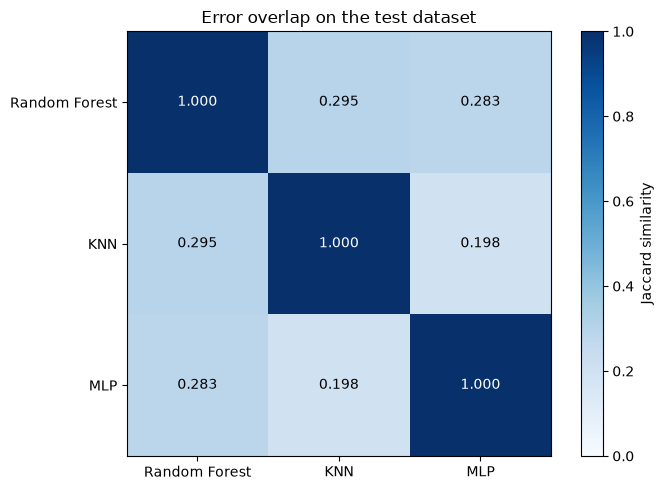

In [83]:

error_masks = {
    name: predictions != y_eval
    for name, predictions in evaluation_predictions.items()
}

error_summary = pd.DataFrame([
    {
        "model": name,
        "errors": int(mask.sum()),
        "error_rate": mask.mean()
    }
    for name, mask in error_masks.items()
])

display(error_summary.round(5))

model_names = list(error_masks)

shared_errors = pd.DataFrame(
    index=model_names, columns=model_names, dtype=int
)
overlap_matrix = pd.DataFrame(
    index=model_names, columns=model_names, dtype=float
)

for name_a in model_names:
    for name_b in model_names:
        mask_a = error_masks[name_a]
        mask_b = error_masks[name_b]

        intersection = int(np.sum(mask_a & mask_b))
        union = int(np.sum(mask_a | mask_b))

        shared_errors.loc[name_a, name_b] = intersection
        overlap_matrix.loc[name_a, name_b] = (
            intersection / union if union else 1.0
        )

print("Shared classification errors:")
display(shared_errors.astype(int))

print("Jaccard similarity:")
display(overlap_matrix.round(4))

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    overlap_matrix.to_numpy(dtype=float),
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(model_names)), model_names)
ax.set_yticks(range(len(model_names)), model_names)

for i in range(len(model_names)):
    for j in range(len(model_names)):
        value = overlap_matrix.iloc[i, j]
        ax.text(
            j, i, f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Jaccard similarity")
ax.set_title("Error overlap on the test dataset")

plt.tight_layout()
plt.show()


,n_models_wrong,observations,proportion
0,0,79765,0.91524
1,1,4821,0.05532
2,2,1661,0.01906
3,3,905,0.01038


Errors shared by all three: 905
At least one classifier correct: 98.9616%


,support,shared_errors,shared_error_rate
1,31776,391,0.01230
2,42495,284,0.00668
3,5363,59,0.01100
4,412,18,0.04369
5,1424,62,0.04354
6,2605,54,0.02073
7,3077,37,0.01202


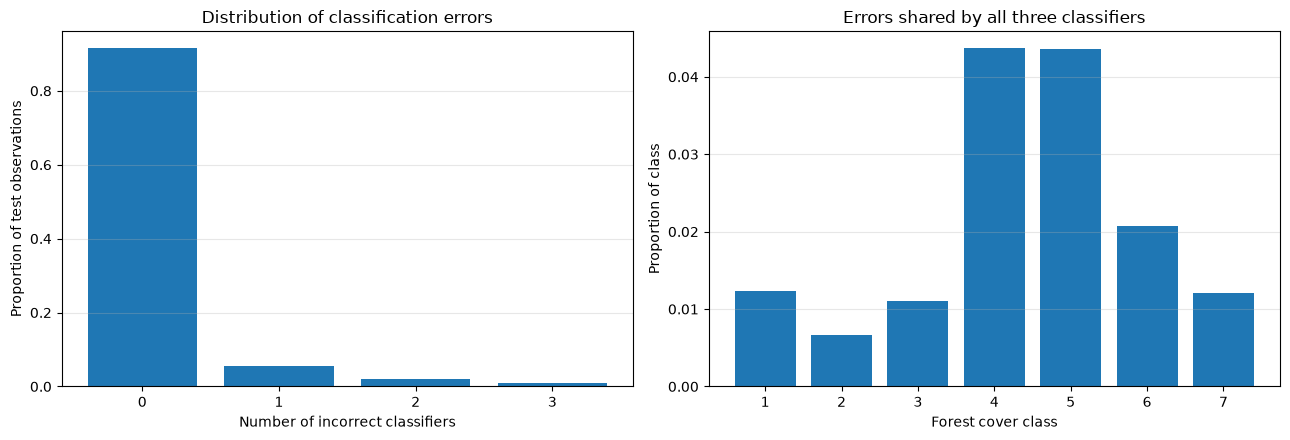

In [84]:

n_wrong = np.column_stack(
    list(error_masks.values())
).sum(axis=1)

error_distribution = pd.DataFrame({
    "n_models_wrong": np.arange(4),
    "observations": np.bincount(n_wrong, minlength=4)
})

error_distribution["proportion"] = (
    error_distribution["observations"] / len(y_eval)
)

display(error_distribution.round(5))

all_wrong = n_wrong == 3
oracle_accuracy = (~all_wrong).mean()

print(f"Errors shared by all three: {all_wrong.sum():,}")
print(f"At least one classifier correct: {oracle_accuracy:.4%}")

shared_error_classes = (
    pd.Series(y_eval[all_wrong])
    .value_counts()
    .reindex(classes, fill_value=0)
)

class_support = (
    pd.Series(y_eval)
    .value_counts()
    .reindex(classes, fill_value=0)
)

shared_error_rates = shared_error_classes / class_support

shared_error_df = pd.DataFrame({
    "support": class_support,
    "shared_errors": shared_error_classes,
    "shared_error_rate": shared_error_rates
})

display(shared_error_df.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(
    error_distribution["n_models_wrong"],
    error_distribution["proportion"]
)
axes[0].set_xticks(range(4))
axes[0].set_xlabel("Number of incorrect classifiers")
axes[0].set_ylabel("Proportion of test observations")
axes[0].set_title("Distribution of classification errors")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    shared_error_rates.index.astype(str),
    shared_error_rates.values
)
axes[1].set_xlabel("Forest cover class")
axes[1].set_ylabel("Proportion of class")
axes[1].set_title("Errors shared by all three classifiers")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



**Results and discussion.**

The error-overlap analysis reveals that the three classifiers make substantially different errors, despite being evaluated on the same test observations.

**Individual classification errors.**

| Classifier | Incorrect predictions | Error rate |
|---|---:|---:|
| Random Forest | **2,646** | **3.036%** |
| KNN | 2,957 | 3.393% |
| MLP | 5,255 | 6.030% |

Random Forest makes the fewest errors, followed by KNN and MLP, consistently with their overall accuracy ranking.

**Pairwise error overlap.**

| Model pair | Shared errors | Jaccard similarity |
|---|---:|---:|
| Random Forest / KNN | 1,278 | 0.2955 |
| Random Forest / MLP | 1,741 | 0.2826 |
| KNN / MLP | 1,357 | 0.1980 |

The relatively low Jaccard similarities indicate that the classifiers do not systematically misclassify the same observations.

The lowest similarity is observed between KNN and MLP (0.1980), suggesting that their error sets are particularly different.

However, the Jaccard index depends on both the overlap and the overall number of errors. It should therefore be interpreted as a descriptive similarity measure rather than a direct indicator of potential ensemble performance.

**Distribution of classification errors.**

| Number of incorrect classifiers | Observations | Proportion |
|---|---:|---:|
| 0 | 79,765 | 91.524% |
| 1 | 4,821 | 5.532% |
| 2 | 1,661 | 1.906% |
| 3 | 905 | 1.038% |

Most test observations are correctly classified by all three classifiers.

Only 905 observations, representing approximately 1.04% of the test dataset, are incorrectly classified by all three models.

Consequently, at least one classifier predicts the correct label for **98.9616% of the test observations**.

This result represents the performance of a theoretical oracle capable of selecting a correct prediction whenever at least one model provides one.

It is not the performance of an implemented ensemble, since a practical model cannot know in advance which prediction is correct.

Nevertheless, it suggests that the different classification approaches produce partially complementary predictions.

**Distribution of shared errors across classes.**

The observations misclassified by all three models are not uniformly distributed across the seven classes.

The highest class-relative shared error rates are observed for:

- Class 4: 4.37%.
- Class 5: 4.35%.
- Class 6: 2.07%.

In contrast, the shared error rates are below 1% for class 2.

This reinforces the conclusions of the class-specific analysis: classes 4 and 5 remain particularly challenging, independently of the classifier.

The high shared error rates could reflect overlapping feature distributions, limited representation of minority classes, or other dataset characteristics.

However, the present analysis does not establish the underlying causes.

**Potential complementarity.**

The differences between error sets suggest that combining predictions could be an interesting direction for future work.

In particular, the 6,482 observations misclassified by only one or two models demonstrate that the classifiers sometimes succeed on observations where other models fail.

However, the results do not demonstrate that a conventional voting or stacking ensemble would improve performance.

Evaluating such a strategy would require a separately designed experiment, without using test labels to optimize the ensemble.

**Conclusion.**

The three classifiers exhibit partially complementary error patterns, although they share persistent difficulties on certain minority classes.

Random Forest remains the strongest individual classifier, but the analysis shows that the learning approaches capture different aspects of the classification problem.

These results motivate potential future investigations into model combination, while preserving the distinction between descriptive oracle performance and achievable predictive performance.



### 5.4. Computational Efficiency

Predictive performance is not the only criterion when selecting a classification model. Training and inference costs also affect practical usability.

The three classifiers have different computational characteristics:

- **Random Forest:** requires constructing an ensemble of decision trees, but supports efficient prediction through tree traversal.
- **KNN:** requires minimal fitting time, but inference involves nearest-neighbor searches against the stored training observations.
- **MLP:** requires iterative gradient-based optimization, but performs inference through a fixed sequence of matrix operations.

We compare the measured training and inference times of the final models.

All classifiers were fitted on the combined training and validation datasets and evaluated on the same test dataset.

We also calculate the average inference time per observation, derived from batch prediction measurements.

These measurements depend on the hardware, implementation, parallelization strategy, and evaluation procedure. In particular, KNN predictions were performed in batches to limit memory usage.

The reported times should therefore be interpreted as practical computational benchmarks rather than universal measures of algorithmic efficiency.


,model,train_time_s,predict_time_s,predict_ms_per_sample,macro_f1
0,Random Forest,52.68379,0.50914,0.00584,0.94851
1,KNN,0.07202,480.97937,5.51886,0.93844
2,MLP,706.76348,0.21603,0.00248,0.90645


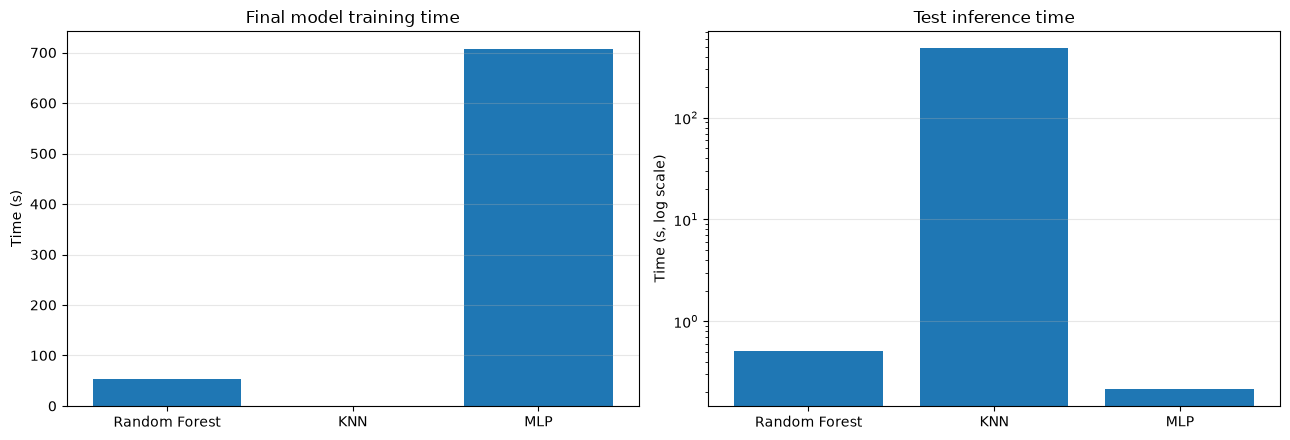

In [85]:

cost_df = comparison_df[
    ["model", "train_time_s", "predict_time_s", "macro_f1"]
].copy()

cost_df["predict_ms_per_sample"] = (
    1000 * cost_df["predict_time_s"] / len(y_eval)
)

display(cost_df[
    ["model", "train_time_s", "predict_time_s",
     "predict_ms_per_sample", "macro_f1"]
].round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(
    cost_df["model"],
    cost_df["train_time_s"]
)
axes[0].set_title("Final model training time")
axes[0].set_ylabel("Time (s)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    cost_df["model"],
    cost_df["predict_time_s"]
)
axes[1].set_yscale("log")
axes[1].set_title("Test inference time")
axes[1].set_ylabel("Time (s, log scale)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


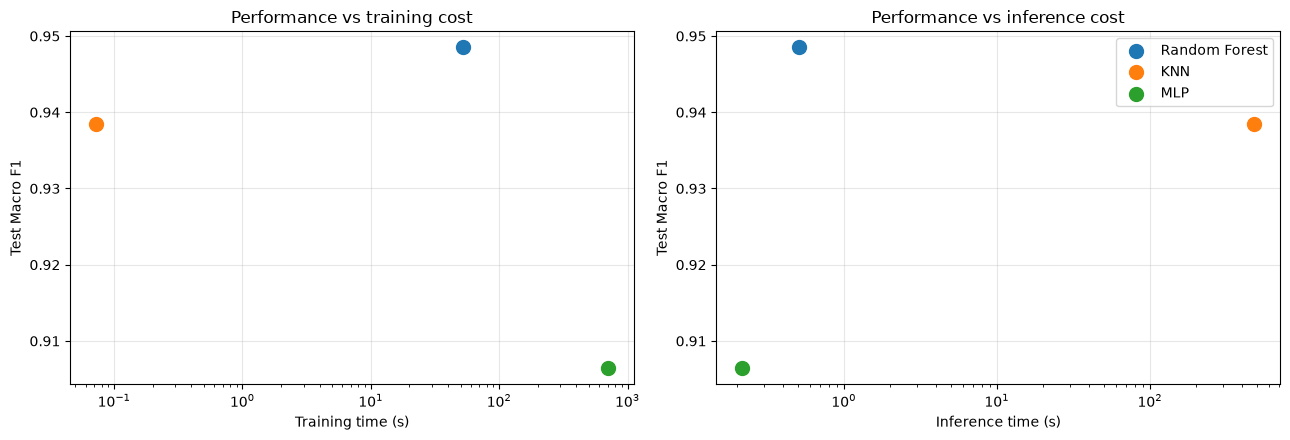

In [86]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for _, row in cost_df.iterrows():
    axes[0].scatter(
        row["train_time_s"],
        row["macro_f1"],
        s=100,
        label=row["model"]
    )
    axes[1].scatter(
        row["predict_time_s"],
        row["macro_f1"],
        s=100,
        label=row["model"]
    )

axes[0].set_xlabel("Training time (s)")
axes[0].set_ylabel("Test Macro F1")
axes[0].set_title("Performance vs training cost")
axes[0].set_xscale("log")
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Inference time (s)")
axes[1].set_ylabel("Test Macro F1")
axes[1].set_title("Performance vs inference cost")
axes[1].set_xscale("log")
axes[1].grid(alpha=0.3)

axes[1].legend()

plt.tight_layout()
plt.show()



**Results and discussion.**

The computational benchmarks reveal substantial differences between the three selected classifiers.

All models were fitted using the combined training and validation datasets (493,860 observations), and inference was measured on the same test dataset of 87,152 observations.

| Classifier | Training time | Prediction time | Mean prediction time per observation |
|---|---:|---:|---:|
| Random Forest | 52.68 s | 0.509 s | 0.00584 ms |
| KNN | **0.072 s** | 480.98 s | 5.51886 ms |
| MLP | 706.76 s | **0.216 s** | **0.00248 ms** |

**Training efficiency.**

KNN has negligible fitting cost because it primarily stores the training observations.

Random Forest requires approximately 53 seconds to build an ensemble of 300 decision trees.

The MLP requires approximately 707 seconds of training, corresponding to 107 epochs of iterative optimization.

Although the final MLP training dataset is larger than the one used in the previous validation experiment, its training time is lower.

The previous MLP performed 195 epochs, while the final model stops after 107 epochs.

This illustrates that total training time depends not only on dataset size and network architecture, but also on convergence behavior and the early stopping criterion.

**Inference efficiency.**

MLP achieves the fastest batch inference, requiring approximately 0.216 seconds for the complete test dataset.

Random Forest also provides efficient inference, requiring approximately 0.509 seconds.

KNN requires approximately 481 seconds, or roughly 8 minutes, to classify the same observations.

Under the measured conditions, KNN inference is approximately 945 times slower than Random Forest and over 2,200 times slower than MLP.

This difference is consistent with brute-force nearest-neighbor search, which requires computing distances between test observations and stored training samples.

**Performance–cost trade-off.**

Random Forest offers the strongest overall compromise between predictive performance and computational efficiency.

It achieves the highest test Macro F1 (0.94851), while requiring moderate training time and very little inference time.

MLP is the fastest model during inference but requires substantially more training time and achieves lower Macro F1.

KNN achieves competitive predictive performance with minimal fitting cost, but its expensive inference makes it less suitable when large numbers of predictions must be generated.

**Measurement limitations.**

The computational measurements reflect the specific hardware, implementations, and prediction procedures used.

KNN predictions were performed in batches of 2,000 observations to limit memory usage.

The measured average prediction time per observation is therefore a batch-throughput measure, not necessarily the latency of an isolated prediction.

Moreover, the timings do not include the complete computational cost of hyperparameter optimization.

**Conclusion.**

Random Forest provides the best combination of predictive performance, training efficiency, and inference efficiency for the present task.

MLP is preferable when inference speed is the primary consideration and training cost is less important.

KNN is attractive when fitting time is critical, but its inference cost represents a substantial limitation for large datasets.



### 5.5. Overall Discussion and Conclusions

This project investigated three supervised learning approaches for predicting forest cover types from geographical and cartographic features: Random Forest, K-Nearest Neighbors (KNN), and Multi-Layer Perceptron (MLP).

The methodology included exploratory data analysis, feature preprocessing, hyperparameter optimization, studies of model complexity and training dataset size, and final evaluation on a test dataset.

The selected configurations were retrained on the combined training and validation datasets before the final evaluation.

**Overall predictive performance.**

Random Forest achieves the strongest test performance, with **96.96% accuracy and 0.94851 Macro F1**, followed by KNN (0.93844 Macro F1) and MLP (0.90645 Macro F1).

This ranking is consistent with the validation results, suggesting that the relative strengths of the selected classifiers remain similar on the test dataset.

The results confirm that all three approaches can achieve strong predictive performance on the Covertype dataset, although substantial differences remain in class-balanced classification quality.

**Class-specific performance.**

Random Forest obtains the highest test F1-score on all seven forest cover classes.

Its advantage is especially relevant for classes 4 and 5, which are among the most difficult to distinguish.

Nevertheless, class 4 remains challenging even for Random Forest, which achieves a recall of 0.8883.

The differences between accuracy and Macro F1 highlight the importance of class-specific evaluation when working with imbalanced datasets.

**Preprocessing and model complexity.**

The experiments demonstrate that different learning algorithms require different preprocessing and optimization strategies.

Random Forest performs best with a sufficiently large ensemble, unrestricted tree depth, moderate feature sampling, and partial class weighting.

KNN achieves its best performance using one nearest neighbor, Manhattan distance, and the original feature representation without scaling or dimensionality reduction.

MLP is substantially more sensitive to feature scaling and network architecture. Numerical standardization and systematic architecture exploration significantly improve its performance, with the selected three-layer network outperforming the initial two-layer configuration.

PCA does not improve the selected configurations in the experiments conducted. Additional MLP feature engineering, including cyclic encoding of Aspect, also fails to improve the primary evaluation metric.

These results illustrate that preprocessing choices must be adapted to the classifier rather than considered universally beneficial.

**Influence of training dataset size.**

All three approaches benefit from increasing the number of training observations, although the computational consequences differ.

Random Forest continues to improve as additional training observations become available.

KNN also benefits considerably from additional data, but its marginal performance gains decrease at larger dataset sizes while inference cost continues to grow.

The MLP learning-curve experiments show substantial improvements with increasing dataset size, although these experiments were conducted using the initially selected two-layer architecture rather than the final three-layer model.

These observations demonstrate the importance of training data availability for classification performance.

**Error complementarity.**

The final error-overlap analysis reveals that the classifiers do not systematically make errors on the same observations.

Only 905 of the 87,152 test observations are misclassified by all three classifiers, and at least one model predicts the correct label for 98.9616% of observations.

This suggests partially complementary prediction behavior.

However, this theoretical oracle result does not correspond to an implemented ensemble.

Furthermore, classes 4 and 5 exhibit the highest class-relative shared error rates, indicating persistent classification difficulties across the three learning approaches.

**Computational efficiency.**

The models exhibit markedly different training and inference costs.

KNN requires negligible fitting time but approximately 481 seconds to classify the test dataset.

MLP requires approximately 707 seconds of training but only 0.216 seconds for inference.

Random Forest requires approximately 53 seconds of training and 0.509 seconds for prediction.

Random Forest therefore provides a particularly favorable compromise between classification quality and computational efficiency.

**Methodological limitations.**

Several limitations must be acknowledged.

First, hyperparameter optimization was not equally extensive across the three classifiers. The selected configurations should therefore not be interpreted as globally optimal.

Second, repeated use of the validation dataset during model development may introduce selection bias.

Third, some exploratory experiments were performed on reduced subsets to limit computational cost. Their conclusions may not transfer exactly to the complete dataset.

Fourth, computational measurements depend on the hardware, software implementation, parallelization settings, and prediction procedures.

Finally, an earlier Random Forest experiment had already examined the test dataset. Therefore, the test set cannot be described as completely unseen throughout the entire project, even though the final configurations were fixed before the evaluations presented here.

Consequently, the reported results support a comparison of the selected configurations under the experimental protocol, rather than a definitive ranking of the maximum achievable performance of each algorithm.

**Final model selection.**

Based on the validation-based selection process, confirmed by the final test evaluation, **Random Forest is the preferred classifier**.

It achieves the highest test Macro F1 (0.94851), the highest accuracy (0.96964), and the strongest F1-score on every class, while maintaining relatively low computational costs.

KNN remains a competitive alternative in predictive performance but is limited by expensive inference.

MLP offers very efficient inference and demonstrates the importance of architecture optimization, but its lower Macro F1 and higher training cost make it less attractive for the present task.

**Future work.**

Possible extensions include investigating alternative approaches to class imbalance, evaluating more advanced neural network architectures, and studying whether model combination can exploit the partially complementary error patterns.

Any further model development should be evaluated using an independent assessment protocol rather than optimizing configurations on the existing test results.

**Overall, Random Forest provides the strongest balance of predictive performance, class-specific reliability, and computational efficiency among the three approaches investigated in this project.**
